# Title: NACA 65 series

**Source:** Aungier, *Axial Flow Compressors*
**Current:** NACA 65-(12A10)-10
**Purpose:** 2D blade generation, cascade construction, solver-ready smooth geometry, extension to DCA, C4 and custom profiles.

The geometry module was developed as the geometric front-end of a blade-to-blade potential-flow solver. Particular attention was given to surface continuity because geometric derivatives enter the solver metrics and PDE coefficients.

In [1]:
# Setup: find the folder that holds potential_flow_solver/ and import the geometry module.
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, PchipInterpolator


def repository_root(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / "potential_flow_solver" / "geometry.py").is_file():
            return folder
    raise FileNotFoundError(f"potential_flow_solver/geometry.py not found above {start}")


sys.path.insert(0, str(repository_root(Path.cwd().resolve())))

from potential_flow_solver import geometry as geo
from potential_flow_solver.geometry import CascadeSpec

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 2. User inputs

All the parametric NACA 65 inputs are in one `CascadeSpec`. The geometry is **normalized: chord c = 1**. Every length is a fraction of the chord ($x/c$, $y/c$, $t/c$, $R_{LE}/c$), the pitch is $s = c/\sigma$, and angles are in degrees on input.

`physical_chord=None` keeps the blade normalized. A physical chord (in metres) is a later step: it scales the same $c = 1$ blade uniformly, so coordinates scale with $c$, curvature with $1/c$, and angles do not change.

$R_{LE}$ is shown with the inputs but is not a free input in the NACA 65 family: it is fixed by the thickness, $R_{LE}/c = 0.00687\,(t_{max}/c \,/\, 0.10)^2$ (the 65-010 value of Aungier Table 4-1, scaled with the thickness squared).

In [2]:
# ---- User inputs: NACA 65 blade and cascade --------------------------------------------
# Normalized geometry: chord c = 1. Every length is a fraction of the chord.
# physical_chord = None keeps it normalized; a physical chord in metres comes later (a uniform scale).

spec = CascadeSpec(
    blade_type="NACA65",                  # blade family ("DCA" and "C4" are in the API, not built yet)
    solidity=1.0,                         # sigma = c / s, chord over pitch
    stagger_deg=33.0,                     # stagger angle from the axial direction, deg
    cl0=1.2,                              # design lift coefficient: the "12" of 65-(12A10)10
    t_max_over_c=0.10,                    # nominal maximum thickness ratio: the "10"
    meanline_type="A10",                  # a = 1.0 mean line
    profile_variant="kovach_sandercock",  # TE: "kovach_sandercock" (rounded, R_TE = 0.008 c) or "emery_base" (sharp)
    surface_continuity="C1",              # "C1": validated legacy baseline; "C2": smooth, solver-ready surfaces
    physical_chord=None,                  # None: normalized geometry, c = 1
    n_camber_stations=101,                # camberline stations: resolution of the camberline and the surfaces
)

# LE radius: fixed by the thickness in the NACA 65 family (65-010 table value, scaled with t^2).
R_le = geo.TABLE_LE_RADIUS * (spec.t_max_over_c / geo.TABLE_T_MAX) ** 2      # R_LE / c

chord = 1.0                                                                 # normalized
pitch = chord / spec.solidity
designation = f"NACA 65-({10 * spec.cl0:g}{spec.meanline_type}){100 * spec.t_max_over_c:g}"

print(f"{designation}   profile variant: {spec.profile_variant}   surface continuity: {spec.surface_continuity}")
print(f"chord c = {chord:g} (normalized)   pitch s = c / solidity = {pitch:g}   stagger = {spec.stagger_deg:g} deg")
print(f"R_LE / c = {R_le:.5f}")

NACA 65-(12A10)10   profile variant: kovach_sandercock   surface continuity: C1
chord c = 1 (normalized)   pitch s = c / solidity = 1   stagger = 33 deg
R_LE / c = 0.00687


## 3. NACA 65 source data — thickness distribution

NACA 65 geometry is not generated from a single closed-form thickness equation. The thickness distribution is reconstructed from tabulated normalized coordinates.

- **Data:** the NACA 65-010 thickness column of Aungier Table 4-1 (from Emery et al. 1958), $t/c$ at 26 stations from 0 to 100 %. The 2.5 % value is misprinted as 3.480 %; the module uses the corrected 3.148 % (twice the standard 65-010 half-ordinate 1.574 %).
- **Scaling:** another thickness scales the 10 % column by $t_{max}/0.10$. The table maximum, 0.09992 at station 0.40, is kept and not renormalized to 0.10.
- **Station:** the table station is the arc-length fraction $s/S$ along the camberline, not $x/c$ (Aungier Sec. 4.1).
- **Reconstruction:** PCHIP (piecewise cubic Hermite) of the half thickness in $\sqrt{s/S}$. A nose that grows like $\sqrt{x}$ is nearly straight in $\sqrt{x}$.

**PCHIP is shape-preserving but only C1.** It cannot overshoot between the table points: no spurious bumps at the blunt nose or the thin TE. But it is only once continuously differentiable: $dt/ds$ is continuous, while $d^2t/ds^2$ jumps at every table station (lower panel). Through the surface construction those jumps become curvature jumps of the blade surfaces, the C1 baseline. The C2 representation smooths them later.

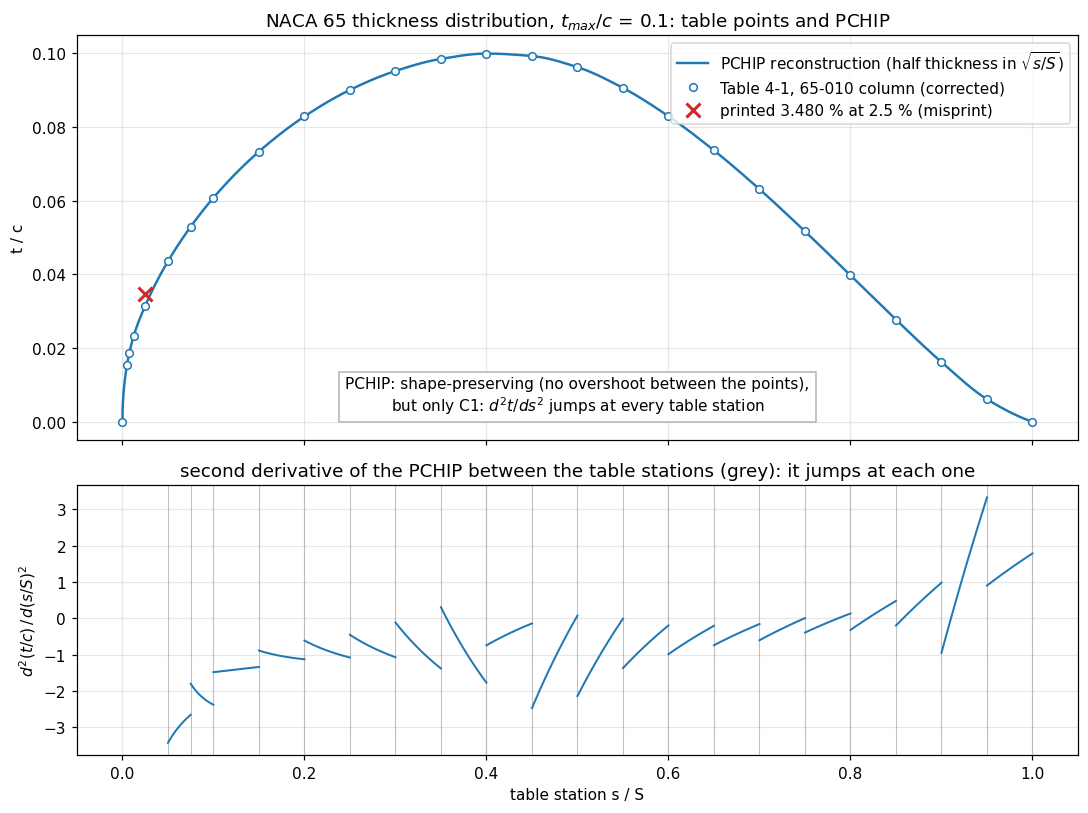

jump of d2t/ds2 at the stations from s/S = 0.075 on: largest 2.428 at s/S = 0.95


In [3]:
tables = geo.base_tables()
scale = geo.thickness_scale(spec.t_max_over_c)
station_table = tables.x                                   # table stations s/S
t_table = scale * tables.thickness_corrected               # t/c at the stations
misprint = np.isclose(station_table, 0.025)

# The module's PCHIP, rebuilt here from the public table: half thickness against sqrt(s/S).
pchip = PchipInterpolator(np.sqrt(station_table), 0.5 * scale * tables.thickness_corrected)
station = np.linspace(0.0, 1.0, 4001)
t_pchip = 2.0 * pchip(np.sqrt(station))
assert np.allclose(t_pchip, geo.naca65_base_thickness(station, spec.t_max_over_c, thickness_reconstruction="pchip_sqrt"), rtol=0.0, atol=1e-15)


def second_derivative(s):
    # t(s) = 2 B(z), z = sqrt(s):  t'' = 2 (B'' - B'/z) / (4 s), on the PCHIP piece that holds s
    z = np.sqrt(s)
    return 2.0 * (pchip(z, 2) - pchip(z, 1) / z) / (4.0 * s)


fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 7.5), height_ratios=(3, 2), sharex=True)
ax.plot(station, t_pchip, "-", lw=1.6, label="PCHIP reconstruction (half thickness in $\\sqrt{s/S}$)")
ax.plot(station_table, t_table, "o", ms=5, mfc="white", color="tab:blue", label="Table 4-1, 65-010 column (corrected)")
ax.plot(station_table[misprint], scale * tables.thickness_printed[misprint], "x", ms=9, mew=2, color="tab:red",
        label="printed 3.480 % at 2.5 % (misprint)")
ax.set_ylabel("t / c")
ax.set_title(f"NACA 65 thickness distribution, $t_{{max}}/c$ = {spec.t_max_over_c:g}: table points and PCHIP")
ax.text(0.5, 0.06, "PCHIP: shape-preserving (no overshoot between the points),\n"
        "but only C1: $d^2t/ds^2$ jumps at every table station", transform=ax.transAxes, ha="center", va="bottom",
        bbox=dict(facecolor="white", edgecolor="0.7"))
ax.legend(loc="upper right")

first = 0.05                                               # the sqrt nose makes t'' ~ s^(-3/2) below this
for a, b in zip(station_table[:-1], station_table[1:]):
    if a < first:
        continue
    s = np.linspace(a, b, 80)[1:-1]
    s = np.concatenate(([a + 1e-9 * (b - a)], s, [b - 1e-9 * (b - a)]))   # each piece up to, not across, its stations
    ax2.plot(s, second_derivative(s), color="tab:blue", lw=1.3)
for value in station_table[station_table >= first]:
    ax2.axvline(value, color="0.75", lw=0.7, zorder=0)
ax2.set_ylabel("$d^2(t/c)\\,/\\,d(s/S)^2$")
ax2.set_xlabel("table station s / S")
ax2.set_title("second derivative of the PCHIP between the table stations (grey): it jumps at each one")
fig.tight_layout()
plt.show()

inner = station_table[(station_table >= first) & (station_table < 1.0)][1:]
jumps = [second_derivative(np.array([v + 1e-9]))[0] - second_derivative(np.array([v - 1e-9]))[0] for v in inner]
print("jump of d2t/ds2 at the stations from s/S = 0.075 on: largest", f"{max(np.abs(jumps)):.3f}",
      "at s/S =", inner[int(np.argmax(np.abs(jumps)))])

## 4. A10 camberline construction

The NACA $a = 1.0$ ("A10") mean line, in closed form. Thin-airfoil theory; Table 4-1 tabulates its $c_{l0} = 1$ line, and the ordinates scale with $c_{l0}$:

$$\frac{y_c}{c} = -\frac{c_{l0}}{4\pi}\Big[(1-x)\ln(1-x) + x\ln x\Big], \qquad \frac{dy_c}{dx} = \frac{c_{l0}}{4\pi}\ln\frac{1-x}{x}, \qquad x = x/c$$

Its slope is logarithmically infinite at both ends, so it gives no usable metal angles at the LE and TE. Two camberlines therefore appear, with different roles:

- **actual NACA A10 camberline → geometry construction.** The blade surfaces are laid off from it (section 5).
- **equivalent circular arc → angle/performance interpretation.** It is the arc through the LE and TE with camber angle $\theta$, $\tan(\theta/4) = 0.1103\,c_{l0}$ (Aungier Eq. 4-6). It gives $\chi_{le} = \chi_{te} = \theta/2$ and the blade angles $\kappa_{le} = \gamma + \chi_{le}$, $\kappa_{te} = \gamma - \chi_{te}$ used in the incidence, deviation and loss correlations.

The equivalent circular arc is not used to replace the physical A10 camberline in the baseline NACA65 geometry.

equivalent arc: camber angle theta = 30.159 deg,  chi_le = chi_te = 15.080 deg
blade angles:   kappa_le = stagger + chi_le = 48.080 deg,  kappa_te = stagger - chi_te = 17.920 deg
max camber:     A10 0.06619 c at x/c = 0.500,  arc 0.06618 c at x/c = 0.500
A10 closed form against Table 4-1 x c_l0: largest difference 2.7e-05 c


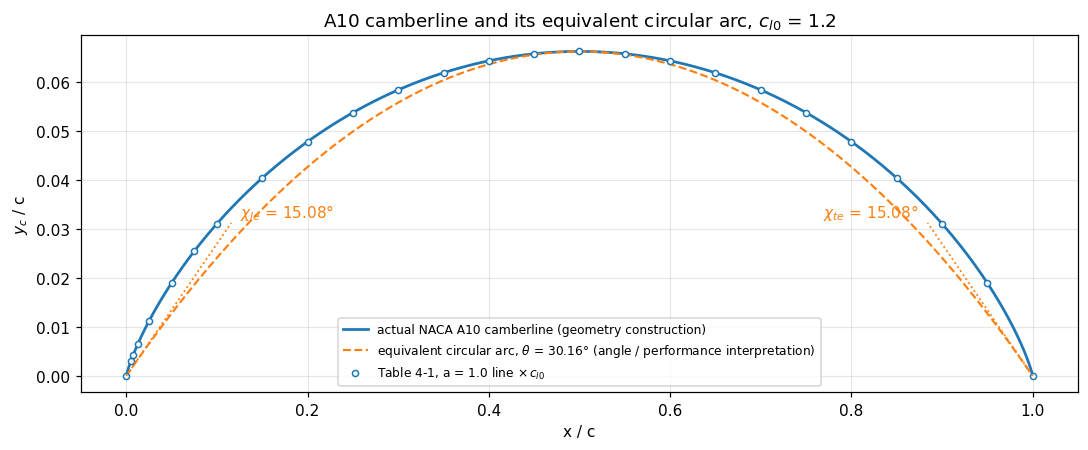

In [4]:
x = 0.5 * (1.0 - np.cos(np.linspace(0.0, np.pi, 401)))      # cosine-clustered x/c
y_a10 = geo.a10_camberline(x, spec.cl0)
camber_angle, chi_le, chi_te = geo.equivalent_arc_angles(spec.cl0)
y_arc = geo.circular_arc_camberline(x, camber_angle)
y_table = spec.cl0 * tables.camber                           # Table 4-1 (c_l0 = 1 line) times c_l0
stagger = np.radians(spec.stagger_deg)

print(f"equivalent arc: camber angle theta = {np.degrees(camber_angle):.3f} deg,  chi_le = chi_te = {np.degrees(chi_le):.3f} deg")
print(f"blade angles:   kappa_le = stagger + chi_le = {np.degrees(stagger + chi_le):.3f} deg,  "
      f"kappa_te = stagger - chi_te = {np.degrees(stagger - chi_te):.3f} deg")
print(f"max camber:     A10 {y_a10.max():.5f} c at x/c = {x[y_a10.argmax()]:.3f},  arc {y_arc.max():.5f} c at x/c = {x[y_arc.argmax()]:.3f}")
print(f"A10 closed form against Table 4-1 x c_l0: largest difference "
      f"{np.max(np.abs(geo.a10_camberline(tables.x, spec.cl0) - y_table)):.1e} c")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(x, y_a10, lw=1.8, label="actual NACA A10 camberline (geometry construction)")
ax.plot(x, y_arc, "--", lw=1.4, color="tab:orange",
        label=f"equivalent circular arc, $\\theta$ = {np.degrees(camber_angle):.2f}° (angle / performance interpretation)")
ax.plot(tables.x, y_table, "o", ms=4, mfc="white", color="tab:blue", label="Table 4-1, a = 1.0 line $\\times\\,c_{l0}$")
length = 0.12                                                # end tangents of the arc: angle chi to the chord
for x0, sign, chi, name in ((0.0, 1.0, chi_le, "$\\chi_{le}$"), (1.0, -1.0, chi_te, "$\\chi_{te}$")):
    ax.plot([x0, x0 + sign * length * np.cos(chi)], [0.0, length * np.sin(chi)], ":", color="tab:orange", lw=1.2)
    ax.annotate(f"{name} = {np.degrees(chi):.2f}°", (x0 + sign * length * np.cos(chi), length * np.sin(chi)),
                textcoords="offset points", xytext=(sign * 6, 4), ha="left" if sign > 0 else "right",
                color="tab:orange")
ax.set_xlabel("x / c")
ax.set_ylabel("$y_c$ / c")
ax.set_title(f"A10 camberline and its equivalent circular arc, $c_{{l0}}$ = {spec.cl0:g}")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

## 5. Thickness + camberline → SS / PS

The surfaces are the camberline offset by half the thickness along its unit normal:

$$\mathbf X_{SS/PS}(s) = \mathbf X_c(s) \pm \frac{t(s)}{2}\,\mathbf n(s)$$

and the normal vector:

$$\mathbf n = \frac{1}{\sqrt{1+y_c'^2}}\begin{bmatrix} -y_c' \\ 1 \end{bmatrix}$$

The plus sign gives the suction side, the minus sign the pressure side. $\mathbf X_c = (x, y_c)$ is the A10 camberline of section 4, and $t(s)$ is the PCHIP thickness of section 3 read at the station $s/S$, the arc-length fraction along the camberline. With $\phi = \arctan y_c'$ the normal is $\mathbf n = (-\sin\phi, \cos\phi)$, so

$$x_{SS} = x - \tfrac{t}{2}\sin\phi,\quad y_{SS} = y_c + \tfrac{t}{2}\cos\phi, \qquad x_{PS} = x + \tfrac{t}{2}\sin\phi,\quad y_{PS} = y_c - \tfrac{t}{2}\cos\phi$$

Here the table thickness runs over the whole chord with no LE or TE treatment. The nose is still open: the mean-line slope is infinite at $x = 0$, and ahead of station 0.005 the construction uses the LE circle instead. The Kovach–Sandercock TE also modifies the thickness aft of station 0.60. Those are the next steps: LE and TE construction.

SS: module C1 surface against X_c +- (t/2) n over x/c 0.02-0.55: largest |dy| = 1.4e-17 c
PS: module C1 surface against X_c +- (t/2) n over x/c 0.02-0.55: largest |dy| = 1.1e-17 c


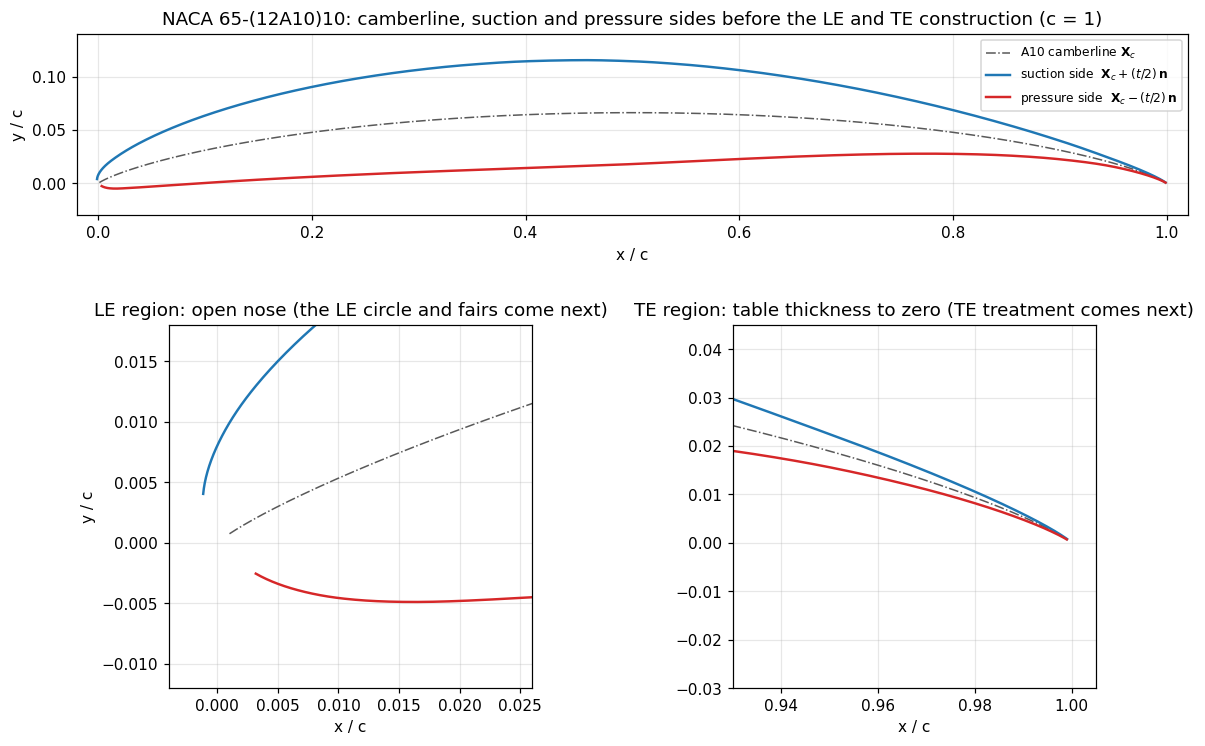

In [5]:
def camberline_and_surfaces(n_points):
    # X_c and X_c +- (t/2) n at n_points cosine-clustered camber stations, kept XI_MIN away from
    # x = 0 and 1, where the mean-line slope is singular.
    edge = np.arccos(1.0 - 2.0 * geo.XI_MIN)
    x = 0.5 * (1.0 - np.cos(np.linspace(edge, np.pi - edge, n_points)))
    y_c = geo.a10_camberline(x, spec.cl0)
    slope = spec.cl0 / (4.0 * np.pi) * np.log((1.0 - x) / x)                   # y_c'
    normal = np.column_stack((-slope, np.ones_like(x))) / np.sqrt(1.0 + slope**2)[:, None]
    s_over_S = geo.camberline_station(x, spec.cl0)                              # table station of each camber point
    t = geo.naca65_base_thickness(s_over_S, spec.t_max_over_c, thickness_reconstruction="pchip_sqrt")                  # t/c from section 3
    X_c = np.column_stack((x, y_c))
    return X_c, X_c + 0.5 * t[:, None] * normal, X_c - 0.5 * t[:, None] * normal


X_c, X_ss, X_ps = camberline_and_surfaces(2001)        # drawing resolution, finer than n_camber_stations

# Check against the module: its C1 surfaces lie on these curves between the LE closure and
# the Kovach start (x/c 0.02 .. 0.55), where neither LE nor TE treatment acts.
profile = geo.naca65_profile(spec.cl0, spec.t_max_over_c, meanline_type=spec.meanline_type,
                             profile_variant=spec.profile_variant, n_camber_stations=spec.n_camber_stations, thickness_reconstruction="pchip_sqrt")
_, dense_ss, dense_ps = camberline_and_surfaces(40001)
for name, mine, theirs in (("SS", dense_ss, profile.suction_surface), ("PS", dense_ps, profile.pressure_surface)):
    rows = (theirs[:, 0] > 0.02) & (theirs[:, 0] < 0.55)
    keep = (mine[:, 0] > 0.01) & (mine[:, 0] < 0.6)                 # x increases along both surfaces here
    gap = np.max(np.abs(CubicSpline(mine[keep, 0], mine[keep, 1])(theirs[rows, 0]) - theirs[rows, 1]))
    print(f"{name}: module C1 surface against X_c +- (t/2) n over x/c 0.02-0.55: largest |dy| = {gap:.1e} c")

fig = plt.figure(figsize=(11, 7.5))
top = fig.add_subplot(2, 1, 1)
le = fig.add_subplot(2, 2, 3)
te = fig.add_subplot(2, 2, 4)
for ax in (top, le, te):
    ax.plot(*X_c.T, "-.", color="0.35", lw=1.0, label="A10 camberline $\\mathbf{X}_c$")
    ax.plot(*X_ss.T, color="tab:blue", lw=1.6, label="suction side  $\\mathbf{X}_c + (t/2)\\,\\mathbf{n}$")
    ax.plot(*X_ps.T, color="tab:red", lw=1.6, label="pressure side  $\\mathbf{X}_c - (t/2)\\,\\mathbf{n}$")
    ax.set_aspect("equal", adjustable="box")
top.set_title(f"{designation}: camberline, suction and pressure sides before the LE and TE construction (c = 1)")
top.set_xlim(-0.02, 1.02); top.set_ylim(-0.03, 0.14)
top.set_xlabel("x / c"); top.set_ylabel("y / c")
top.legend(loc="upper right", fontsize=8)
le.set_xlim(-0.004, 0.026); le.set_ylim(-0.012, 0.018)
le.set_title("LE region: open nose (the LE circle and fairs come next)")
le.set_xlabel("x / c"); le.set_ylabel("y / c")
te.set_xlim(0.93, 1.005); te.set_ylim(-0.03, 0.045)
te.set_title("TE region: table thickness to zero (TE treatment comes next)")
te.set_xlabel("x / c")
fig.tight_layout()
plt.show()

## 6. TE construction

The table thickness gives a **sharp TE**: zero thickness, two surfaces meeting at a wedge at $(1, 0)$. This is the `"emery_base"` variant, where each surface ends with a short straight closing segment from $x/c = 0.999$ to the TE point. **A sharp TE cannot be produced:** 

The **Kovach–Sandercock modified TE** (Kovach & Sandercock 1961; Aungier Sec. 4.2, `"kovach_sandercock"`) gives the blade one:

- the table thickness is kept up to station **0.60**;
- a **TE circle** of radius $R_{TE} = 0.008\,c$ is centred on the camberline and passes through the TE point $(1, 0)$;
- from station 0.60 the half thickness becomes a **straight taper**, linear in the station along the straightened camberline $(s, h)$, **tangent to that circle**;
- on the curved blade each surface ends at its own nearest point to the circle centre. A short **radial fair**, $r = R_{TE} + \Delta r\,u^3(4 - 3u)$ over 20°, then reaches the circle, which runs on to $(1, 0)$.

The TE thickness becomes finite, $2R_{TE} = 0.016\,c$. In continuity terms the construction is C1 only. Station 0.60 is a C0 corner (a slope break of about 0.08° at $t/c$ = 0.10), and where the fair leaves the taper the curvature jumps by about $1/R_{TE}$ (≈ 125 /c). The C2 representation smooths both.

TE circle: R_TE = 0.008 c, centre (0.99305, 0.00396) on the camberline, through (1, 0)
TE thickness: sharp (emery_base) 0;  Kovach-Sandercock 2 R_TE = 0.016 c
taper: from station 0.6 (t/c = 0.08292) to the tangent point at station 0.9928 (t/c = 0.01594); half angle 4.80 deg along the straightened camberline


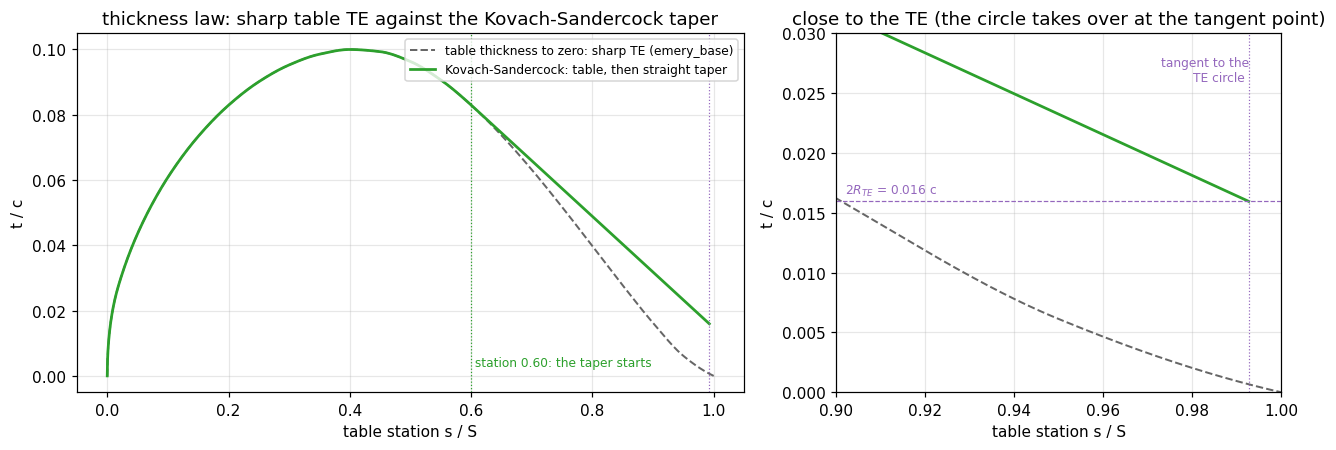

In [6]:
t_nominal = geo.TABLE_T_MAX * geo.thickness_scale(spec.t_max_over_c)
kovach_half, x_tangent, te_centre = geo._kovach_closure(spec.cl0, t_nominal, "pchip_sqrt")   # module internal: the Kovach thickness law
station_tangent = float(geo.camberline_station(x_tangent, spec.cl0))
R_te = geo.KOVACH_TE_RADIUS
S = geo.camberline_length(spec.cl0)
h_start = float(kovach_half(np.array([geo.KOVACH_START_STATION]))[0])
h_end = float(kovach_half(np.array([station_tangent]))[0])
taper_angle = np.degrees(np.arctan((h_start - h_end) / ((station_tangent - geo.KOVACH_START_STATION) * S)))

station = np.linspace(0.0, 1.0, 4001)
t_sharp = geo.naca65_base_thickness(station, spec.t_max_over_c, thickness_reconstruction="pchip_sqrt")
on_taper = station <= station_tangent
t_kovach = 2.0 * kovach_half(station[on_taper])

print(f"TE circle: R_TE = {R_te} c, centre ({te_centre[0]:.5f}, {te_centre[1]:.5f}) on the camberline, through (1, 0)")
print(f"TE thickness: sharp (emery_base) 0;  Kovach-Sandercock 2 R_TE = {2 * R_te:.3f} c")
print(f"taper: from station {geo.KOVACH_START_STATION} (t/c = {2 * h_start:.5f}) to the tangent point at station "
      f"{station_tangent:.4f} (t/c = {2 * h_end:.5f}); half angle {taper_angle:.2f} deg along the straightened camberline")

fig, (ax, zoom) = plt.subplots(1, 2, figsize=(12, 4.2), width_ratios=(3, 2))
for a in (ax, zoom):
    a.plot(station, t_sharp, "--", color="0.4", lw=1.3, label="table thickness to zero: sharp TE (emery_base)")
    a.plot(station[on_taper], t_kovach, color="tab:green", lw=1.8, label="Kovach-Sandercock: table, then straight taper")
    a.axvline(geo.KOVACH_START_STATION, color="tab:green", lw=0.8, ls=":")
    a.axvline(station_tangent, color="tab:purple", lw=0.8, ls=":")
    a.set_xlabel("table station s / S"); a.set_ylabel("t / c")
ax.text(geo.KOVACH_START_STATION, 0.003, " station 0.60: the taper starts", color="tab:green", fontsize=8)
ax.set_title("thickness law: sharp table TE against the Kovach-Sandercock taper")
ax.legend(loc="upper right", fontsize=8)
zoom.set_xlim(0.9, 1.0); zoom.set_ylim(0.0, 0.03)
zoom.axhline(2 * R_te, color="tab:purple", lw=0.8, ls="--")
zoom.text(0.902, 2 * R_te + 0.0006, "$2R_{TE}$ = 0.016 c", color="tab:purple", fontsize=8)
zoom.text(station_tangent, 0.026, "tangent to the\nTE circle ", color="tab:purple", fontsize=8, ha="right")
zoom.set_title("close to the TE (the circle takes over at the tangent point)")
fig.tight_layout()
plt.show()

sharp TE (emery_base): wedge angle between the two closing segments 4.839 deg, thickness 0 at (1, 0)


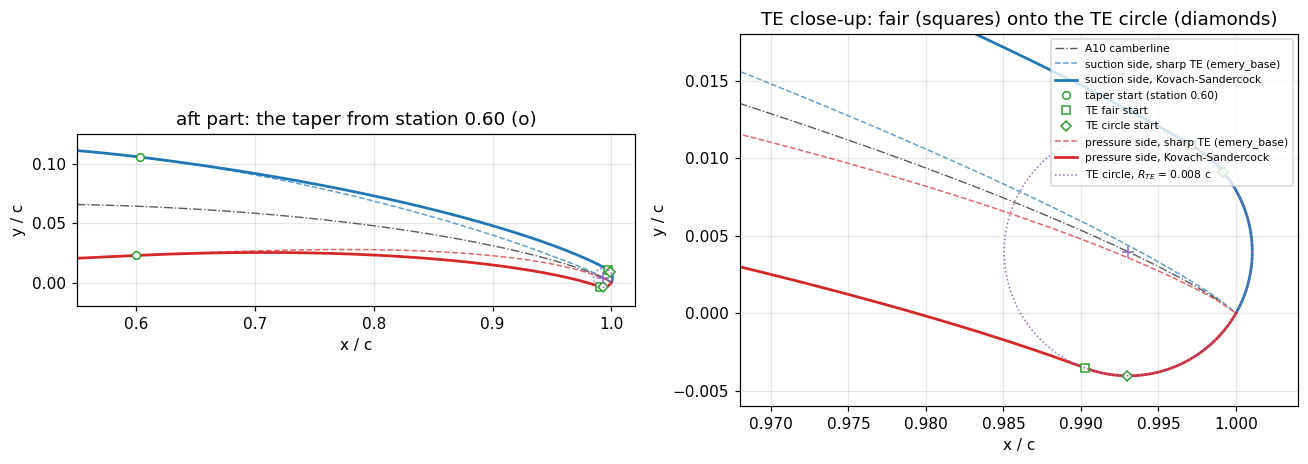

In [7]:
references = {variant: geo.naca65_reference_surfaces(spec.cl0, spec.t_max_over_c, profile_variant=variant, thickness_reconstruction="pchip_sqrt")
              for variant in geo.PROFILE_VARIANTS}


def surface_points(reference, n=6001):
    return reference.sample(max(41, n // len(reference.pieces))).points


def junction_point(reference, label):
    junction = next(j for j in reference.junctions if j.label.startswith(label))
    return reference.sample_piece(junction.index + 1, reference.piece_bounds[junction.index + 1]).points[0]


kovach, sharp = references["kovach_sandercock"], references["emery_base"]
tangents = [ref.sample_piece(len(ref.pieces) - 1, ref.piece_bounds[-1]).tangent[-1] for ref in sharp]
wedge = np.degrees(np.arccos(np.clip(tangents[0] @ tangents[1], -1.0, 1.0)))
print(f"sharp TE (emery_base): wedge angle between the two closing segments {wedge:.3f} deg, thickness 0 at (1, 0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
circle = te_centre + R_te * np.column_stack((np.cos(np.linspace(0, 2 * np.pi, 361)), np.sin(np.linspace(0, 2 * np.pi, 361))))
for ax, (x0, x1, y0, y1) in zip(axes, ((0.55, 1.02, -0.02, 0.125), (0.968, 1.004, -0.006, 0.018))):
    ax.plot(*X_c.T, "-.", color="0.35", lw=0.9, label="A10 camberline")
    for k, (name, color) in enumerate((("suction", "tab:blue"), ("pressure", "tab:red"))):
        ax.plot(*surface_points(sharp[k]).T, "--", color=color, lw=1.0, alpha=0.7,
                label=f"{name} side, sharp TE (emery_base)")
        ax.plot(*surface_points(kovach[k]).T, color=color, lw=1.8, label=f"{name} side, Kovach-Sandercock")
        for label, marker, text in (("Kovach start", "o", "taper start (station 0.60)"),
                                    ("Kovach TE fair start", "s", "TE fair start"),
                                    ("Kovach TE circle start", "D", "TE circle start")):
            point = junction_point(kovach[k], label)
            ax.plot(*point, marker, ms=5, mfc="white", color="tab:green", label=text if k == 0 else None)
    ax.plot(*circle.T, ":", color="tab:purple", lw=1.0, label="TE circle, $R_{TE}$ = 0.008 c")
    ax.plot(*te_centre, "+", color="tab:purple", ms=8)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x / c"); ax.set_ylabel("y / c")
axes[0].set_title("aft part: the taper from station 0.60 (o)")
axes[1].set_title("TE close-up: fair (squares) onto the TE circle (diamonds)")
axes[1].legend(loc="upper right", fontsize=7)
fig.tight_layout()
plt.show()

## 7. Legacy LE construction

Ahead of station 0.005 the surfaces $\mathbf X_c \pm (t/2)\,\mathbf n$ are not used. The nose is still open there (section 5), and the mean line turns several degrees in that stretch. The legacy construction, the C1 baseline, closes the nose in two pieces on each side:

1. **LE circle.** Its radius is $R_{LE} = 0.00687\,(t_{max}/0.10)^2\,c$. It is centred on the mean-line tangent at $x/c = 0.005$, the nose axis, and passes through the LE point $(0, 0)$, where the surfaces are tangent to it.
2. **LE fair.** On each side, a quintic in polar form $r(\theta)$ about the circle centre runs from the circle to the surface at station 0.005. It matches the circle to second order at one end. At the other it matches the surface radius, slope and curvature, estimated by a cubic fit of six probe points. It leaves the circle at the smallest angle $\geq 20°$ that minimizes the peak $|\kappa|$ of the fair.

**The problem: the legacy pressure-side LE fair contains an artificial S-bend.** On cambered blades the PS curvature changes sign twice inside the fair, so the surface tangent turns back. For the 65-(12A10)10 it turns back by 4.3° over $m/c \approx$ 0.0069–0.0085 at 33° stagger; at $c_{l0}$ = 1.6 the turn-back is 8.1°, and thin blades are worse, with a "chin". This is not NACA data but an artefact of the construction.

The cause sits in the fair's end data, not in its quintic shape. A fair with no inflection needs the chord between its ends to lie between its two end tangents, turned the same way as the curvature. At station 0.005 the PS surface tangent already points back across the chord from the circle end. So no smooth, inflection-free curve can join those two ends, not even the fairest $G^2$ quintic Hermite. The cell below measures that, and the robust C2 LE removes it in a later section.

SS: circle kept to  20.0 deg;  end data of the fair: circle tangent -> chord +18.12 deg, chord -> station-0.005 tangent +18.36 deg (convex join possible)
    no curvature reversal in the fair
PS: circle kept to  47.5 deg;  end data of the fair: circle tangent -> chord +4.96 deg, chord -> station-0.005 tangent -1.26 deg (no convex join: forced S-bend)
    S-bend: the tangent turns back 4.32 deg over x/c 0.0057-0.0075, curvature down to -63.9 /c (circle 145.6 /c)


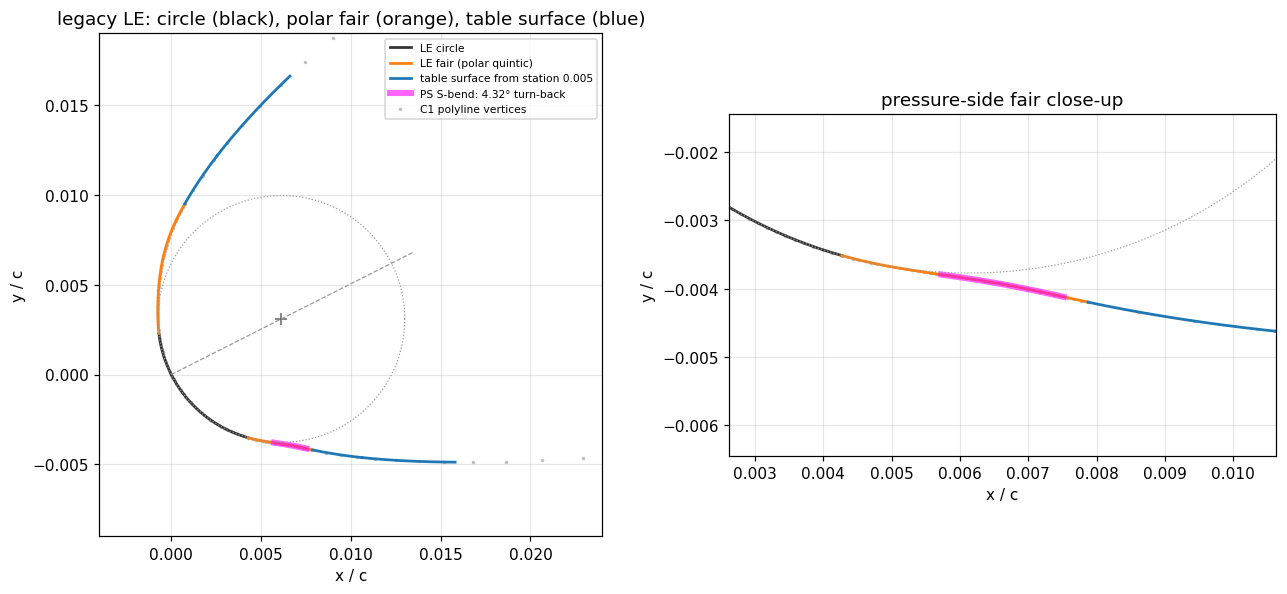

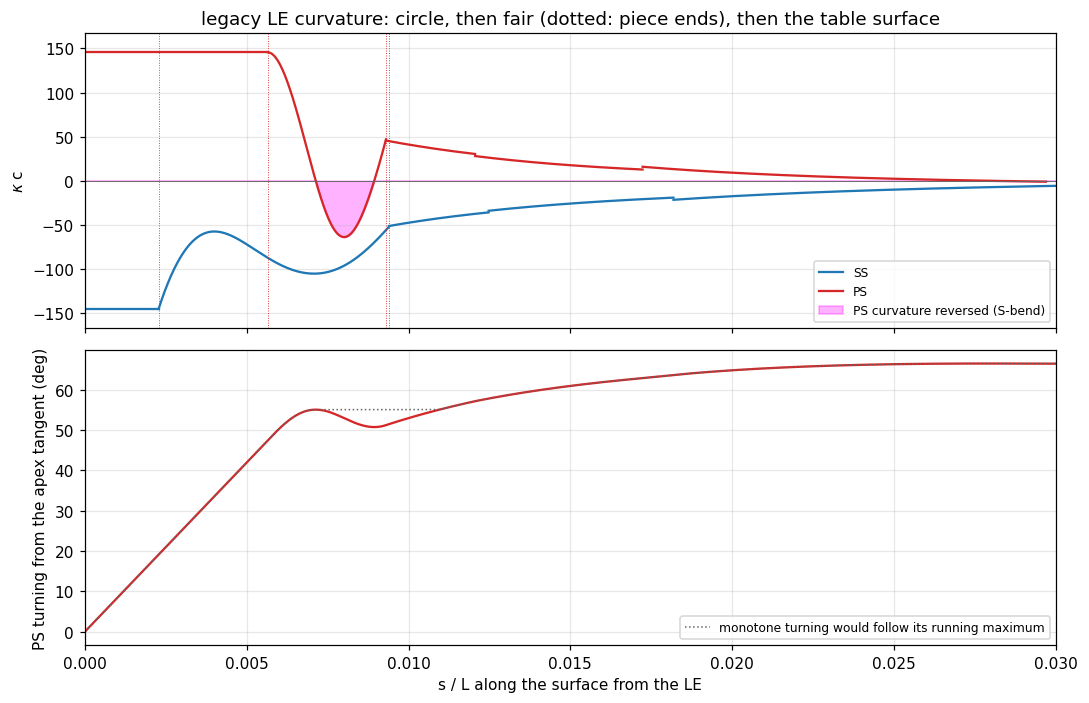

In [8]:
suction_ref, pressure_ref = geo.naca65_reference_surfaces(spec.cl0, spec.t_max_over_c, profile_variant=spec.profile_variant, thickness_reconstruction="pchip_sqrt")
profile = geo.naca65_profile(spec.cl0, spec.t_max_over_c, meanline_type=spec.meanline_type,
                             profile_variant=spec.profile_variant, n_camber_stations=spec.n_camber_stations, thickness_reconstruction="pchip_sqrt")
le_centre, le_radius = profile.leading_edge_center, profile.leading_edge_radius


def piece(reference, index, n=1201):
    return reference.sample_piece(index, np.linspace(*reference.piece_bounds[index], n))


def turn(a, b):                                      # signed angle from a to b, deg
    return np.degrees(np.arctan2(a[0] * b[1] - a[1] * b[0], a @ b))


def s_bend(reference):
    # the first run of curvature against the apex sense inside the LE fair: (turn-back deg, sample rows)
    fair = piece(reference, 1, 4001)
    sense = np.sign(reference.sample_piece(0, reference.piece_bounds[0]).kappa[0])
    against = sense * fair.kappa < 0.0
    if not against.any():
        return 0.0, fair, np.zeros_like(against)
    i0 = int(np.argmax(against)); i1 = i0 + int(np.argmax(~against[i0:])) - 1
    rows = np.zeros_like(against); rows[i0:i1 + 1] = True
    angle = np.degrees(np.unwrap(np.arctan2(fair.tangent[:, 1], fair.tangent[:, 0])))
    return abs(angle[i1] - angle[i0]), fair, rows


for name, reference in (("SS", suction_ref), ("PS", pressure_ref)):
    sense = np.sign(reference.sample_piece(0, reference.piece_bounds[0]).kappa[0])
    circle_end = reference.piece_bounds[0, 1] / le_radius
    start, end = piece(reference, 0, 3), piece(reference, 2, 3)
    p0, t0, p1, t1 = start.points[-1], start.tangent[-1], end.points[0], end.tangent[0]
    chord = (p1 - p0) / np.hypot(*(p1 - p0))
    a, b = sense * turn(t0, chord), sense * turn(chord, t1)
    back, fair, rows = s_bend(reference)
    print(f"{name}: circle kept to {np.degrees(circle_end):5.1f} deg;  end data of the fair: circle tangent -> chord {a:+.2f} deg, "
          f"chord -> station-0.005 tangent {b:+.2f} deg ({'convex join possible' if a > 0 and b > 0 else 'no convex join: forced S-bend'})")
    if back > 0.0:
        print(f"    S-bend: the tangent turns back {back:.2f} deg over x/c {fair.points[rows, 0].min():.4f}-{fair.points[rows, 0].max():.4f}, "
              f"curvature down to {np.min(sense * fair.kappa):.1f} /c (circle {1 / le_radius:.1f} /c)")
    else:
        print("    no curvature reversal in the fair")

colors = {0: "0.2", 1: "tab:orange", 2: "tab:blue"}
names = {0: "LE circle", 1: "LE fair (polar quintic)", 2: "table surface from station 0.005"}
fig, (ax, close) = plt.subplots(1, 2, figsize=(12, 5.5))
for a in (ax, close):
    for reference in (suction_ref, pressure_ref):
        for k in (0, 1, 2, 3):
            sample = piece(reference, k, 400)
            a.plot(*sample.points.T, color=colors[min(k, 2)], lw=1.8,
                   label=names[min(k, 2)] if (reference is suction_ref and k <= 2) else None)
    back, fair, rows = s_bend(pressure_ref)
    if back > 0.0:
        a.plot(*fair.points[rows].T, color="magenta", lw=4, alpha=0.6, label=f"PS S-bend: {back:.2f}° turn-back")
    a.plot(*profile.pressure_surface.T, ".", ms=2.5, color="0.75", zorder=0, label="C1 polyline vertices")
    a.plot(*profile.suction_surface.T, ".", ms=2.5, color="0.75", zorder=0)
    full = le_centre + le_radius * np.column_stack((np.cos(np.linspace(0, 2 * np.pi, 361)), np.sin(np.linspace(0, 2 * np.pi, 361))))
    a.plot(*full.T, ":", color="0.6", lw=0.8)
    a.plot(*le_centre, "+", color="0.4", ms=8)
    axis = le_centre / np.hypot(*le_centre)
    a.plot([0.0, 2.2 * le_radius * axis[0]], [0.0, 2.2 * le_radius * axis[1]], "--", color="0.6", lw=0.8)
    a.set_aspect("equal", adjustable="box")
    a.set_xlabel("x / c"); a.set_ylabel("y / c")
ax.set_xlim(-0.004, 0.024); ax.set_ylim(-0.009, 0.019)
ax.set_title("legacy LE: circle (black), polar fair (orange), table surface (blue)")
ax.legend(loc="upper right", fontsize=7)
centre = fair.points[rows].mean(axis=0) if back > 0.0 else fair.points[len(fair.points) // 2]
close.set_xlim(centre[0] - 0.004, centre[0] + 0.004); close.set_ylim(centre[1] - 0.0025, centre[1] + 0.0025)
close.set_title("pressure-side fair close-up")
fig.tight_layout()
plt.show()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for reference, color, label in ((suction_ref, "tab:blue", "SS"), (pressure_ref, "tab:red", "PS")):
    for k in (0, 1, 2, 3, 4):
        sample = piece(reference, k, 600)
        top.plot(sample.s / reference.length, sample.kappa, color=color, lw=1.5, label=label if k == 0 else None)
    for bound in reference.piece_bounds[:2, 1]:
        top.axvline(bound / reference.length, color=color, lw=0.6, ls=":")
sense = np.sign(pressure_ref.sample_piece(0, pressure_ref.piece_bounds[0]).kappa[0])
ps = pressure_ref.sample(2001)
zone = ps.s / pressure_ref.length < 0.03
angle = np.degrees(np.unwrap(np.arctan2(ps.tangent[zone, 1], ps.tangent[zone, 0])))
turning = sense * (angle - angle[0])
top.axhline(0.0, color="0.4", lw=0.6)
top.fill_between(ps.s[zone] / pressure_ref.length, 0, np.minimum(ps.kappa[zone], 0), color="magenta", alpha=0.3,
                 label="PS curvature reversed (S-bend)")
top.set_ylabel("$\\kappa$ c"); top.set_ylim(-1.15 / le_radius, 1.15 / le_radius)
top.set_title("legacy LE curvature: circle, then fair (dotted: piece ends), then the table surface")
top.legend(fontsize=8, loc="lower right")
bottom.plot(ps.s[zone] / pressure_ref.length, turning, color="tab:red", lw=1.5)
bottom.plot(ps.s[zone] / pressure_ref.length, np.maximum.accumulate(turning), ":", color="0.4", lw=1.0,
            label="monotone turning would follow its running maximum")
bottom.set_ylabel("PS turning from the apex tangent (deg)")
bottom.set_xlabel("s / L along the surface from the LE")
bottom.legend(fontsize=8, loc="lower right")
top.set_xlim(0.0, 0.03)
fig.tight_layout()
plt.show()

## 8. Why C1 geometry would not be enough?

A C1 surface guarantees continuity of position and tangent, but not of the second derivative.

The legacy NACA 65 surface is C1 by construction, and the curvature jumps wherever two of its pieces meet:

- at every thickness-table station, because PCHIP is only C1 (section 3);
- where the LE fair meets the surface at station 0.005;
- where the Kovach TE fair leaves the taper, by about $1/R_{TE}$.

At the Kovach start, station 0.60, it is not even C1: it is a C0 corner. The `emery_base` closing segment meets the surface at another corner.

**Why the solver cares.** In the transformed blade-to-blade equation (Aungier Eq. 5-21; `metrics.py`, `coefficients.py`) the coefficients are

$$A = \frac{\dot m}{S\,b\,\rho\cos^2\beta}, \qquad B = \frac{\dot m\tan\beta}{b\,\rho}, \qquad C = \frac{\dot m\,S}{b\,\rho}, \qquad D = A_\eta - B_m, \qquad E = C_m - B_\eta$$

so

$$B \propto \tan\beta, \qquad D = A_\eta - B_m .$$

$\tan\beta = dy/dm$ is the wall slope in the cascade frame ($m$ axial, $y$ tangential). $B_m$ therefore needs

$$\frac{d\tan\beta}{dm} = \frac{d^2y}{dm^2} = \frac{\kappa}{\cos^3\beta},$$

a **second derivative of the wall geometry**: the derivative of its angle $\beta$. On a C1 wall it jumps wherever the curvature jumps, by $\Delta\kappa/\cos^3\beta$. At a C0 corner it is a spike: $\beta$ itself jumps. The PDE coefficient $D$ is then discontinuous along the blade, and a solver that differentiates the wall nodes turns each jump into a local disturbance of the flow solution. That is why the solver-ready geometry needs at least C2 walls.

The plots below use the exact one-sided derivatives of the C1 construction, piece by piece, so every jump shows as a jump. Near the nose the wall turns through the axial direction ($\cos\beta \to 0$). There $d^2y/dm^2$ grows without bound because $m$ is used as the independent coordinate. That is a coordinate singularity, not a geometry defect (shaded).

SS: 18 of 27 piece junctions jump in curvature or angle; the largest:
    Kovach TE fair start             s/L = 0.9881:  d(beta) = -0.0000 deg,  d(kappa) =  -118.94 /c,  d(dtan beta/dm) =   -119.38 /c
    table station 0.0125             s/L = 0.0182:  d(beta) = +0.0000 deg,  d(kappa) =    -2.44 /c,  d(dtan beta/dm) =   -194.52 /c
    table station 0.0075             s/L = 0.0125:  d(beta) = -0.0000 deg,  d(kappa) =    +1.83 /c,  d(dtan beta/dm) =  +3464.19 /c
    table station 0.025              s/L = 0.0316:  d(beta) = +0.0000 deg,  d(kappa) =    -1.61 /c,  d(dtan beta/dm) =    -28.74 /c
    table station 0.45               s/L = 0.4540:  d(beta) = -0.0000 deg,  d(kappa) =    -1.09 /c,  d(dtan beta/dm) =     -1.88 /c
    largest tangent break: Kovach start, station 0.6 at s/L = 0.6015, beta jumps -0.0767 deg (C0 there)
PS: 18 of 27 piece junctions jump in curvature or angle; the largest:
    Kovach TE fair start             s/L = 0.9888:  d(beta) = -0.0000 deg,  d(kappa) =  +132.03 

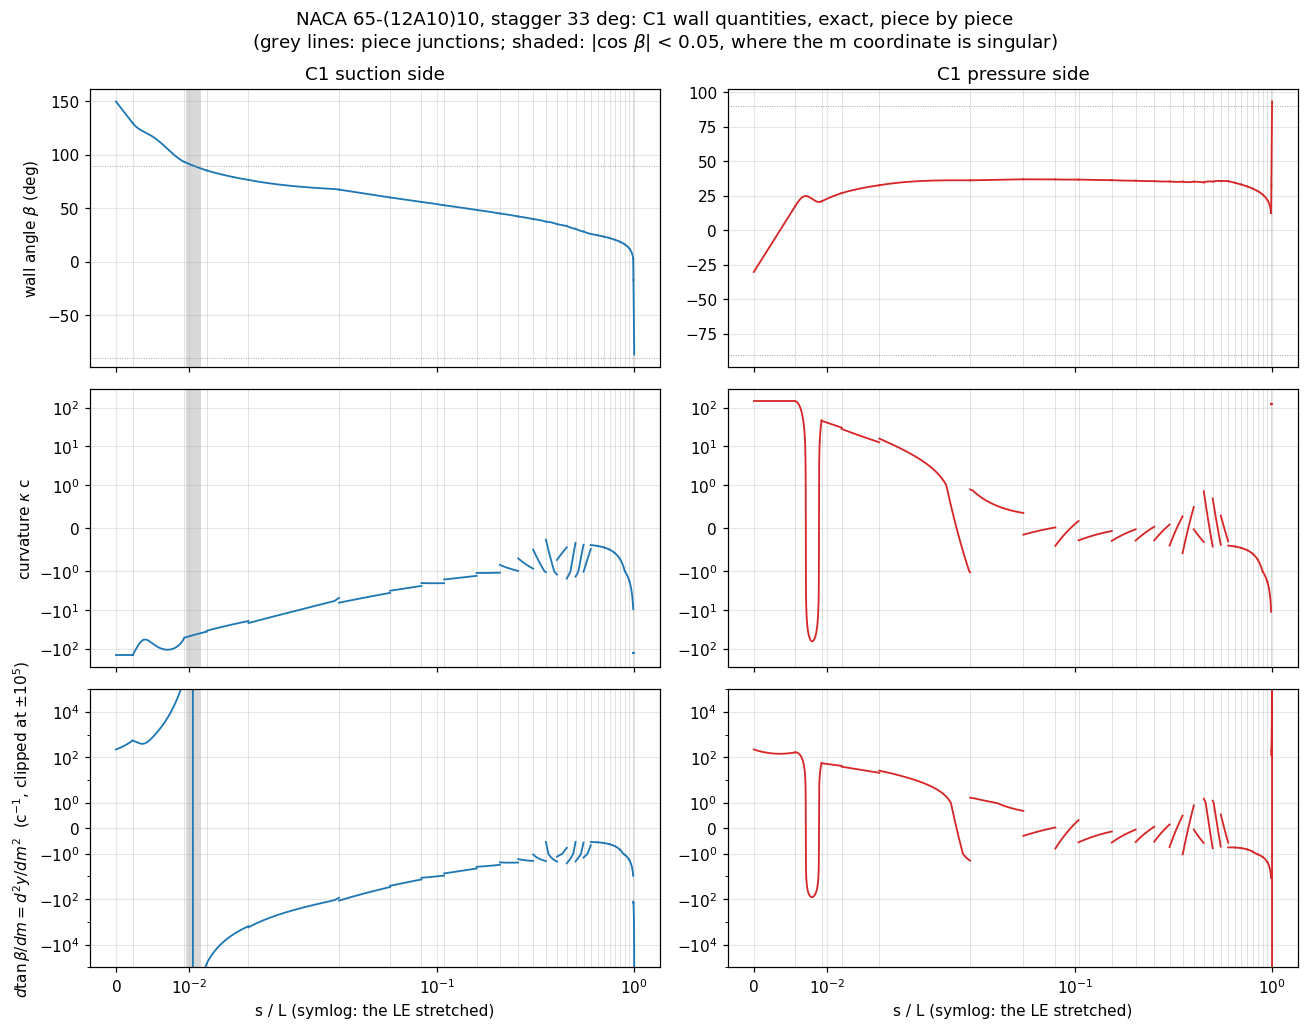

In [9]:
stagger = np.radians(spec.stagger_deg)
rotation = np.array([[np.cos(stagger), -np.sin(stagger)], [np.sin(stagger), np.cos(stagger)]])  # blade -> cascade frame
c1_refs = geo.naca65_reference_surfaces(spec.cl0, spec.t_max_over_c, profile_variant=spec.profile_variant, thickness_reconstruction="pchip_sqrt")


def solver_quantities(sample):
    # wall angle beta (deg, from the axial direction), curvature, d(tan beta)/dm and |cos beta|, cascade frame
    d1, d2 = sample.tangent @ rotation.T, sample.second @ rotation.T
    beta = np.degrees(np.arctan2(d1[:, 1], d1[:, 0]))
    _, dtan_beta_dm = geo.wall_slopes(d1, d2)
    return beta, sample.kappa, dtan_beta_dm, np.abs(d1[:, 0])


def junction_jumps(reference):
    rows = []
    for j in reference.junctions:
        before = reference.sample_piece(j.index, reference.piece_bounds[j.index])
        after = reference.sample_piece(j.index + 1, reference.piece_bounds[j.index + 1])
        b0, k0, d0, _ = (q[-1] for q in solver_quantities(before))
        b1, k1, d1, _ = (q[0] for q in solver_quantities(after))
        rows.append((j.label, j.s / reference.length, b1 - b0, k1 - k0, d1 - d0))
    return rows


for name, reference in zip(("SS", "PS"), c1_refs):
    rows = junction_jumps(reference)
    jumping = [r for r in rows if abs(r[3]) > 1e-6 or abs(r[2]) > 1e-9]
    print(f"{name}: {len(jumping)} of {len(rows)} piece junctions jump in curvature or angle; the largest:")
    for label, u, d_beta, d_kappa, d_dtan in sorted(jumping, key=lambda r: -abs(r[3]))[:5]:
        print(f"    {label:32s} s/L = {u:.4f}:  d(beta) = {d_beta:+.4f} deg,  d(kappa) = {d_kappa:+8.2f} /c,  "
              f"d(dtan beta/dm) = {d_dtan:+9.2f} /c")
    corner = max(rows, key=lambda r: abs(r[2]))
    print(f"    largest tangent break: {corner[0]} at s/L = {corner[1]:.4f}, beta jumps {corner[2]:+.4f} deg (C0 there)")

fig, axes = plt.subplots(3, 2, figsize=(12, 9.5), sharex=True)
for col, (name, reference) in enumerate(zip(("suction side", "pressure side"), c1_refs)):
    for k in range(len(reference.pieces)):
        sample = reference.sample_piece(k, np.linspace(*reference.piece_bounds[k], 300))
        u = sample.s / reference.length
        beta, kappa, dtan_beta, cos_beta = solver_quantities(sample)
        color = "tab:blue" if col == 0 else "tab:red"
        axes[0, col].plot(u, beta, color=color, lw=1.2)
        axes[1, col].plot(u, kappa, color=color, lw=1.2)
        axes[2, col].plot(u, dtan_beta, color=color, lw=1.2)
        near = cos_beta < 0.05
        if near.any():
            for ax in axes[:, col]:
                ax.fill_between(u, 0, 1, where=near, transform=ax.get_xaxis_transform(), color="0.85", lw=0)
    for ax in axes[:, col]:
        for bound in reference.piece_bounds[1:, 0]:
            ax.axvline(bound / reference.length, color="0.85", lw=0.5, zorder=0)
        ax.set_xscale("symlog", linthresh=0.03)
    axes[0, col].set_title(f"C1 {name}")
    axes[0, col].axhline(90.0, color="0.6", lw=0.6, ls=":"); axes[0, col].axhline(-90.0, color="0.6", lw=0.6, ls=":")
    axes[1, col].set_yscale("symlog", linthresh=1.0)
    axes[1, col].set_ylim(-300.0, 300.0)
    axes[1, col].set_yticks([-1e2, -1e1, -1.0, 0.0, 1.0, 1e1, 1e2])
    axes[2, col].set_yscale("symlog", linthresh=1.0)
    axes[2, col].set_ylim(-1e5, 1e5)                      # clipped: it is unbounded where cos(beta) -> 0
    axes[2, col].set_yticks([-1e4, -1e2, -1.0, 0.0, 1.0, 1e2, 1e4])
    axes[2, col].set_xlabel("s / L (symlog: the LE stretched)")
axes[0, 0].set_ylabel("wall angle $\\beta$ (deg)")
axes[1, 0].set_ylabel("curvature $\\kappa$ c")
axes[2, 0].set_ylabel("$d\\tan\\beta/dm = d^2y/dm^2$  (c$^{-1}$, clipped at $\\pm10^5$)")
fig.suptitle(f"{designation}, stagger {spec.stagger_deg:g} deg: C1 wall quantities, exact, piece by piece\n"
             "(grey lines: piece junctions; shaded: |cos $\\beta$| < 0.05, where the m coordinate is singular)")
fig.tight_layout()
plt.show()

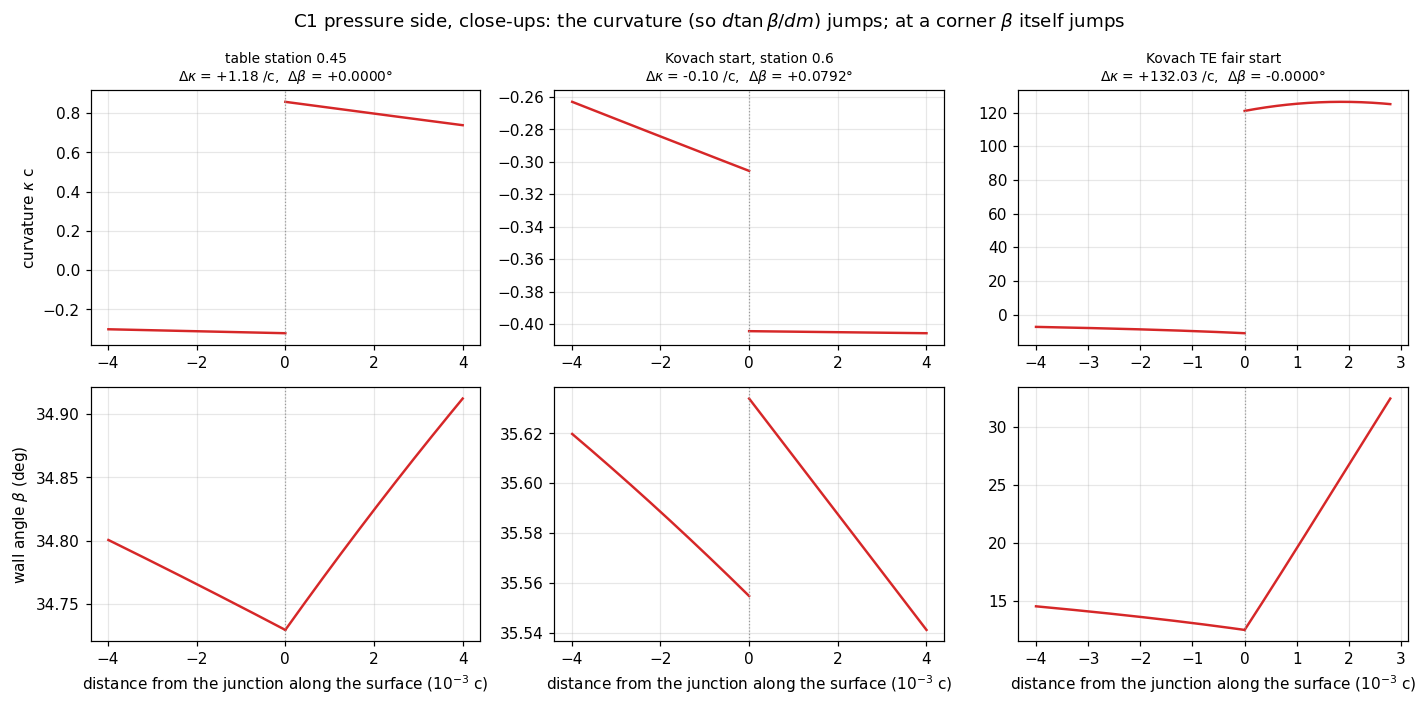

In [10]:
# Close-ups of three kinds of junction on the pressure side: a mid-chord table station (curvature
# jump), the largest tangent break (a C0 corner), and the largest curvature jump.
reference = c1_refs[1]
rows = junction_jumps(reference)
midchord = [r for r in rows if r[0].startswith("table station") and 0.1 < r[1] < 0.55]
picks = [max(midchord, key=lambda r: abs(r[3])), max(rows, key=lambda r: abs(r[2])), max(rows, key=lambda r: abs(r[3]))]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for col, (label, u_junction, d_beta, d_kappa, d_dtan) in enumerate(picks):
    j = next(j for j in reference.junctions if j.label == label)
    half = 0.004
    for k in (j.index, j.index + 1):
        # sample_piece always includes both ends of the piece, so sample it all, dense in the window
        lo, hi = reference.piece_bounds[k]
        window = np.linspace(max(lo, j.s - half), min(hi, j.s + half), 400)
        sample = reference.sample_piece(k, np.unique(np.concatenate((np.linspace(lo, hi, 50), window))))
        keep = np.abs(sample.s - j.s) <= half
        beta, kappa, dtan_beta, _ = (q[keep] for q in solver_quantities(sample))
        x = (sample.s[keep] - j.s) * 1e3
        axes[0, col].plot(x, kappa, color="tab:red", lw=1.6)
        axes[1, col].plot(x, beta, color="tab:red", lw=1.6)
    axes[0, col].set_title(f"{label}\n$\\Delta\\kappa$ = {d_kappa:+.2f} /c,  $\\Delta\\beta$ = {d_beta:+.4f}°", fontsize=9)
    axes[1, col].set_xlabel("distance from the junction along the surface (10$^{-3}$ c)")
    for ax in axes[:, col]:
        ax.axvline(0.0, color="0.6", lw=0.8, ls=":")
axes[0, 0].set_ylabel("curvature $\\kappa$ c")
axes[1, 0].set_ylabel("wall angle $\\beta$ (deg)")
fig.suptitle("C1 pressure side, close-ups: the curvature (so $d\\tan\\beta/dm$) jumps; at a corner $\\beta$ itself jumps")
fig.tight_layout()
plt.show()

## 9. C2 quintic representation

This section changes **only the representation** of the blade. It compares the legacy C1 surface of sections 5–8 with the geometry-preserving quintic C2 representation of the same surface, `geo.fit_quintic_surface`. That is the C2 path that existed before the robust LE, and it is called here directly on the exact C1 reference surfaces. (The `surface_continuity="C2"` switch of `make_cascade` now builds the robust LE of section 10 instead. That is a different change and is kept out of this section on purpose.)

> **The C2 representation in this section is NOT a redesigned blade.** It approximates the validated legacy geometry within the tight representation tolerance ($10^{-6}\,c$) and only removes derivative discontinuities. Therefore geometric defects already present in the legacy surface, such as the pressure-side LE S-bend, are intentionally preserved.

### 9.1 Why C2 was introduced

In the cascade frame ($m$ axial, $y$ tangential) the wall angle and its derivative are

$$\tan\beta = \frac{dy}{dm}, \qquad \frac{d\,[\tan\beta]}{dm} = \frac{d^2y}{dm^2} = \frac{\kappa}{\cos^3\beta} .$$

- **C1 gives continuous position and tangent:** $y$ and $\beta$ are continuous.
- **C1 does not guarantee a continuous second derivative:** $\kappa$ and $d\tan\beta/dm$ may jump.
- **They do jump on the legacy surface** (section 8): at every PCHIP table station, where the LE fair meets the table surface, and where the Kovach TE fair starts. The Kovach start (station 0.60) even has a slope break.
- **These quantities enter the geometry-dependent coefficients** of the stream-function equation (Aungier 2003, Eqs. 5-21 to 5-26). $D = A_\eta - B_m$ contains $B_m$, and with $B \propto \tan\beta$ that is $d\tan\beta/dm$. $E = C_m - B_\eta$ contains the $m$-derivative of the passage width and the slope difference across the passage.

**C2 was introduced for derivative regularity, not to repair the physical LE shape.**

**How `fit_quintic_surface` builds it.** Each surface is one clamped quintic B-spline $\mathbf X(u)$, with $u = s/L$ ($s$ the C1 arc length, $L$ its length). Its interior knots are simple, so it is $C^4$ at every knot. The spline is a least-squares fit to the C1 surface itself, which is changed only at its junctions:

- at a junction where the curvature jumps or the tangent breaks, the kink of the tangent angle is convolved with the kernel $\tfrac{35}{32}(1-x^2)^3$ over a half-width $a$, the widest that moves the surface by at most $10^{-6}\,c$;
- that small shift is taken back over $\pm 6a$ (the compensation zone), so the surface rejoins C1;
- the LE point, tangent and curvature, and the TE point, tangent and (rounded TE) curvature are imposed exactly;
- smooth pieces are not changed: the legacy LE circle and fair, S-bend included, are represented as they are.

### 9.2 C1 vs legacy-derived C2 overlay

NACA 65-(12A10)10: legacy-derived C2 = geo.fit_quintic_surface of the C1 reference surfaces
  SS: 347 control points, 18 of 27 junctions smoothed
      |C2 - C1| max 1.00e-06 c, reached inside the kernel transitions (1.00e-06 c there)
      outside the smoothing zones (|s - s_j| >= 6a, 35 % of the surface): max 2.4e-08 c, the least-squares representation error alone
  PS: 346 control points, 18 of 27 junctions smoothed
      |C2 - C1| max 1.00e-06 c, reached inside the kernel transitions (1.00e-06 c there)
      outside the smoothing zones (|s - s_j| >= 6a, 34 % of the surface): max 6.5e-10 c, the least-squares representation error alone


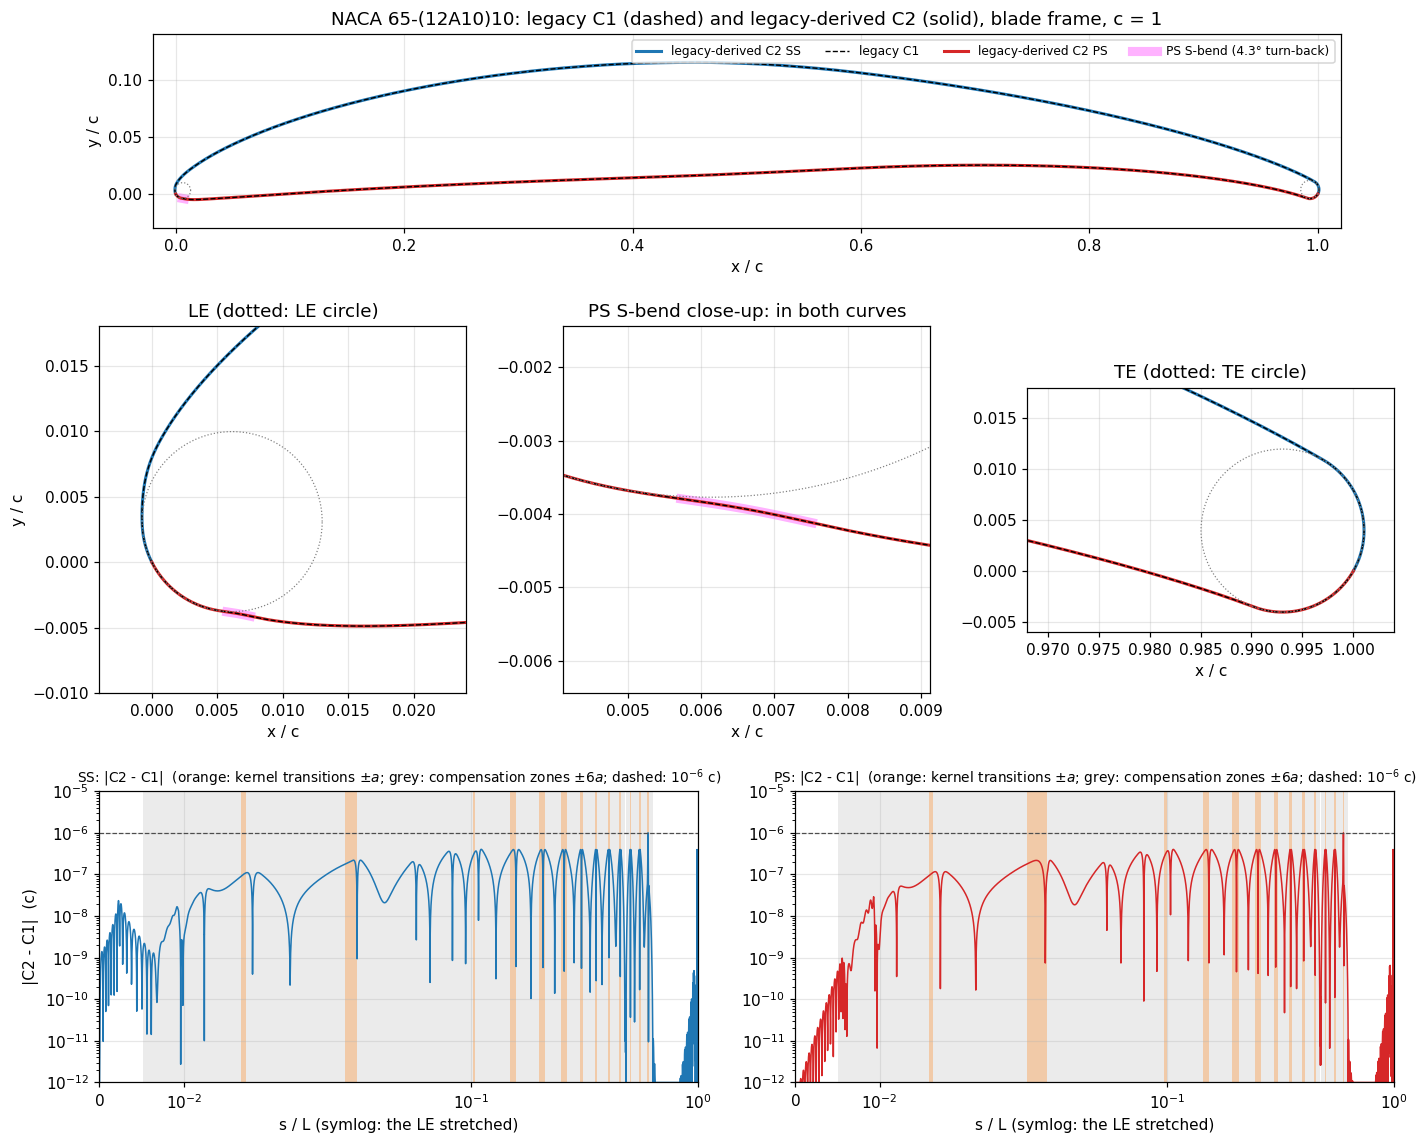

In [11]:
# Legacy-derived C2: fit_quintic_surface on the exact C1 reference surfaces of section 8 (blade frame, c = 1).
legacy_c2 = [geo.fit_quintic_surface(reference) for reference in c1_refs]
legacy_c2_cascade = [fit.curve.rotated(stagger) for fit in legacy_c2]          # the same curves in the cascade frame
compensation = geo.C2_COMPENSATION_RATIO                                        # 6: zone half-width, in units of a


def smoothing_zones(fit, s):
    # rows of s inside a kernel transition (|s - s_j| < a) and inside any compensation zone (|s - s_j| < 6a)
    transition, zone = np.zeros(len(s), bool), np.zeros(len(s), bool)
    for t in fit.transitions:
        if t.half_width > 0.0:
            transition |= np.abs(s - t.junction.s) < t.half_width
            zone |= np.abs(s - t.junction.s) < compensation * t.half_width
    return transition, zone


def distance_from_c1(curve, reference, points_per_piece=401):
    # |C2 - C1|: distance of the C1 surface points from the curve, chords, against the C1 arc length s
    sample = reference.sample(points_per_piece)
    _, distance = curve.project(sample.points, sample.s / reference.length)
    return sample.s, np.abs(distance)


print(f"{designation}: legacy-derived C2 = geo.fit_quintic_surface of the C1 reference surfaces")
legacy_distances = []
for name, fit, reference in zip(("SS", "PS"), legacy_c2, c1_refs):
    s, d = distance_from_c1(fit.curve, reference)
    transition, zone = smoothing_zones(fit, s)
    legacy_distances.append((s / reference.length, d))
    smoothed = sum(t.half_width > 0.0 for t in fit.transitions)
    print(f"  {name}: {len(fit.curve.control_points)} control points, {smoothed} of {len(fit.transitions)} junctions smoothed")
    print(f"      |C2 - C1| max {d.max():.2e} c, reached inside the kernel transitions ({d[transition].max():.2e} c there)")
    print(f"      outside the smoothing zones (|s - s_j| >= 6a, {100 * np.mean(~zone):.0f} % of the surface): "
          f"max {d[~zone].max():.1e} c, the least-squares representation error alone")

sbend_turn, sbend_fair, sbend_rows = s_bend(pressure_ref)          # section 7: the legacy PS S-bend
u_dense = np.unique(np.concatenate((np.linspace(0.0, 1.0, 20001), np.linspace(0.0, 0.04, 8001),
                                    np.linspace(0.96, 1.0, 4001))))
c1_points = [reference.sample(401).points for reference in c1_refs]
legacy_points = [fit.curve.evaluate(u_dense) for fit in legacy_c2]
circle = np.column_stack((np.cos(np.linspace(0, 2 * np.pi, 721)), np.sin(np.linspace(0, 2 * np.pi, 721))))
side_colors = ("tab:blue", "tab:red")

fig = plt.figure(figsize=(13, 10.5))
layout = fig.add_gridspec(3, 6, height_ratios=(0.6, 1.2, 0.9))
ax_blade = fig.add_subplot(layout[0, :])
ax_le, ax_bend, ax_te = (fig.add_subplot(layout[1, 2 * k:2 * k + 2]) for k in range(3))
ax_ss, ax_ps = fig.add_subplot(layout[2, :3]), fig.add_subplot(layout[2, 3:])
for ax in (ax_blade, ax_le, ax_bend, ax_te):
    for name, p1, p2, color in zip(("SS", "PS"), c1_points, legacy_points, side_colors):
        ax.plot(*p2.T, color=color, lw=2.0, label=f"legacy-derived C2 {name}")
        ax.plot(*p1.T, "--", color="k", lw=0.9, label="legacy C1" if name == "SS" else None)
    if sbend_turn > 0.0:
        ax.plot(*sbend_fair.points[sbend_rows].T, color="magenta", lw=6, alpha=0.3, zorder=0,
                label=f"PS S-bend ({sbend_turn:.1f}° turn-back)")
    ax.plot(*(le_centre + le_radius * circle).T, ":", color="0.5", lw=0.8)
    ax.plot(*(te_centre + R_te * circle).T, ":", color="0.5", lw=0.8)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x / c")
ax_blade.set_xlim(-0.02, 1.02); ax_blade.set_ylim(-0.03, 0.14); ax_blade.set_ylabel("y / c")
ax_blade.set_title(f"{designation}: legacy C1 (dashed) and legacy-derived C2 (solid), blade frame, c = 1")
ax_blade.legend(loc="upper right", fontsize=8, ncol=4)
ax_le.set_xlim(-0.004, 0.024); ax_le.set_ylim(-0.010, 0.018); ax_le.set_ylabel("y / c")
ax_le.set_title("LE (dotted: LE circle)")
centre = sbend_fair.points[sbend_rows].mean(axis=0)
ax_bend.set_xlim(centre[0] - 0.0025, centre[0] + 0.0025); ax_bend.set_ylim(centre[1] - 0.0025, centre[1] + 0.0025)
ax_bend.set_title("PS S-bend close-up: in both curves")
ax_te.set_xlim(0.968, 1.004); ax_te.set_ylim(-0.006, 0.018); ax_te.set_title("TE (dotted: TE circle)")
for ax, (u, d), fit, reference, name, color in zip((ax_ss, ax_ps), legacy_distances, legacy_c2, c1_refs, ("SS", "PS"),
                                                   side_colors):
    for t in fit.transitions:
        if t.half_width > 0.0:
            u_j, a = t.junction.s / reference.length, t.half_width / reference.length
            ax.axvspan(u_j - compensation * a, u_j + compensation * a, color="0.92", lw=0)
            ax.axvspan(u_j - a, u_j + a, color="tab:orange", alpha=0.3, lw=0)
    ax.semilogy(u, np.maximum(d, 1e-12), color=color, lw=1.0)
    ax.axhline(geo.C2_DEVIATION_TARGET, color="0.3", lw=0.8, ls="--")
    ax.set_xscale("symlog", linthresh=0.03); ax.set_xlim(0.0, 1.0); ax.set_ylim(1e-12, 1e-5)
    ax.set_title(f"{name}: |C2 - C1|  (orange: kernel transitions $\\pm a$; grey: compensation zones $\\pm 6a$; "
                 "dashed: $10^{-6}$ c)", fontsize=9)
    ax.set_xlabel("s / L (symlog: the LE stretched)")
ax_ss.set_ylabel("|C2 - C1|  (c)")
fig.tight_layout()
plt.show()

**Reading the overlay.** The two surfaces coincide at plotting resolution everywhere: full blade, nose, S-bend and TE. The distance reaches $10^{-6}\,c$ only inside the kernel transitions; that is the deviation each transition is allowed by design. Outside the smoothing zones it is the least-squares representation error alone (printed above), orders of magnitude smaller. The magenta S-bend sits on both curves: the legacy-derived C2 keeps the legacy shape.

### 9.3 Derivative comparison: shape defect vs continuity defect

Two different kinds of defect show in the derivative plots of section 8, and the quintic representation treats them differently:

- **Shape defect:** a property of the curve itself, inside one smooth piece. The PS S-bend is one. The curvature of the legacy fair changes sign twice and the tangent turns back by about 4°. Any faithful representation of the legacy surface must reproduce it.
- **Continuity defect:** a jump of a derivative where two pieces meet. The curvature, and hence $d\tan\beta/dm$, jumps at the PCHIP table stations and at the Kovach TE fair start, and the tangent breaks at the Kovach start. This is a property of how the surface is assembled, and the quintic representation removes it.

The plots repeat the three quantities of section 8 with the legacy-derived C2 drawn over the C1 pieces.

Over the legacy LE closure (circle + fair, apex to station 0.005): the shape defect, in both representations
  SS: reverse turn  C1 0.000 deg, legacy-derived C2 0.000 deg;   curvature sign changes  C1 0, C2 0
  PS: reverse turn  C1 4.315 deg, legacy-derived C2 4.316 deg;   curvature sign changes  C1 2, C2 2


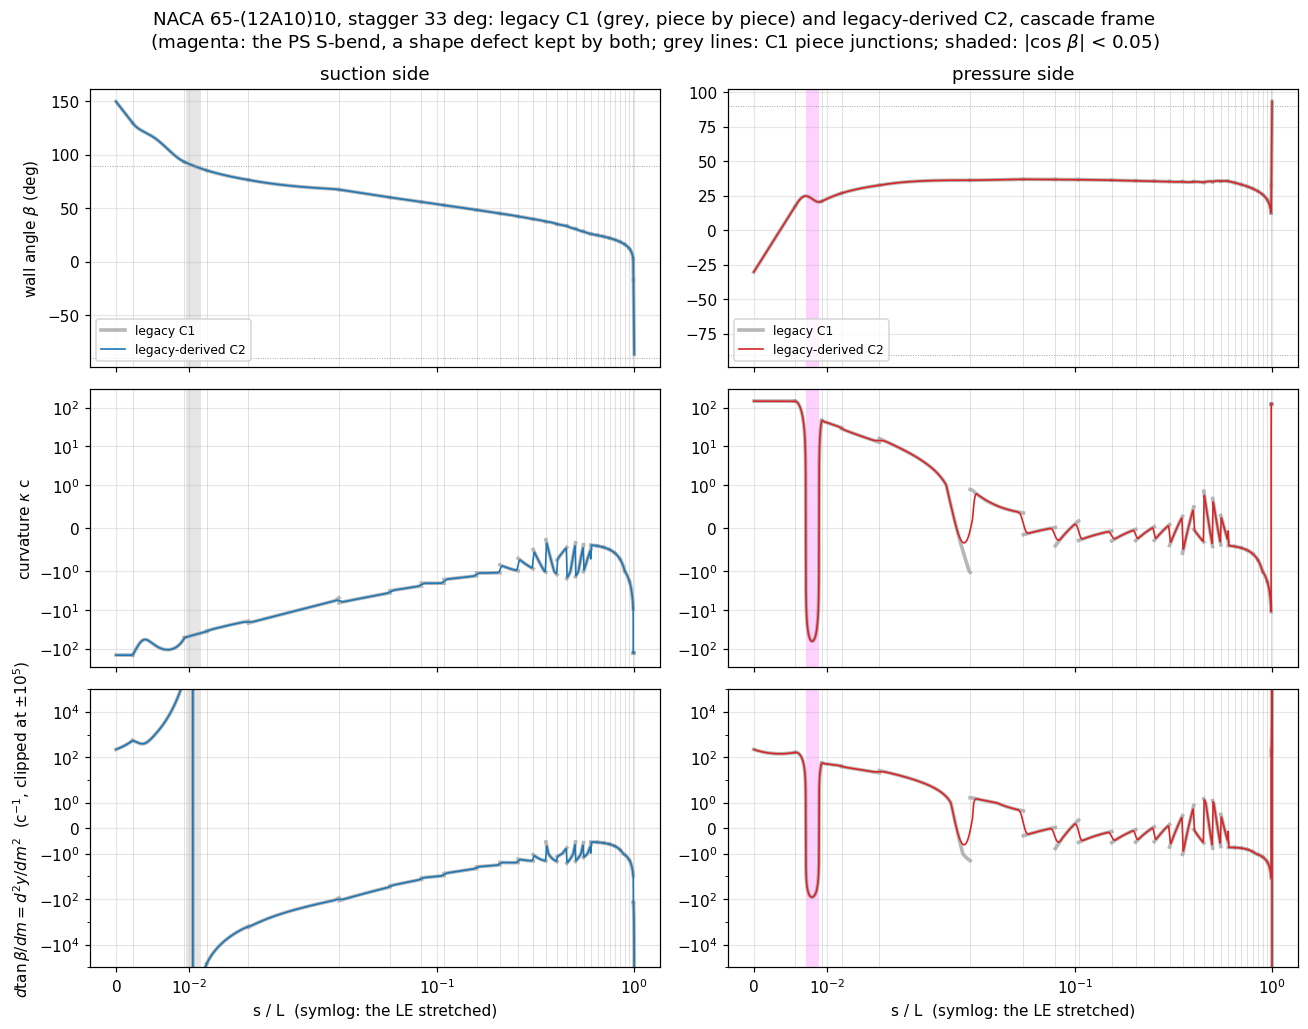

In [12]:
def c1_le_metrics(reference, s_end, n=2001):
    # LE-zone fairness of the exact C1 surface over s <= s_end, piece by piece, measured as
    # geo.leading_edge_fairness measures a curve: (largest reverse turn in deg, curvature sign changes)
    rows = []
    for k, (lo, hi) in enumerate(reference.piece_bounds):
        if lo < s_end:
            sample = reference.sample_piece(k, np.linspace(lo, hi, n))
            rows.append((sample.tangent[sample.s <= s_end], sample.kappa[sample.s <= s_end]))
    tangent, kappa = np.concatenate([r[0] for r in rows]), np.concatenate([r[1] for r in rows])
    angle = np.sign(kappa[0]) * np.unwrap(np.arctan2(tangent[:, 1], tangent[:, 0]))
    signs = np.sign(kappa[kappa != 0.0])
    return float(np.degrees(np.max(np.maximum.accumulate(angle) - angle))), int(np.sum(signs[1:] != signs[:-1]))


print("Over the legacy LE closure (circle + fair, apex to station 0.005): the shape defect, in both representations")
for name, reference, fit in zip(("SS", "PS"), c1_refs, legacy_c2):
    le_end = reference.piece_bounds[geo.NACA65_FIRST_SURFACE_PIECE, 0]
    turn_c1, signs_c1 = c1_le_metrics(reference, le_end)
    c2 = geo.leading_edge_fairness(fit.curve, le_end / reference.length)
    print(f"  {name}: reverse turn  C1 {turn_c1:.3f} deg, legacy-derived C2 {c2['max_reverse_turn_deg']:.3f} deg;   "
          f"curvature sign changes  C1 {signs_c1}, C2 {c2['sign_changes']}")

fig, axes = plt.subplots(3, 2, figsize=(12, 9.5), sharex=True)
for col, (name, reference, curve, color) in enumerate(zip(("suction side", "pressure side"), c1_refs,
                                                          legacy_c2_cascade, side_colors)):
    for k in range(len(reference.pieces)):
        sample = reference.sample_piece(k, np.linspace(*reference.piece_bounds[k], 300))
        beta, kappa, dtan_beta, cos_beta = solver_quantities(sample)
        u = sample.s / reference.length
        for row, value in enumerate((beta, kappa, dtan_beta)):
            axes[row, col].plot(u, value, color="0.6", lw=2.4, alpha=0.7, label="legacy C1" if k == 0 else None)
        near = cos_beta < 0.05
        if near.any():
            for ax in axes[:, col]:
                ax.fill_between(u, 0, 1, where=near, transform=ax.get_xaxis_transform(), color="0.9", lw=0)
    d1, d2 = curve.derivative(u_dense, 1), curve.derivative(u_dense, 2)
    _, dtan_beta_c2 = geo.wall_slopes(d1, d2)
    for row, value in enumerate((np.degrees(np.arctan2(d1[:, 1], d1[:, 0])), geo.signed_curvature(d1, d2), dtan_beta_c2)):
        axes[row, col].plot(u_dense, value, color=color, lw=1.1, label="legacy-derived C2")
    if col == 1 and sbend_turn > 0.0:
        bend = sbend_fair.s[sbend_rows] / reference.length
        for ax in axes[:, col]:
            ax.axvspan(bend.min(), bend.max(), color="magenta", alpha=0.18, lw=0)
    for ax in axes[:, col]:
        for bound in reference.piece_bounds[1:, 0]:
            ax.axvline(bound / reference.length, color="0.85", lw=0.5, zorder=0)
        ax.set_xscale("symlog", linthresh=0.03)
    axes[0, col].set_title(name)
    axes[0, col].axhline(90.0, color="0.6", lw=0.6, ls=":"); axes[0, col].axhline(-90.0, color="0.6", lw=0.6, ls=":")
    axes[0, col].legend(loc="lower left", fontsize=8)
    axes[1, col].set_yscale("symlog", linthresh=1.0)
    axes[1, col].set_ylim(-300.0, 300.0)
    axes[1, col].set_yticks([-1e2, -1e1, -1.0, 0.0, 1.0, 1e1, 1e2])
    axes[2, col].set_yscale("symlog", linthresh=1.0)
    axes[2, col].set_ylim(-1e5, 1e5)
    axes[2, col].set_yticks([-1e4, -1e2, -1.0, 0.0, 1.0, 1e2, 1e4])
    axes[2, col].set_xlabel("s / L  (symlog: the LE stretched)")
axes[0, 0].set_ylabel("wall angle $\\beta$ (deg)")
axes[1, 0].set_ylabel("curvature $\\kappa$ c")
axes[2, 0].set_ylabel("$d\\tan\\beta/dm = d^2y/dm^2$  (c$^{-1}$, clipped at $\\pm10^5$)")
fig.suptitle(f"{designation}, stagger {spec.stagger_deg:g} deg: legacy C1 (grey, piece by piece) and legacy-derived C2, "
             "cascade frame\n"
             "(magenta: the PS S-bend, a shape defect kept by both; grey lines: C1 piece junctions; "
             "shaded: |cos $\\beta$| < 0.05)")
fig.tight_layout()
plt.show()

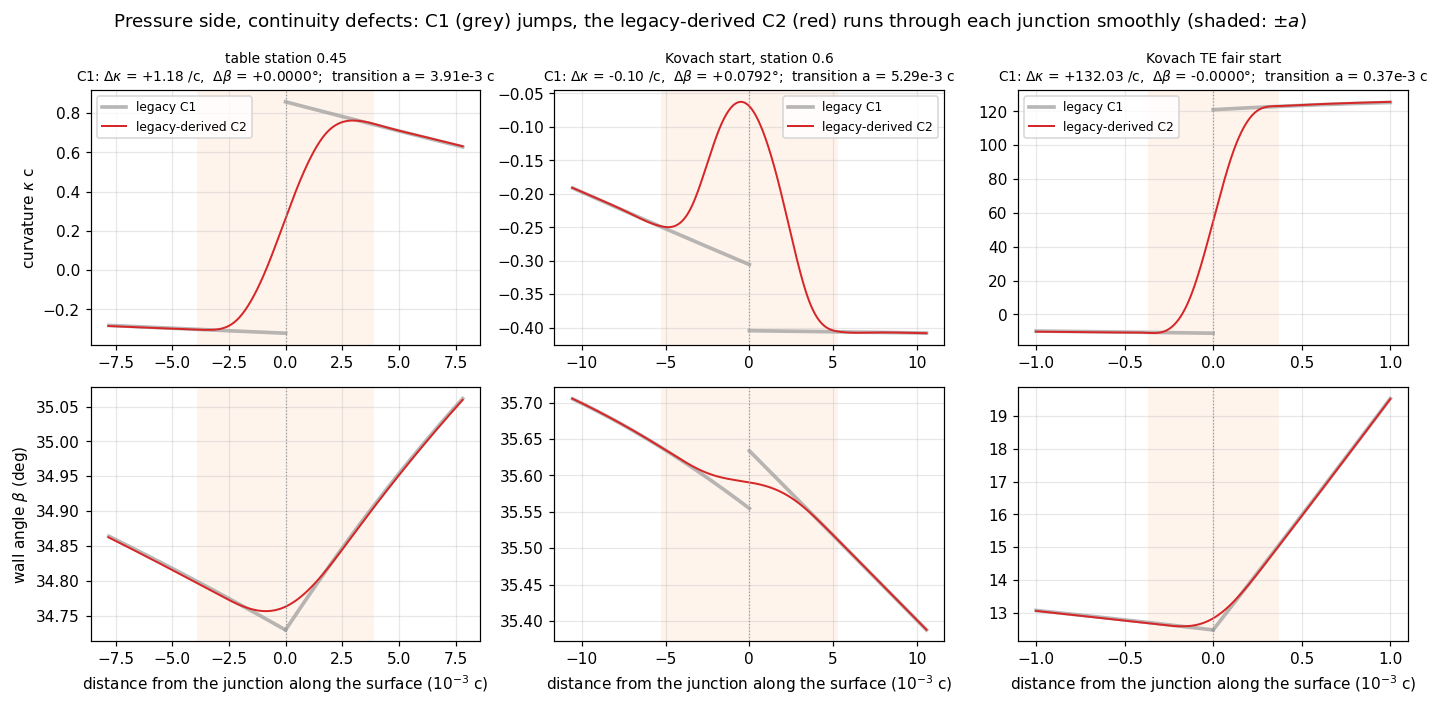

In [13]:
# Close-ups at the three pressure-side junctions of section 8: the continuity defects. At a curvature jump
# the C2 curvature runs monotonically from one side's value to the other's; at the corner (station 0.60)
# the turn is spread into one positive curvature bump of the same area, int kappa ds = delta beta.
reference, fit, curve = c1_refs[1], legacy_c2[1], legacy_c2_cascade[1]
half_widths = {t.junction.label: t.half_width for t in fit.transitions}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for col, (label, u_junction, d_beta, d_kappa, d_dtan) in enumerate(picks):
    j = next(j for j in reference.junctions if j.label == label)
    a = half_widths[label]
    half = max(2.0 * a, 1e-3)                            # window: twice the transition half-width
    for k, (lo, hi) in enumerate(reference.piece_bounds):
        if hi < j.s - half or lo > j.s + half:
            continue
        window = np.linspace(max(lo, j.s - half), min(hi, j.s + half), 400)
        sample = reference.sample_piece(k, np.unique(np.concatenate((np.linspace(lo, hi, 50), window))))
        keep = np.abs(sample.s - j.s) <= half
        beta, kappa, _, _ = (q[keep] for q in solver_quantities(sample))
        x = (sample.s[keep] - j.s) * 1e3
        axes[0, col].plot(x, kappa, color="0.6", lw=2.4, alpha=0.7, label="legacy C1" if k == j.index else None)
        axes[1, col].plot(x, beta, color="0.6", lw=2.4, alpha=0.7)
    u = j.s / reference.length + np.linspace(-half, half, 1601) / curve.reference_length      # u = s / L exactly here
    u = u[(u >= 0.0) & (u <= 1.0)]
    d1, d2 = curve.derivative(u, 1), curve.derivative(u, 2)
    x = (u * curve.reference_length - j.s) * 1e3
    axes[0, col].plot(x, geo.signed_curvature(d1, d2), color="tab:red", lw=1.3, label="legacy-derived C2")
    axes[1, col].plot(x, np.degrees(np.arctan2(d1[:, 1], d1[:, 0])), color="tab:red", lw=1.3)
    for ax in axes[:, col]:
        ax.axvspan(-a * 1e3, a * 1e3, color="tab:orange", alpha=0.08, lw=0)
        ax.axvline(0.0, color="0.6", lw=0.8, ls=":")
    axes[0, col].set_title(f"{label}\nC1: $\\Delta\\kappa$ = {d_kappa:+.2f} /c,  $\\Delta\\beta$ = {d_beta:+.4f}°;  "
                           f"transition a = {a * 1e3:.2f}e-3 c", fontsize=9)
    axes[1, col].set_xlabel("distance from the junction along the surface (10$^{-3}$ c)")
    axes[0, col].legend(fontsize=8)
axes[0, 0].set_ylabel("curvature $\\kappa$ c")
axes[1, 0].set_ylabel("wall angle $\\beta$ (deg)")
fig.suptitle("Pressure side, continuity defects: C1 (grey) jumps, the legacy-derived C2 (red) runs through each "
             "junction smoothly (shaded: $\\pm a$)")
fig.tight_layout()
plt.show()

**Shape defect vs continuity defect.** The pressure-side LE S-bend appears in both curves because it belongs to the underlying legacy geometry. The C2 representation does not remove it: the reverse turn and the curvature sign changes printed above are the same for C1 and the legacy-derived C2. In contrast, the curvature jumps at the PCHIP table, Kovach and fair junctions are regularized by the quintic representation. Each one becomes a smooth transition a few thousandths of a chord wide, and at the Kovach corner the slope break becomes a smooth turn.

So section 9 solves the **continuity** problem only. The shape problem at the LE needs a change of the geometry itself: section 10.

## 10. Robust adaptive leading-edge construction

Section 9 changed the representation and kept the shape. This section changes the **shape of the nose**: a redesign of the LE closure, a separate engineering change. It is what `make_cascade` builds for `surface_continuity="C2"`. *Status: implemented and under validation, not frozen.* Downstream of the LE zone the robust C2 represents the C1 surface exactly as section 9 does: the same junction smoothing, within $10^{-6}\,c$ of C1.

### 10.1 The problem

The NACA 65 source data do not determine the nose uniquely. Table 4-1 gives the thickness from station 0.005 on and an LE radius, and nothing in between: any closure between the LE circle and the first table station is a construction choice, not data. The legacy closure (section 7) is

$$\text{LE nose circle} \;\rightarrow\; \text{local polar fair} \;\rightarrow\; \text{raw NACA surface at station 0.005},$$

with fixed connection logic. The fair leaves the circle at the smallest angle $\geq 20°$ that minimizes its peak curvature, and lands on station 0.005 with that point's slope and curvature. It works for many blades, but it produces

- a **PS S-bend** in the default 65-(12A10)10 case;
- **reverse turning** that grows on thinner and more cambered blades;
- a **chin-like** nose in extreme thin sections (10.7).

**Why a better spline cannot fix it.** A convex arc (curvature of one sign, no inflection) from $P_0$ with tangent $\mathbf t_0$ to $P_1$ with tangent $\mathbf t_1$ exists only if the chord $P_1 - P_0$ lies between the two tangents. Both turns, $\mathbf t_0 \to$ chord and chord $\to \mathbf t_1$, must then have the sign of the curvature. That is a condition on the end data alone:

> The legacy LE-circle endpoint tangent and the early raw-surface tangent can be incompatible with a monotone-convex fair.

When they are, every curve with those end conditions has an inflection, whatever its degree. Raising the spline degree changes the curve between the ends, not the end data. The plot shows the end data of the default blade.

suction side: circle tangent -> chord +18.12 deg, chord -> station-0.005 tangent +18.36 deg: convex join possible
pressure side: circle tangent -> chord +4.96 deg, chord -> station-0.005 tangent -1.26 deg: no convex join: an inflection is forced


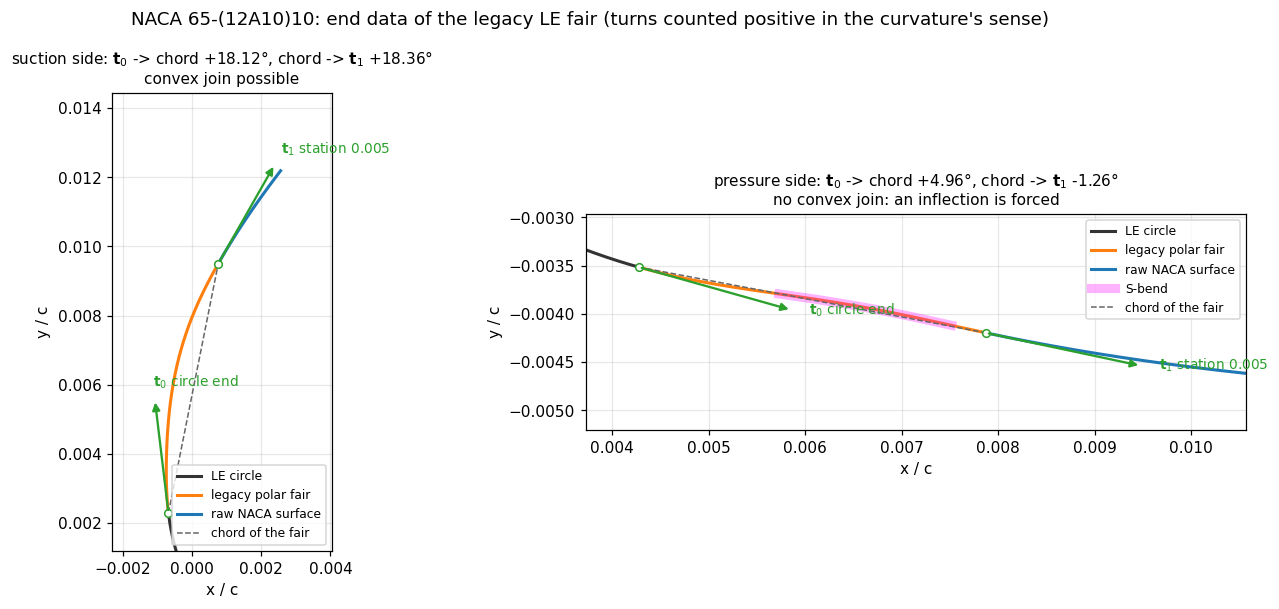

In [14]:
def fair_end_data(reference):
    # end data of the legacy fair: circle end (p0, t0), station 0.005 (p1, t1), and the two turns a convex
    # join needs to have the sign of the curvature: t0 -> chord and chord -> t1 (deg)
    sense = np.sign(reference.sample_piece(0, reference.piece_bounds[0]).kappa[0])
    start, end = piece(reference, 0, 3), piece(reference, 2, 3)
    p0, t0, p1, t1 = start.points[-1], start.tangent[-1], end.points[0], end.tangent[0]
    chord = (p1 - p0) / np.hypot(*(p1 - p0))
    return p0, t0, p1, t1, sense * turn(t0, chord), sense * turn(chord, t1)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, name, reference in zip(axes, ("suction side", "pressure side"), (suction_ref, pressure_ref)):
    p0, t0, p1, t1, first, second = fair_end_data(reference)
    verdict = "convex join possible" if first > 0 and second > 0 else "no convex join: an inflection is forced"
    print(f"{name}: circle tangent -> chord {first:+.2f} deg, chord -> station-0.005 tangent {second:+.2f} deg: {verdict}")
    for k, color, label in ((0, "0.2", "LE circle"), (1, "tab:orange", "legacy polar fair"), (2, "tab:blue", "raw NACA surface")):
        ax.plot(*piece(reference, k, 400).points.T, color=color, lw=2.0, label=label)
    if reference is pressure_ref and sbend_turn > 0.0:
        ax.plot(*sbend_fair.points[sbend_rows].T, color="magenta", lw=6, alpha=0.3, label="S-bend")
    span = np.hypot(*(p1 - p0))
    ax.plot(*np.array([p0, p1]).T, "--", color="0.4", lw=1.0, label="chord of the fair")
    for p, t, label in ((p0, t0, "$\\mathbf{t}_0$ circle end"), (p1, t1, "$\\mathbf{t}_1$ station 0.005")):
        ax.annotate("", xy=p + 0.45 * span * t, xytext=p, arrowprops=dict(arrowstyle="-|>", color="tab:green", lw=1.5))
        ax.annotate(label, p + 0.5 * span * t, color="tab:green", fontsize=9)
        ax.plot(*p, "o", ms=5, mfc="white", color="tab:green")
    view = np.array([p0, p1, p0 + 0.6 * span * t0, p1 + 0.6 * span * t1])        # both ends and both arrows
    lo, hi = view.min(axis=0) - 0.15 * span, view.max(axis=0) + 0.15 * span
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x / c"); ax.set_ylabel("y / c")
    ax.set_title(f"{name}: $\\mathbf{{t}}_0$ -> chord {first:+.2f}°, chord -> $\\mathbf{{t}}_1$ {second:+.2f}°\n{verdict}",
                 fontsize=10)
    ax.legend(loc="lower right" if reference is suction_ref else "upper right", fontsize=8)
fig.suptitle(f"{designation}: end data of the legacy LE fair (turns counted positive in the curvature's sense)")
fig.tight_layout()
plt.show()

On the suction side both turns have the curvature's sign and the legacy fair is clean. On the pressure side the station-0.005 tangent already points back across the chord, so the second turn has the wrong sign. The S-bend is then forced by the end data, not by the quintic shape of the fair.

### 10.2 The new three-part LE

The robust LE keeps the nose circle and the raw NACA surface, and replaces the fixed fair by a curvature-controlled one with a free hand-back point:

$$\text{LE circle} \;\rightarrow\; \text{adaptive curvature fair} \;\rightarrow\; \text{raw / source NACA surface}$$

- **LE apex:** the LE point; both surfaces leave it tangent to the circle with curvature $\mp 1/R_{LE}$, so the two surfaces join $G^2$ there.
- **LE circle:** kept exactly for 20° of turning on either side of the apex (the legacy minimum arc), with the same $R_{LE}$.
- **Departure point:** where the fair has left the circle, reported as the first point where the curvature is 0.1 % below $1/R_{LE}$. The fair leaves the circle with $dr/d\varphi = d^2r/d\varphi^2 = 0$, so it peels off just after 20°.
- **Curvature-controlled fair:** from the circle to the anchor; its curvature magnitude falls monotonically (10.3).
- **Anchor point:** where the special LE construction hands the surface back to the source geometry (10.4).
- **Raw NACA surface:** from the anchor on, the table surface (with the section 9 junction smoothing).

SS and PS use the **same algorithm**, but they generally obtain **different anchor locations** because their source geometry differs.

NACA 65-(12A10)10: robust C2, R_LE / c = 0.00687, LE circle kept 20 deg either side of the apex
  SS: departure at 20.78 deg of turning (s = 0.36 R_LE); anchor at 66.35 deg, 0.00426 c = 0.62 R_LE past station 0.005
  PS: departure at 20.97 deg of turning (s = 0.37 R_LE); anchor at 62.69 deg, 0.00775 c = 1.13 R_LE past station 0.005


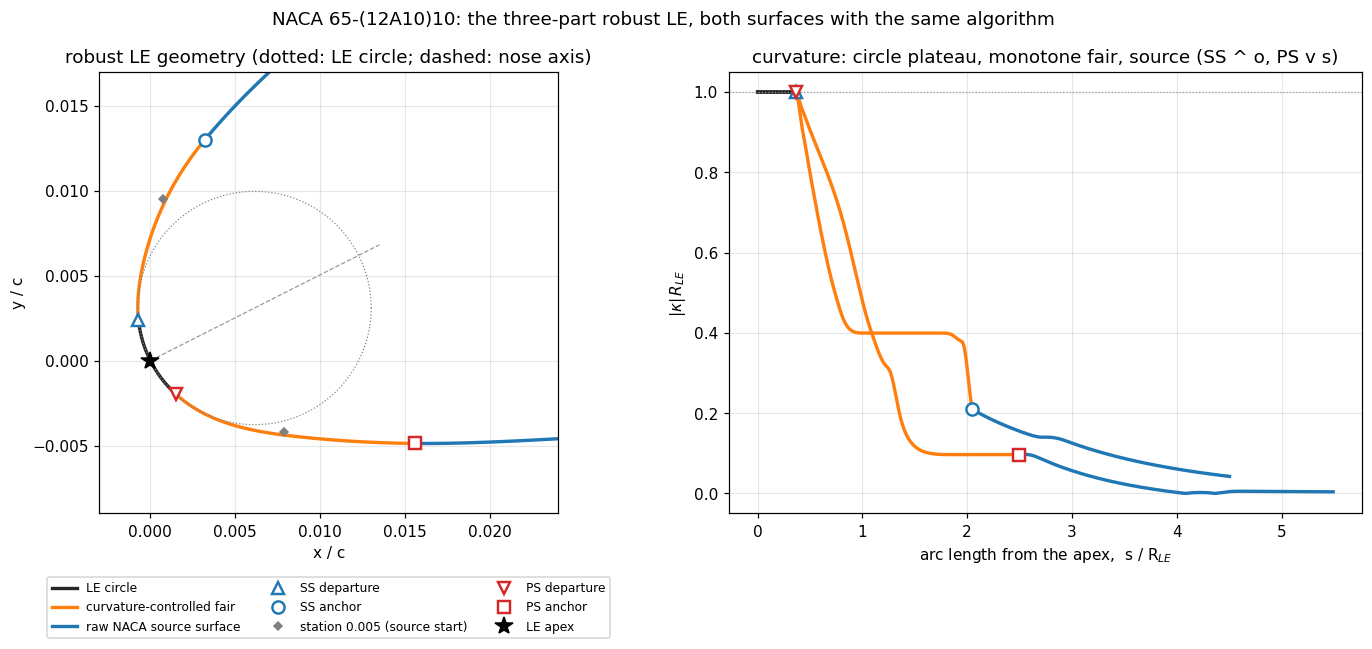

In [15]:
import math
from dataclasses import replace

from scipy.integrate import cumulative_trapezoid

robust = geo.make_cascade(replace(spec, surface_continuity="C2"))       # the robust C2 blade
robust_meta = robust.metadata
robust_blade = (robust.normalized_curves.suction_unstaggered, robust.normalized_curves.pressure_unstaggered)
robust_cascade_curves = (robust.normalized_curves.suction, robust.normalized_curves.pressure)
# module internal: the two C2SurfaceFit objects make_cascade used (cached), to reach the LE fair itself
robust_fits = geo._naca65_quintic_fits(spec.cl0, spec.t_max_over_c, spec.profile_variant, geo.DEFAULT_THICKNESS_RECONSTRUCTION["C2"])
R_LE = robust_meta["le_radius_over_c"]

print(f"{designation}: robust C2, R_LE / c = {R_LE:.5f}, LE circle kept {robust_meta['le_min_arc_deg']:g} deg either side of the apex")
for name, key, fit in zip(("SS", "PS"), ("ss", "ps"), robust_fits):
    past = robust_meta[f"{key}_le_anchor_past_source_start_over_c"]
    print(f"  {name}: departure at {robust_meta[f'{key}_le_departure_deg']:.2f} deg of turning (s = {fit.departure_u * fit.length / R_LE:.2f} R_LE); "
          f"anchor at {robust_meta[f'{key}_le_anchor_deg']:.2f} deg, {past:.5f} c = {past / R_LE:.2f} R_LE past station 0.005")

fig, (ax_g, ax_k) = plt.subplots(1, 2, figsize=(13, 5.8), width_ratios=(1.0, 1.15))
parts = (("0.15", "LE circle"), ("tab:orange", "curvature-controlled fair"), ("tab:blue", "raw NACA source surface"))
for name, key, curve, fit, color, marks in zip(("SS", "PS"), ("ss", "ps"), robust_blade, robust_fits, side_colors,
                                              (("^", "o"), ("v", "s"))):
    u_dep, u_anc = robust_meta[f"{key}_le_departure_u"], robust_meta[f"{key}_le_anchor_u"]
    bounds = ((0.0, u_dep), (u_dep, u_anc), (u_anc, 2.2 * u_anc))
    for (lo, hi), (part_color, part_label) in zip(bounds, parts):
        u = np.linspace(lo, hi, 600)
        ax_g.plot(*curve.evaluate(u).T, color=part_color, lw=2.2, label=part_label if name == "SS" else None)
        ax_k.plot(u * curve.reference_length / R_LE, np.abs(curve.curvature(u)) * R_LE, color=part_color, lw=2.2)
    for u_mark, marker, what in ((u_dep, marks[0], "departure"), (u_anc, marks[1], "anchor")):
        ax_g.plot(*curve.evaluate(u_mark), marker, ms=8, mfc="white", mew=1.6, color=color, label=f"{name} {what}", zorder=5)
        ax_k.plot(u_mark * curve.reference_length / R_LE, abs(float(curve.curvature(u_mark))) * R_LE, marker, ms=8,
                  mfc="white", mew=1.6, color=color, zorder=5)
    start = fit.source.evaluate(np.array([fit.source.start]))[0][0]
    ax_g.plot(*start, "D", ms=4, color="0.5", label="station 0.005 (source start)" if name == "SS" else None)
nose = robust_fits[0].leading_edge.nose
ax_g.plot(*(nose.center + nose.radius * circle).T, ":", color="0.5", lw=0.8)
ax_g.plot(*np.array([nose.apex, nose.apex + 2.2 * nose.radius * nose.axis]).T, "--", color="0.6", lw=0.8)
ax_g.plot(*nose.apex, "*", ms=12, color="k", label="LE apex", zorder=6)
ax_g.set_xlim(-0.003, 0.024); ax_g.set_ylim(-0.009, 0.017)
ax_g.set_aspect("equal", adjustable="box")
ax_g.set_xlabel("x / c"); ax_g.set_ylabel("y / c")
ax_g.set_title("robust LE geometry (dotted: LE circle; dashed: nose axis)")
ax_g.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=8, ncol=3)
ax_k.axhline(1.0, color="0.6", lw=0.8, ls=":")
ax_k.set_xlabel("arc length from the apex,  s / R$_{LE}$")
ax_k.set_ylabel("$|\\kappa|\\,R_{LE}$")
ax_k.set_title("curvature: circle plateau, monotone fair, source (SS ^ o, PS v s)")
fig.suptitle(f"{designation}: the three-part robust LE, both surfaces with the same algorithm")
fig.tight_layout()
plt.show()

Both surfaces show the same three parts: the plateau $|\kappa| R_{LE} = 1$ on the circle, a monotone fall through the fair, then the source surface. The PS anchor lies further downstream than the SS anchor (printed above). The algorithm is the same, but on the PS the raw surface near station 0.005 points back across the chord (10.1), so the fair must travel further before a monotone fair can land on it.

On the SS the fair's curvature falls in two steps: a plateau near $|\kappa| R_{LE} \approx 0.4$, then a short steep drop just ahead of the anchor. It is monotone, as required, but steeper than it needs to be. This is an open tuning item of the LE model, which is not frozen yet.

### 10.3 The curvature-based fair

The fair is written in **Whewell form**: the radius of curvature as a function of the turning angle,

$$r = r(\varphi), \qquad \kappa = \frac{1}{r},$$

where $\varphi$ is the accumulated turning angle of the tangent from the LE apex tangent, and $\theta = \theta_{apex} \pm \varphi$ the tangent angle. By the definition of curvature,

$$\frac{d\varphi}{ds} = \kappa = \frac{1}{r} \quad\Longrightarrow\quad ds = r(\varphi)\,d\varphi ,$$

so

$$dx = r(\varphi)\cos\theta\,d\varphi, \qquad dy = r(\varphi)\sin\theta\,d\varphi .$$

Once $r(\varphi)$ is known, the fair geometry follows by integration. Three properties then hold by construction:

- $r > 0$, so the curvature never changes sign: **no inflection, no S-bend**;
- $\varphi$ grows with $s$, so the tangent never turns back: **no reverse turning**;
- with $dr/d\varphi \geq 0$, $|\kappa| = 1/r$ **never increases** from the circle to the anchor: no curvature overshoot.

$r(\varphi)$ is a cubic B-spline with **non-decreasing control radii**, $R_{LE} = r_0 = r_1 = r_2 \leq r_3 \leq \dots \leq r_N = 1/|\kappa_a|$. A monotone control polygon gives a monotone spline. The first three equal $R_{LE}$ (a smooth departure from the circle); the last is the source radius at the anchor.

Because $\theta(\varphi)$ is fixed once the anchor angle is, the landing position is **linear** in the control radii, and so is the end radius. Among all admissible $r(\varphi)$ the one with the least $\int (d\kappa/ds)^2\,ds = \int r'^2/r^5\,d\varphi$ is taken. That is a bound- and equality-constrained least-squares problem with an exact solution.

SS: r grows from R_LE to 4.77 R_LE over 66.3 deg of turning; min dr/dphi on the fair -2.4e-14 c/rad (>= 0);  trapezoid integral of r(phi) against the module's fair points: 9.0e-09 c
PS: r grows from R_LE to 10.34 R_LE over 62.7 deg of turning; min dr/dphi on the fair -1.0e-13 c/rad (>= 0);  trapezoid integral of r(phi) against the module's fair points: 7.3e-09 c


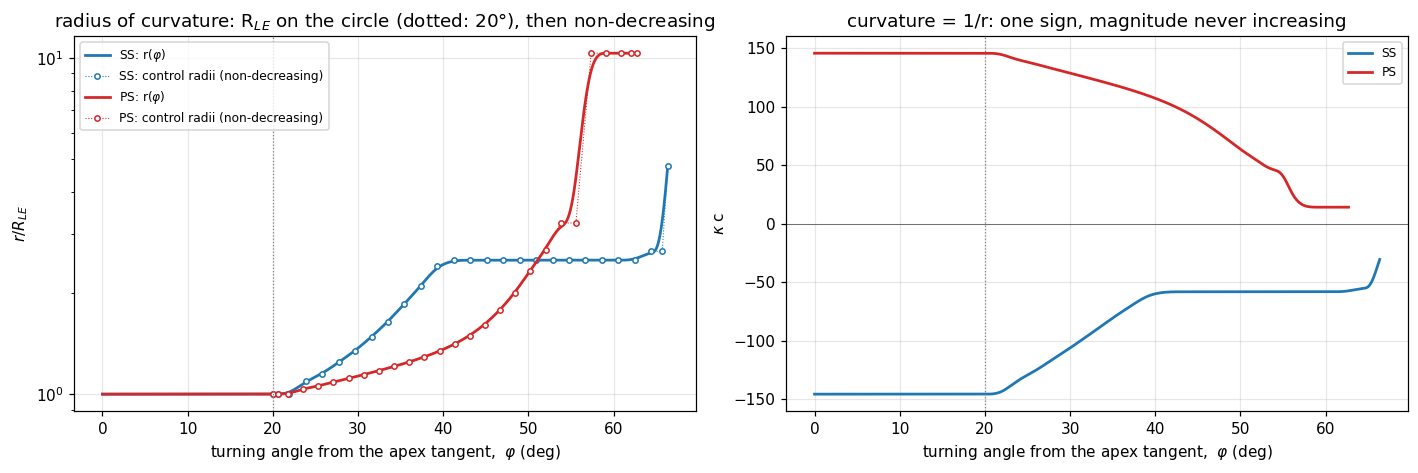

In [16]:
fig, (ax_r, ax_k) = plt.subplots(1, 2, figsize=(13, 4.4))
for name, fit, color in zip(("SS", "PS"), robust_fits, side_colors):
    le = fit.leading_edge
    phi = np.linspace(0.0, le.anchor_angle, 4001)
    r, _ = le.radius(phi)
    n = len(le.control)                                   # control radii at their Greville abscissae
    knots = np.concatenate((np.zeros(3), np.linspace(0.0, 1.0, n - 2), np.ones(3)))
    greville = (knots[1:n + 1] + knots[2:n + 2] + knots[3:n + 3]) / 3.0
    phi_control = le.min_arc + greville * (le.anchor_angle - le.min_arc)
    ax_r.plot(np.degrees(phi), r / le.nose.radius, color=color, lw=1.8, label=f"{name}: r($\\varphi$)")
    ax_r.plot(np.degrees(phi_control), le.control / le.nose.radius, "o:", ms=3.5, mfc="white", lw=0.7, color=color,
              label=f"{name}: control radii (non-decreasing)")
    ax_k.plot(np.degrees(phi), le.sense / r, color=color, lw=1.8, label=name)
    # The geometry from r(phi) alone: x = x_apex + int r cos(theta) dphi, y likewise.
    theta = le.apex_angle + le.sense * phi
    integrated = le.nose.apex + cumulative_trapezoid(r[:, None] * np.column_stack((np.cos(theta), np.sin(theta))),
                                                     phi, axis=0, initial=0.0)
    gap = np.max(np.hypot(*(integrated - le.points(phi)).T))
    print(f"{name}: r grows from R_LE to {le.control[-1] / le.nose.radius:.2f} R_LE over {np.degrees(le.anchor_angle):.1f} deg of turning; "
          f"min dr/dphi on the fair {np.min(np.diff(r)) / np.diff(phi)[0]:.1e} c/rad (>= 0);  "
          f"trapezoid integral of r(phi) against the module's fair points: {gap:.1e} c")
for ax in (ax_r, ax_k):
    ax.axvline(np.degrees(robust_fits[0].leading_edge.min_arc), color="0.5", lw=0.8, ls=":")
    ax.set_xlabel("turning angle from the apex tangent,  $\\varphi$ (deg)")
ax_r.set_ylabel("$r / R_{LE}$"); ax_r.set_yscale("log")
ax_r.set_title("radius of curvature: R$_{LE}$ on the circle (dotted: 20°), then non-decreasing")
ax_r.legend(fontsize=8)
ax_k.axhline(0.0, color="0.4", lw=0.6)
ax_k.set_ylabel("$\\kappa$ c"); ax_k.set_title("curvature = 1/r: one sign, magnitude never increasing")
ax_k.legend(fontsize=8)
fig.tight_layout()
plt.show()

### 10.4 Adaptive anchor selection, step by step

The anchor is not "the LE endpoint". It is the point where the special LE construction hands the surface back to the original NACA source geometry. For each surface independently:

1. Move downstream along the raw NACA surface from station 0.005, in steps of $R_{LE}/8$.
2. Treat each location as a candidate anchor.
3. At that candidate read the position $\mathbf X_a$, the tangent angle $\theta_a$ and the curvature $\kappa_a$ of the source.
4. Attempt to construct a fair from the LE nose to that candidate: the fairest non-decreasing $r(\varphi)$ that lands on $\mathbf X_a$ with $\theta_a$ and $r = 1/|\kappa_a|$.
5. Reject the candidate if no admissible fair exists. A fair of this form can never reverse its curvature, turn back or cross itself (its tangent turns monotonically, through well under 180° on these noses), so these defects do not need a separate test. A candidate fails exactly when its data cannot be met by such a fair:
   - $\kappa_a$ has the wrong sign: matching it would need a curvature sign reversal;
   - $\theta_a$ has turned less than the 20° circle arc: matching it would need reverse turning;
   - $1/|\kappa_a| < R_{LE}$: the radius would have to decrease;
   - no non-decreasing $r(\varphi)$ lands on $\mathbf X_a$: the position cannot be matched.
6. Locate the **earliest feasible anchor** by the scan and then 48 bisections between the last failing and the first feasible candidate.
7. Move a small deterministic distance downstream, $+\,0.5\,R_{LE}$, so the construction does not operate exactly on the feasibility boundary, where the fair is at its steepest.
8. Solve the final fair there. Its fairness energy $R_{LE}^3 \int (d\kappa/ds)^2\, ds$ is checked against a limit of 4, and the construction refuses the blade above it.

```text
LE ---- x ---- x ---- ✓ ---- ★ -------- raw surface
       fail   fail   first   final
                     feasible anchor
                     anchor  (+0.5 R_LE)
```

The plot replays the scan of the module for both surfaces of the default blade.

suction side: 1 failing candidates, then feasible;  earliest feasible anchor 0.121 R_LE past station 0.005 (fairness 4.29);  final anchor +0.5 R_LE (fairness 1.10, limit 4)
pressure side: 6 failing candidates, then feasible;  earliest feasible anchor 0.628 R_LE past station 0.005 (fairness 7.41);  final anchor +0.5 R_LE (fairness 0.76, limit 4)


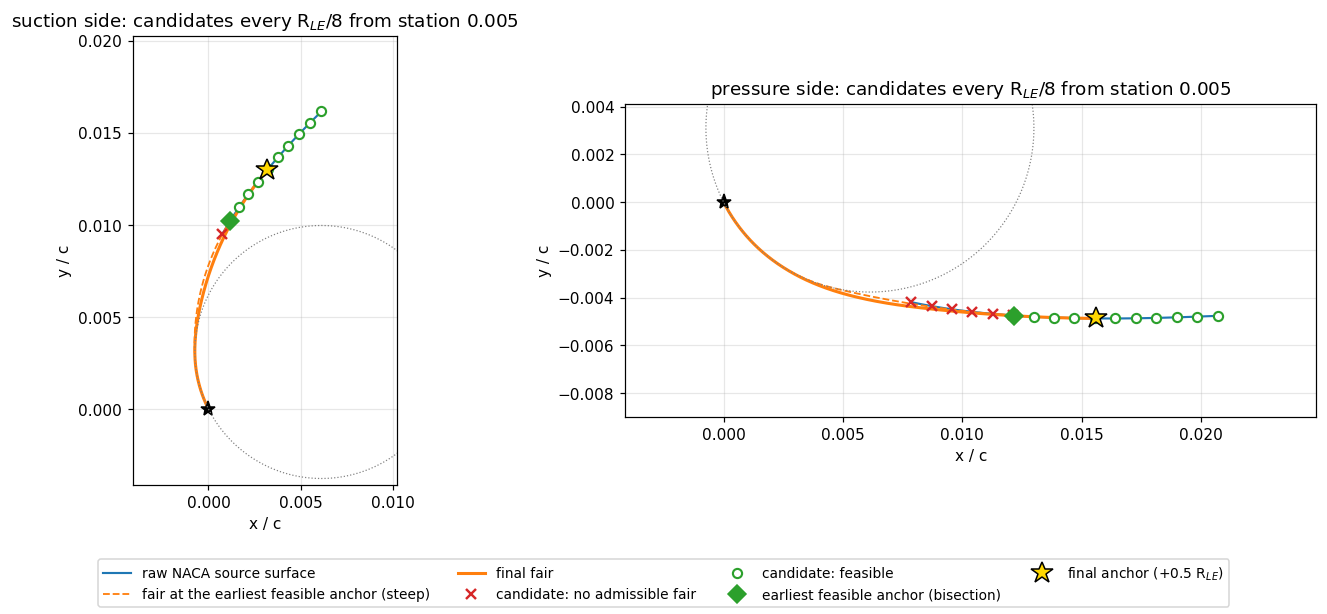

In [17]:
def anchor_scan(fit, side, extra=6):
    # the scan of fair_leading_edge replayed: candidates every LE_ANCHOR_STEP R_LE along the source from its start,
    # and whether a monotone-curvature fair lands on each (module internal _solve_le_fair, the one the scan calls)
    le, source = fit.leading_edge, fit.source
    step = geo.LE_ANCHOR_STEP * le.nose.radius
    s = source.start + step * np.arange(int(np.ceil((le.anchor - source.start) / step)) + extra)
    points, d1, d2 = source.evaluate(s)
    fairs = [geo._solve_le_fair(le.nose, side, p, a / np.hypot(*a), float(geo.signed_curvature(a[None], b[None])[0]), float(sk))
             for p, a, b, sk in zip(points, d1, d2, s)]
    return s, points, np.array([f is not None for f in fairs])


def fair_at(fit, side, s):
    # the fair the module builds for an anchor at source parameter s (module internal)
    p, a, b = (v[0] for v in fit.source.evaluate(np.array([s])))
    return geo._solve_le_fair(fit.leading_edge.nose, side, p, a / np.hypot(*a),
                              float(geo.signed_curvature(a[None], b[None])[0]), s)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, name, fit, curve, side, color in zip(axes, ("suction side", "pressure side"), robust_fits, robust_blade,
                                             (1.0, -1.0), side_colors):
    le, source = fit.leading_edge, fit.source
    s, points, feasible = anchor_scan(fit, side)
    boundary_fair = fair_at(fit, side, le.earliest_anchor)
    print(f"{name}: {np.count_nonzero(~feasible[:np.argmax(feasible)])} failing candidates, then feasible;  "
          f"earliest feasible anchor {(le.earliest_anchor - source.start) / R_LE:.3f} R_LE past station 0.005 "
          f"(fairness {boundary_fair.fairness:.2f});  final anchor +0.5 R_LE (fairness {le.fairness:.2f}, limit {geo.LE_FAIRNESS_LIMIT:g})")
    s_source = np.linspace(source.start, s[-1], 400)
    ax.plot(*source.evaluate(s_source)[0].T, color="tab:blue", lw=1.4, label="raw NACA source surface")
    ax.plot(*boundary_fair.points(np.linspace(0.0, boundary_fair.anchor_angle, 400)).T, "--", color="tab:orange",
            lw=1.2, label="fair at the earliest feasible anchor (steep)")
    ax.plot(*le.points(np.linspace(0.0, le.anchor_angle, 400)).T, color="tab:orange", lw=2.0, label="final fair")
    ax.plot(*points[~feasible].T, "x", ms=7, mew=1.6, color="tab:red", label="candidate: no admissible fair")
    ax.plot(*points[feasible].T, "o", ms=6, mfc="white", mew=1.4, color="tab:green", label="candidate: feasible")
    ax.plot(*source.evaluate(np.array([le.earliest_anchor]))[0][0], "D", ms=8, color="tab:green",
            label="earliest feasible anchor (bisection)")
    ax.plot(*source.evaluate(np.array([le.anchor]))[0][0], "*", ms=15, color="gold", mec="k", label="final anchor (+0.5 R$_{LE}$)")
    ax.plot(*le.nose.apex, "k*", ms=10)
    ax.plot(*(le.nose.center + le.nose.radius * circle).T, ":", color="0.5", lw=0.8)
    window = np.vstack((le.nose.apex, points))
    lo, hi = window.min(axis=0) - 0.6 * R_LE, window.max(axis=0) + 0.6 * R_LE
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x / c"); ax.set_ylabel("y / c")
    ax.set_title(f"{name}: candidates every R$_{{LE}}$/8 from station 0.005")
fig.legend(*axes[1].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

On the suction side only the candidate at station 0.005 itself fails, and the next one already admits a fair. On the pressure side the first six fail: the raw surface there is the one that points back across the chord. The fair at the feasibility boundary is the steepest admissible one. Its fairness energy (printed) is even above the limit of 4 on both surfaces of this blade. Half an LE radius further on, the final fair turns gently and its energy is about four to ten times smaller.

### 10.5 G2 matching at the anchor and C2 representation

At the anchor the fair ends on the source with

$$\mathbf X_{fair} = \mathbf X_{source}, \qquad \theta_{fair} = \theta_{source}, \qquad \kappa_{fair} = \kappa_{source} .$$

- **Position:** the landing equations.
- **Tangent:** the fair ends at the anchor's turning angle.
- **Curvature:** its last control radius is $1/|\kappa_a|$.

The physical surface is therefore **$G^2$**: position, tangent direction and curvature are continuous through the anchor, as they are at the apex and the departure. The final parametric quintic fitted to this target is **$C^2$ or higher** ($C^4$ at its knots), and its knots are refined to $0.01\,R_{LE}$ near the departure and the anchor.

This is what the solver needs: $\tan\beta = dy/dm$ and $d[\tan\beta]/dm = \kappa/\cos^3\beta$ are continuous through the whole LE region. $B \propto \tan\beta$ and $D = A_\eta - B_m$ are then free of the jumps of sections 8 and 9 there as well. Only $d\kappa/ds$ may jump at the anchor (the curvature has a kink there, not a step), and the quintic smooths that over its fine knot spans.

At the anchor: the fair's end against the source surface (both from the module's objects)
  SS: |X_fair - X_source| = 8.7e-18 c,  theta_fair - theta_source = -1.0e-14 deg,  kappa_fair = -30.531145 /c,  kappa_source = -30.531145 /c
  PS: |X_fair - X_source| = 4.3e-17 c,  theta_fair - theta_source = +1.9e-15 deg,  kappa_fair = 14.078613 /c,  kappa_source = 14.078613 /c


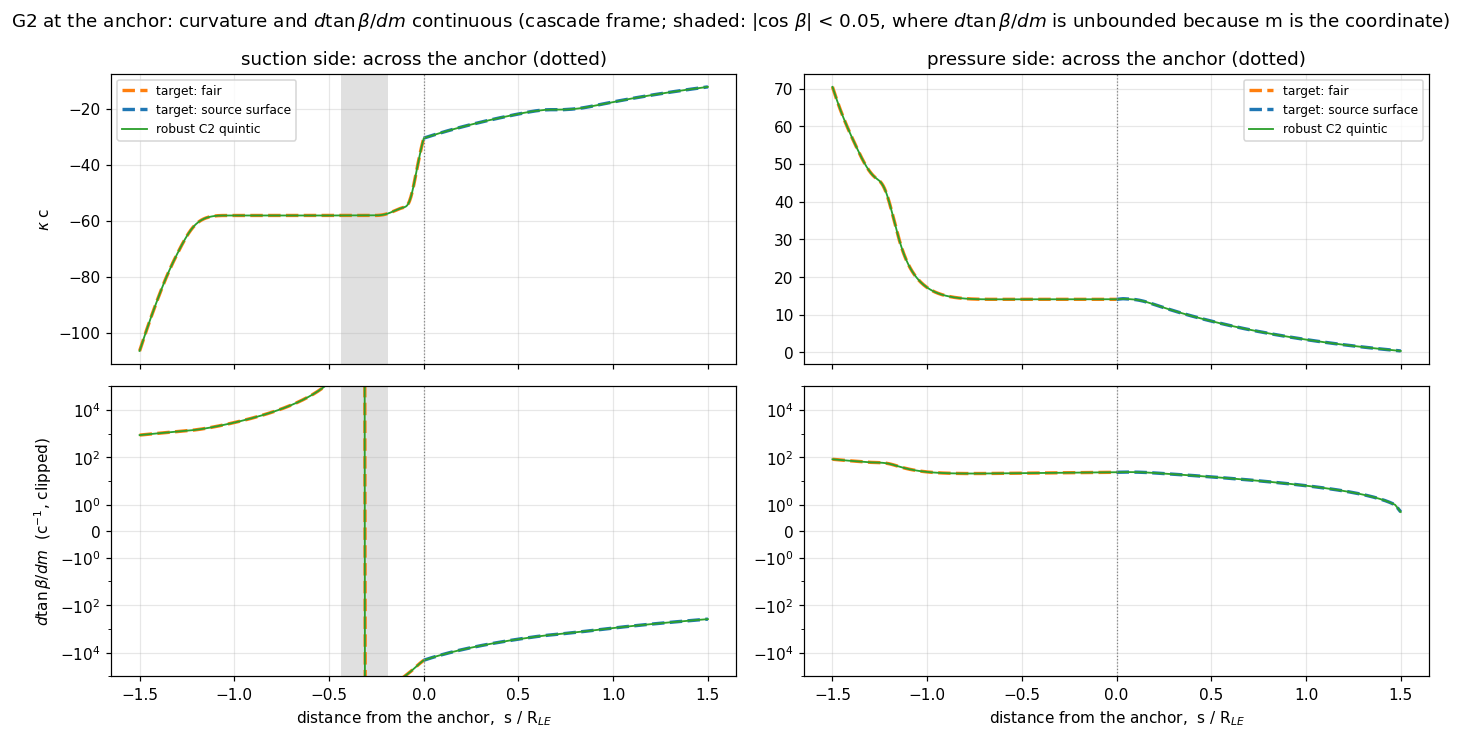

In [18]:
print("At the anchor: the fair's end against the source surface (both from the module's objects)")
for name, fit in zip(("SS", "PS"), robust_fits):
    le, source = fit.leading_edge, fit.source
    X_f, d1_f, d2_f = (v[0] for v in le.evaluate(np.array([1.0])))
    X_s, d1_s, d2_s = (v[0] for v in source.evaluate(np.array([le.anchor])))
    k_f, k_s = (float(geo.signed_curvature(a[None], b[None])[0]) for a, b in ((d1_f, d2_f), (d1_s, d2_s)))
    print(f"  {name}: |X_fair - X_source| = {np.hypot(*(X_f - X_s)):.1e} c,  theta_fair - theta_source = {turn(d1_f, d1_s):+.1e} deg,  "
          f"kappa_fair = {k_f:.6f} /c,  kappa_source = {k_s:.6f} /c")

fig, axes = plt.subplots(2, 2, figsize=(13, 6.8), sharex=True)
for col, (name, fit, curve) in enumerate(zip(("suction side", "pressure side"), robust_fits, robust_cascade_curves)):
    le, source = fit.leading_edge, fit.source
    phi = le.angle_at(np.linspace(le.length - 1.5 * R_LE, le.length, 400))
    _, d1, d2 = le.evaluate(phi / le.anchor_angle)
    x_fair = (le.arc_length(phi) - le.length) / R_LE
    s_src = np.linspace(le.anchor, le.anchor + 1.5 * R_LE, 400)
    _, e1, e2 = source.evaluate(s_src)
    x_src = (s_src - le.anchor) / R_LE
    u = fit.anchor_u + np.linspace(-1.5, 1.5, 1201) * R_LE / fit.length
    c1, c2 = curve.derivative(u, 1), curve.derivative(u, 2)
    x_c2 = (u - fit.anchor_u) * fit.length / R_LE
    for (x, a, b, style, color, label) in ((x_fair, d1, d2, "--", "tab:orange", "target: fair"),
                                           (x_src, e1, e2, "--", "tab:blue", "target: source surface")):
        a, b = a @ rotation.T, b @ rotation.T
        axes[0, col].plot(x, geo.signed_curvature(a, b), style, color=color, lw=2.2, label=label)
        axes[1, col].plot(x, geo.wall_slopes(a, b)[1], style, color=color, lw=2.2)
    axes[0, col].plot(x_c2, geo.signed_curvature(c1, c2), color="tab:green", lw=1.2, label="robust C2 quintic")
    axes[1, col].plot(x_c2, geo.wall_slopes(c1, c2)[1], color="tab:green", lw=1.2)
    near = np.abs(c1[:, 0]) < 0.05 * np.hypot(*c1.T)                  # |cos beta| < 0.05: m is singular there
    for ax in axes[:, col]:
        ax.axvline(0.0, color="0.5", lw=0.8, ls=":")
        if near.any():
            ax.fill_between(x_c2, 0, 1, where=near, transform=ax.get_xaxis_transform(), color="0.88", lw=0)
    axes[1, col].set_yscale("symlog", linthresh=1.0); axes[1, col].set_ylim(-1e5, 1e5)
    axes[1, col].set_yticks([-1e4, -1e2, -1.0, 0.0, 1.0, 1e2, 1e4])
    axes[0, col].set_title(f"{name}: across the anchor (dotted)")
    axes[0, col].legend(fontsize=8)
    axes[1, col].set_xlabel("distance from the anchor,  s / R$_{LE}$")
axes[0, 0].set_ylabel("$\\kappa$ c")
axes[1, 0].set_ylabel("$d\\tan\\beta/dm$  (c$^{-1}$, clipped)")
fig.suptitle("G2 at the anchor: curvature and $d\\tan\\beta/dm$ continuous (cascade frame; shaded: |cos $\\beta$| < 0.05, "
             "where $d\\tan\\beta/dm$ is unbounded because m is the coordinate)")
fig.tight_layout()
plt.show()

Position, tangent and curvature of the fair and the source agree at the anchor to round-off (printed). On the plots the target pieces and the quintic run through the anchor without a step in $\kappa$ or $d\tan\beta/dm$.

### 10.6 Before / after: legacy C1, legacy-derived C2, robust C2

The same LE region in the three geometries:

- **legacy C1:** the validated baseline;
- **legacy-derived C2:** section 9, the same shape with smooth derivatives;
- **robust C2:** the redesigned nose.

Legacy C1 and the old C2 both preserve the S-bend; the robust C2 changes the underlying LE geometry and removes it.

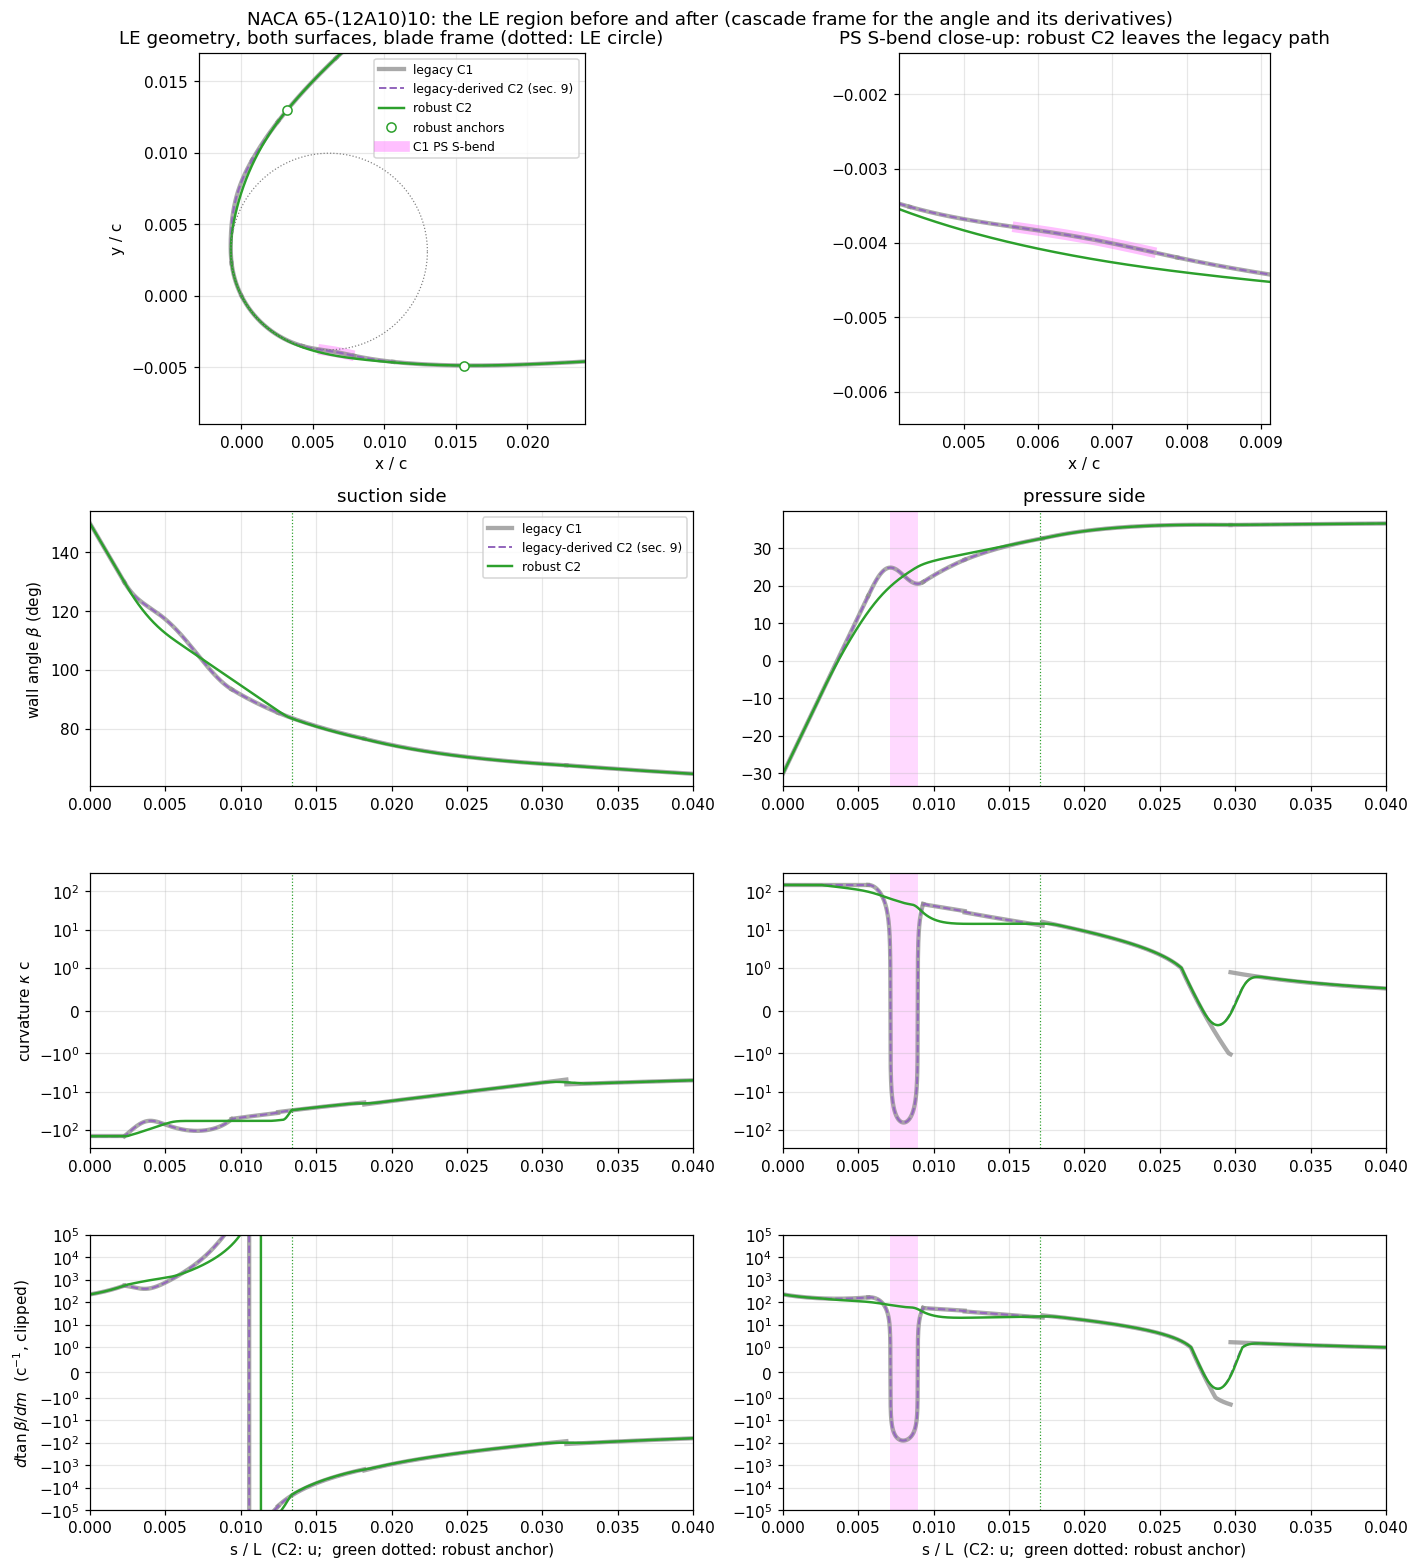

In [19]:
styles = {"legacy C1": dict(color="0.55", lw=2.8, alpha=0.75),
          "legacy-derived C2 (sec. 9)": dict(color="tab:purple", lw=1.3, ls="--"),
          "robust C2": dict(color="tab:green", lw=1.6)}
u_le = np.linspace(0.0, 0.04, 8001)


def c1_le_quantities(reference, u_end=0.04):
    # C1 piece by piece up to s/L = u_end: (u, blade-frame points, beta, kappa, dtan beta/dm in the cascade frame)
    out = []
    for k, (lo, hi) in enumerate(reference.piece_bounds):
        if lo < u_end * reference.length:
            sample = reference.sample_piece(k, np.linspace(lo, hi, 800))
            keep = sample.s <= u_end * reference.length
            beta, kappa, dtan, _ = solver_quantities(sample)
            out.append((sample.s[keep] / reference.length, sample.points[keep], beta[keep], kappa[keep], dtan[keep]))
    return out


def curve_le_quantities(blade_curve, cascade_curve, u):
    d1, d2 = cascade_curve.derivative(u, 1), cascade_curve.derivative(u, 2)
    return (u, blade_curve.evaluate(u), np.degrees(np.arctan2(d1[:, 1], d1[:, 0])), geo.signed_curvature(d1, d2),
            geo.wall_slopes(d1, d2)[1])


fig = plt.figure(figsize=(13, 14.5))
layout = fig.add_gridspec(4, 2, height_ratios=(1.35, 1, 1, 1))
ax_nose, ax_bend = fig.add_subplot(layout[0, 0]), fig.add_subplot(layout[0, 1])
axes = np.array([[fig.add_subplot(layout[row, col]) for col in range(2)] for row in range(1, 4)])
for col, (name, reference, fit, cascade_legacy, blade_robust, cascade_robust, key) in enumerate(zip(
        ("suction side", "pressure side"), c1_refs, legacy_c2, legacy_c2_cascade, robust_blade, robust_cascade_curves,
        ("ss", "ps"))):
    curves = {"legacy C1": c1_le_quantities(reference),
              "legacy-derived C2 (sec. 9)": [curve_le_quantities(fit.curve, cascade_legacy, u_le)],
              "robust C2": [curve_le_quantities(blade_robust, cascade_robust, u_le)]}
    for label, runs in curves.items():
        for n, (u, points, beta, kappa, dtan) in enumerate(runs):
            tag = label if n == 0 else None
            for ax in (ax_nose, ax_bend):
                ax.plot(*points.T, label=tag if col == 0 else None, **styles[label])
            for row, value in enumerate((beta, kappa, dtan)):
                axes[row, col].plot(u, value, label=tag, **styles[label])
    u_anchor = robust_meta[f"{key}_le_anchor_u"]
    for ax in (ax_nose, ax_bend):
        ax.plot(*blade_robust.evaluate(u_anchor), "o", ms=6, mfc="white", color="tab:green", zorder=5,
                label="robust anchors" if col == 0 and ax is ax_nose else None)
    for ax in axes[:, col]:
        ax.axvline(u_anchor, color="tab:green", lw=0.8, ls=":")
        ax.set_xlim(0.0, 0.04)
    axes[0, col].set_title(name)
    axes[1, col].set_yscale("symlog", linthresh=1.0); axes[1, col].set_ylim(-300.0, 300.0)
    axes[2, col].set_yscale("symlog", linthresh=1.0); axes[2, col].set_ylim(-1e5, 1e5)
    axes[2, col].set_xlabel("s / L  (C2: u;  green dotted: robust anchor)")
if sbend_turn > 0.0:
    for ax in (ax_nose, ax_bend):
        ax.plot(*sbend_fair.points[sbend_rows].T, color="magenta", lw=7, alpha=0.25, zorder=0,
                label="C1 PS S-bend" if ax is ax_nose else None)
    bend = sbend_fair.s[sbend_rows] / c1_refs[1].length
    for ax in axes[:, 1]:
        ax.axvspan(bend.min(), bend.max(), color="magenta", alpha=0.15, lw=0)
ax_nose.plot(*(le_centre + le_radius * circle).T, ":", color="0.5", lw=0.8)
ax_nose.set_xlim(-0.003, 0.024); ax_nose.set_ylim(-0.009, 0.017)
ax_nose.set_title("LE geometry, both surfaces, blade frame (dotted: LE circle)")
ax_nose.legend(fontsize=8, loc="upper right")
centre = sbend_fair.points[sbend_rows].mean(axis=0)
ax_bend.set_xlim(centre[0] - 0.0025, centre[0] + 0.0025); ax_bend.set_ylim(centre[1] - 0.0025, centre[1] + 0.0025)
ax_bend.set_title("PS S-bend close-up: robust C2 leaves the legacy path")
for ax in (ax_nose, ax_bend):
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x / c")
ax_nose.set_ylabel("y / c")
axes[0, 0].set_ylabel("wall angle $\\beta$ (deg)")
axes[1, 0].set_ylabel("curvature $\\kappa$ c")
axes[2, 0].set_ylabel("$d\\tan\\beta/dm$  (c$^{-1}$, clipped)")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle(f"{designation}: the LE region before and after (cascade frame for the angle and its derivatives)")
fig.tight_layout()
plt.show()

On the pressure side the grey C1 and the dashed legacy-derived C2 lie on top of each other through the S-bend: the curvature dips below zero and $\beta$ turns back. The robust C2 (green) leaves the nose circle and falls monotonically to the table surface instead. Past the anchor all three coincide. The suction side was already clean; there the robust fair differs from the legacy one by a few $10^{-4}\,c$ and has a smoother curvature run.

### 10.7 Thin-blade example: 65-(12A10)04

Thin blades are where the legacy closure is worst: the nose circle shrinks with $t^2$ while the station-0.005 data keep their direction.

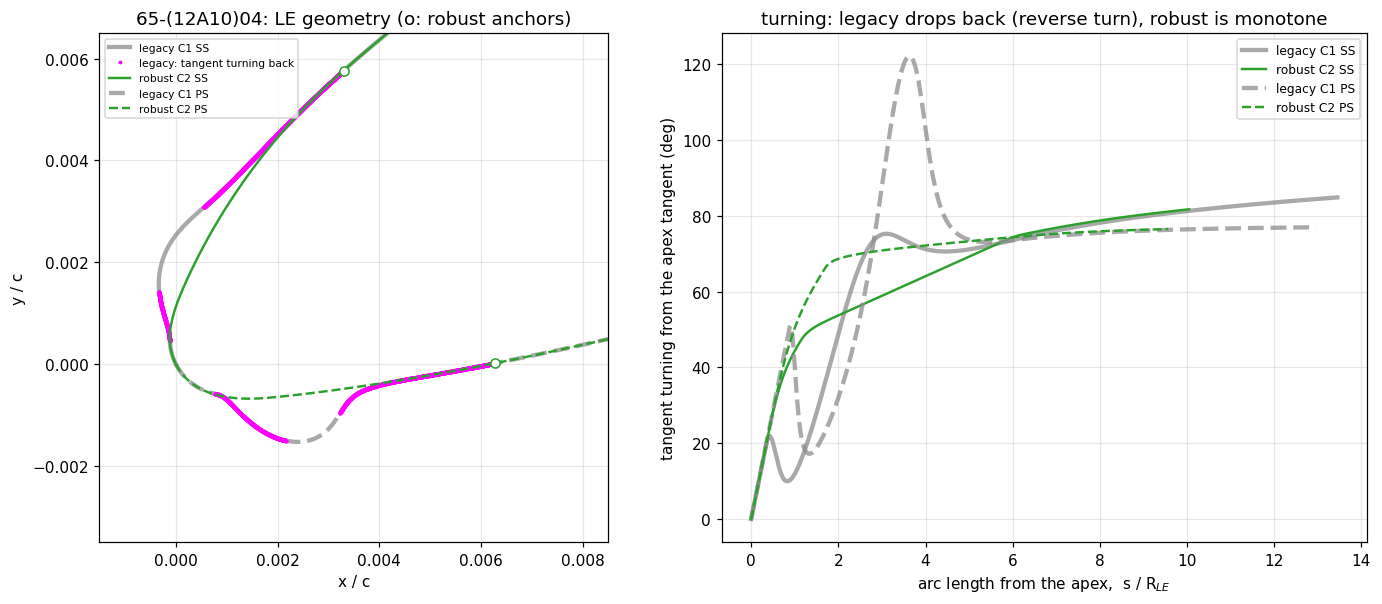

| blade | legacy reverse turn SS | robust reverse turn SS | legacy reverse turn PS | robust reverse turn PS | max LE-zone deviation SS / PS |
|---|---:|---:|---:|---:|---:|
| 65-(12A10)10 | 0.00° | 0.00° | 4.32° | 0.00° | 2.5e-04 / 2.6e-04 c |
| 65-(16A10)10 | 0.00° | 0.00° | 8.13° | 0.00° | 3.2e-04 / 3.0e-04 c |
| 65-(12A10)05 | 0.00° | 0.00° | 12.28° | 0.00° | 3.1e-04 / 3.2e-04 c |
| 65-(12A10)04 | 11.94° | 0.00° | 49.00° | 0.00° | 6.1e-04 / 9.3e-04 c |
| 65-(0A10)04 | 26.57° | 0.00° | 26.57° | 0.00° | 8.7e-04 / 8.7e-04 c |

In [20]:
from IPython.display import Markdown, display

robust_cache = {(spec.cl0, spec.t_max_over_c): robust}


def robust_cascade(cl0, t):
    # the robust C2 cascade of the default spec with cl0 and t/c replaced (cached)
    key = (float(cl0), float(t))
    if key not in robust_cache:
        robust_cache[key] = geo.make_cascade(replace(spec, cl0=float(cl0), t_max_over_c=float(t), surface_continuity="C2"))
    return robust_cache[key]


def le_comparison(cl0, t):
    # legacy vs robust over the LE zone (apex -> robust anchor), per surface
    c2 = robust_cascade(cl0, t)
    references = geo.naca65_reference_surfaces(cl0, t, profile_variant=spec.profile_variant, thickness_reconstruction=geo.DEFAULT_THICKNESS_RECONSTRUCTION["C2"])
    curves = (c2.normalized_curves.suction_unstaggered, c2.normalized_curves.pressure_unstaggered)
    out = {}
    for key, reference, curve in zip(("ss", "ps"), references, curves):
        robust_fairness = geo.leading_edge_fairness(curve, c2.metadata[f"{key}_le_anchor_u"])
        legacy_turn, legacy_signs = c1_le_metrics(reference, c2.metadata[f"{key}_le_anchor_over_c"])
        out[key] = dict(legacy_turn=legacy_turn, legacy_signs=legacy_signs,
                        robust_turn=robust_fairness["max_reverse_turn_deg"], robust_signs=robust_fairness["sign_changes"],
                        deviation=c2.metadata[f"{key}_le_max_deviation_over_c"],
                        anchor=c2.metadata[f"{key}_le_anchor_past_source_start_over_c"],
                        departure=c2.metadata[f"{key}_le_departure_deg"])
    return out


def name_of(cl0, t):
    return f"65-({10 * cl0:g}A10){100 * t:02.0f}"


thin = (1.2, 0.04)
c2_thin = robust_cascade(*thin)
refs_thin = geo.naca65_reference_surfaces(*thin, profile_variant=spec.profile_variant, thickness_reconstruction=geo.DEFAULT_THICKNESS_RECONSTRUCTION["C2"])
R_thin = c2_thin.metadata["le_radius_over_c"]
fig, (ax_g, ax_t) = plt.subplots(1, 2, figsize=(13, 5.6), width_ratios=(1.0, 1.1))
for key, reference, curve, ls in zip(("ss", "ps"), refs_thin,
                                     (c2_thin.normalized_curves.suction_unstaggered, c2_thin.normalized_curves.pressure_unstaggered),
                                     ("-", "--")):
    s_end = c2_thin.metadata[f"{key}_le_anchor_over_c"]
    pieces = [reference.sample_piece(k, np.linspace(lo, hi, 2000)) for k, (lo, hi) in enumerate(reference.piece_bounds)
              if lo < 1.6 * s_end]
    s = np.concatenate([p.s for p in pieces]); points = np.concatenate([p.points for p in pieces])
    tangent = np.concatenate([p.tangent for p in pieces]); kappa0 = pieces[0].kappa[0]
    angle = np.sign(kappa0) * np.degrees(np.unwrap(np.arctan2(tangent[:, 1], tangent[:, 0])))
    turning = angle - angle[0]
    back = (np.maximum.accumulate(turning) - turning > 1e-3) & (s <= s_end)
    ax_g.plot(*points.T, ls, label=f"legacy C1 {key.upper()}", **{k: v for k, v in styles["legacy C1"].items()})
    ax_g.plot(*points[back].T, ".", ms=3, color="magenta", label="legacy: tangent turning back" if key == "ss" else None)
    u = np.linspace(0.0, 1.6 * c2_thin.metadata[f"{key}_le_anchor_u"], 2000)
    d1 = curve.derivative(u, 1)
    angle_c2 = np.sign(float(curve.curvature(0.0))) * np.degrees(np.unwrap(np.arctan2(d1[:, 1], d1[:, 0])))
    ax_g.plot(*curve.evaluate(u).T, ls, color="tab:green", lw=1.6, label=f"robust C2 {key.upper()}")
    ax_g.plot(*curve.evaluate(c2_thin.metadata[f"{key}_le_anchor_u"]), "o", ms=6, mfc="white", color="tab:green")
    ax_t.plot(s / R_thin, turning, ls, label=f"legacy C1 {key.upper()}", **{k: v for k, v in styles["legacy C1"].items()})
    ax_t.plot(u * curve.reference_length / R_thin, angle_c2 - angle_c2[0], ls, color="tab:green", lw=1.6,
              label=f"robust C2 {key.upper()}")
ax_g.set_aspect("equal", adjustable="box")
ax_g.set_xlim(-0.0015, 0.0085); ax_g.set_ylim(-0.0035, 0.0065)
ax_g.set_xlabel("x / c"); ax_g.set_ylabel("y / c")
ax_g.set_title(f"{name_of(*thin)}: LE geometry (o: robust anchors)")
ax_g.legend(fontsize=7, loc="upper left")
ax_t.set_xlabel("arc length from the apex,  s / R$_{LE}$")
ax_t.set_ylabel("tangent turning from the apex tangent (deg)")
ax_t.set_title("turning: legacy drops back (reverse turn), robust is monotone")
ax_t.legend(fontsize=8)
fig.tight_layout()
plt.show()

cases = [(1.2, 0.10), (1.6, 0.10), (1.2, 0.05), (1.2, 0.04), (0.0, 0.04)]
lines = ["| blade | legacy reverse turn SS | robust reverse turn SS | legacy reverse turn PS | robust reverse turn PS | "
         "max LE-zone deviation SS / PS |", "|---|---:|---:|---:|---:|---:|"]
for cl0, t in cases:
    m = le_comparison(cl0, t)
    lines.append(f"| {name_of(cl0, t)} | {m['ss']['legacy_turn']:.2f}° | {m['ss']['robust_turn']:.2f}° | "
                 f"{m['ps']['legacy_turn']:.2f}° | {m['ps']['robust_turn']:.2f}° | "
                 f"{m['ss']['deviation']:.1e} / {m['ps']['deviation']:.1e} c |")
display(Markdown("\n".join(lines)))

The reverse turn is measured over the LE zone, from the apex to the robust anchor. It is the largest drop of the tangent angle below its running maximum, counted in the sense of the apex curvature. For the legacy column it is measured on the exact C1 surface, and for the robust column on the C2 curve (`geo.leading_edge_fairness`). The deviation is the largest normal distance between the robust C2 and C1 over the same zone: the price of the redesign, a few $10^{-4}\,c$. Downstream of the anchor the two stay within $10^{-6}\,c$.

On the thin blade the legacy nose turns back on both surfaces (magenta) and folds into the chin-like shape; the robust nose turns monotonically on both.

## 11. Parametric robustness study

Is the robust LE fitted only to the 65-(12A10)10? Here the same algorithm runs, with no change of any setting, over a thickness sweep and a camber sweep. Every blade is a full `make_cascade(... surface_continuity="C2")`.

### 11.1 Thickness sweep, $c_{l0} = 1.2$

LE close-ups on common axes. In the right panel the curvature and the arc length are both normalized by each blade's own $R_{LE}$, so all noses start at $|\kappa| R_{LE} = 1$.

blade             robust rev SS  robust rev PS  sign chg SS/PS   legacy rev SS/PS (deg)
65-(12A10)04         0.00e+00°     0.00e+00°         0 / 0           11.94 / 49.00
65-(12A10)05         0.00e+00°     0.00e+00°         0 / 0            0.00 / 12.28


65-(12A10)06         0.00e+00°     0.00e+00°         0 / 0            0.00 / 3.45


65-(12A10)08         0.00e+00°     0.00e+00°         0 / 0            0.00 / 1.28
65-(12A10)10         0.00e+00°     0.00e+00°         0 / 0            0.00 / 4.32


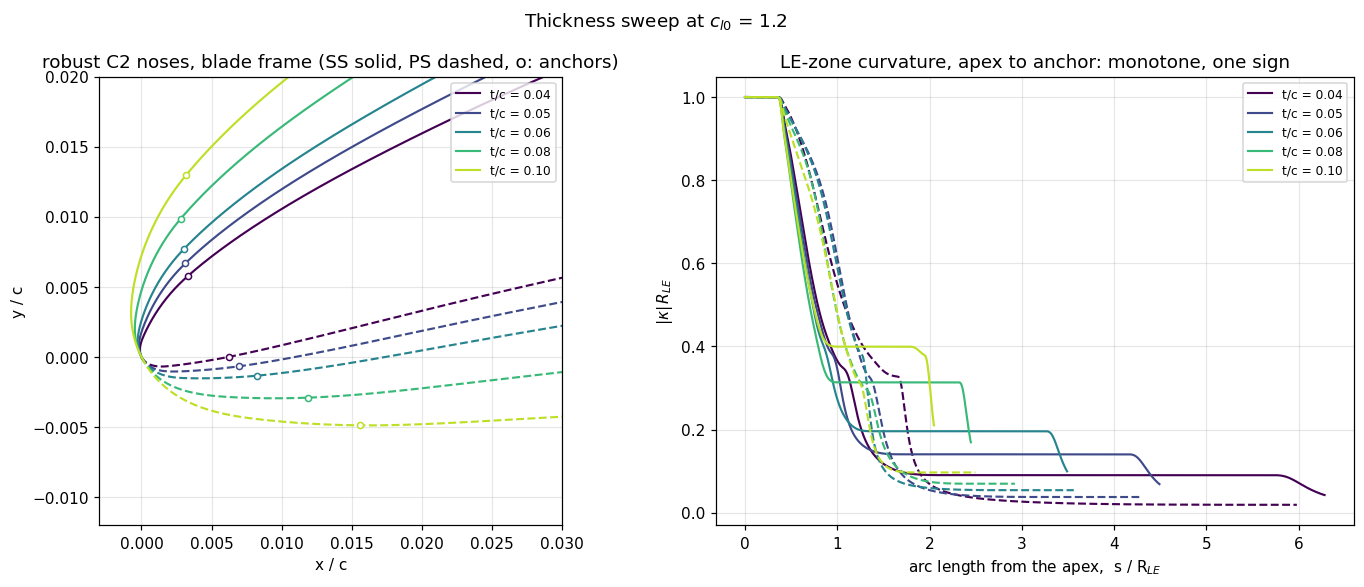

In [21]:
def sweep_figure(cases, labels, title):
    fig, (ax_g, ax_k) = plt.subplots(1, 2, figsize=(13, 5.4), width_ratios=(1.0, 1.1))
    palette = plt.get_cmap("viridis")
    print(f"{'blade':16s} {'robust rev SS':>14s} {'robust rev PS':>14s} {'sign chg SS/PS':>15s} {'legacy rev SS/PS (deg)':>24s}")
    for n, ((cl0, t), label) in enumerate(zip(cases, labels)):
        color = palette(0.9 * n / max(1, len(cases) - 1))
        c2 = robust_cascade(cl0, t)
        R = c2.metadata["le_radius_over_c"]
        for key, curve, ls in (("ss", c2.normalized_curves.suction_unstaggered, "-"),
                               ("ps", c2.normalized_curves.pressure_unstaggered, "--")):
            u_a = c2.metadata[f"{key}_le_anchor_u"]
            ax_g.plot(*curve.evaluate(np.linspace(0.0, 0.05, 3001)).T, ls, color=color, lw=1.4,
                      label=label if key == "ss" else None)
            ax_g.plot(*curve.evaluate(u_a), "o", ms=4, mfc="white", color=color)
            u = np.linspace(0.0, u_a, 1501)
            ax_k.plot(u * curve.reference_length / R, np.abs(curve.curvature(u)) * R, ls, color=color, lw=1.4,
                      label=label if key == "ss" else None)
        m = le_comparison(cl0, t)
        print(f"{name_of(cl0, t):16s} {m['ss']['robust_turn']:12.2e}° {m['ps']['robust_turn']:12.2e}° "
              f"{m['ss']['robust_signs']:>9d} / {m['ps']['robust_signs']:<4d} {m['ss']['legacy_turn']:12.2f} / {m['ps']['legacy_turn']:.2f}")
    ax_g.set_aspect("equal", adjustable="box")
    ax_g.set_xlim(-0.003, 0.03); ax_g.set_ylim(-0.012, 0.02)
    ax_g.set_xlabel("x / c"); ax_g.set_ylabel("y / c")
    ax_g.set_title("robust C2 noses, blade frame (SS solid, PS dashed, o: anchors)")
    ax_g.legend(fontsize=8, loc="upper right")
    ax_k.set_xlabel("arc length from the apex,  s / R$_{LE}$")
    ax_k.set_ylabel("$|\\kappa|\\,R_{LE}$")
    ax_k.set_title("LE-zone curvature, apex to anchor: monotone, one sign")
    ax_k.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


thickness_cases = [(1.2, t) for t in (0.04, 0.05, 0.06, 0.08, 0.10)]
sweep_figure(thickness_cases, [f"t/c = {t:.2f}" for _, t in thickness_cases], "Thickness sweep at $c_{l0}$ = 1.2")

Every robust nose is inflection-free in the fair (no curvature sign change), has no reverse turn and no chin: zero on every blade (printed). The legacy closure turns back on the PS of every blade of this sweep, by 1.3° to 49°, most on the thinnest, and at $t/c$ = 0.04 on the SS too (last column).

### 11.2 Camber sweep, $t/c = 0.10$

blade             robust rev SS  robust rev PS  sign chg SS/PS   legacy rev SS/PS (deg)


65-(0A10)10          0.00e+00°     0.00e+00°         0 / 0            0.00 / 0.00


65-(4A10)10          0.00e+00°     0.00e+00°         0 / 0            0.00 / 0.00


65-(8A10)10          0.00e+00°     0.00e+00°         0 / 0            0.00 / 0.60
65-(12A10)10         0.00e+00°     0.00e+00°         0 / 0            0.00 / 4.32
65-(16A10)10         0.00e+00°     0.00e+00°         0 / 0            0.00 / 8.13


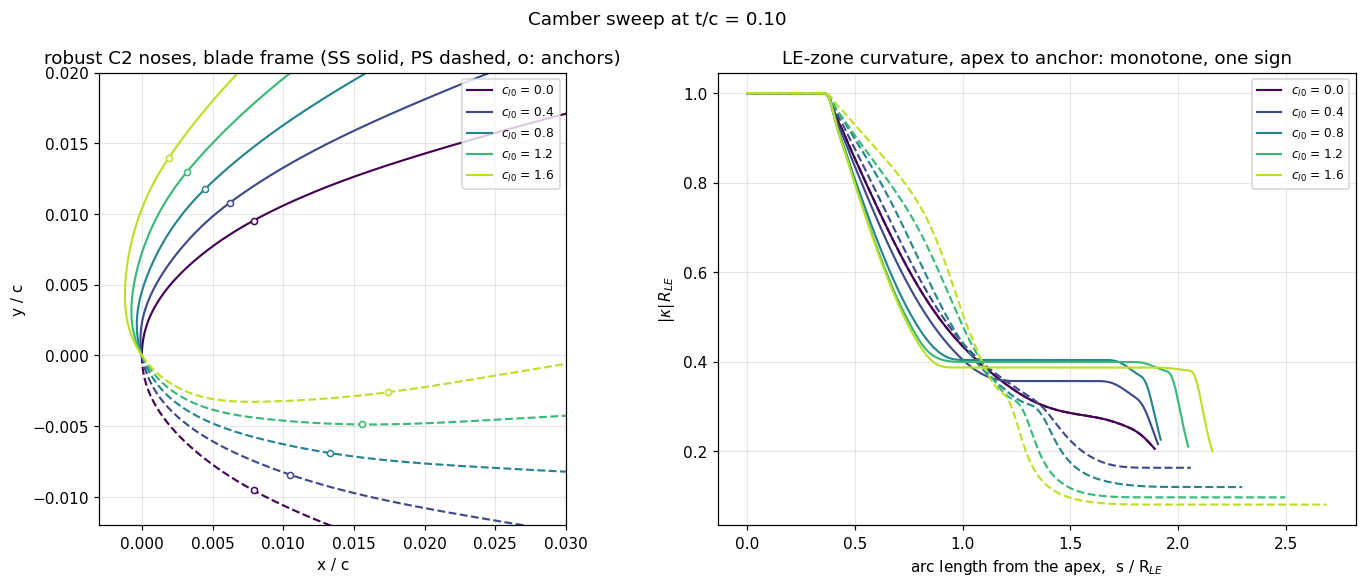

In [22]:
camber_cases = [(cl0, 0.10) for cl0 in (0.0, 0.4, 0.8, 1.2, 1.6)]
sweep_figure(camber_cases, [f"$c_{{l0}}$ = {cl0:.1f}" for cl0, _ in camber_cases], "Camber sweep at t/c = 0.10")

The same holds over the camber range. The legacy PS reverse turn is zero up to $c_{l0}$ = 0.4 and grows from 0.6° at $c_{l0}$ = 0.8 to 8.1° at 1.6; the robust one stays zero on both surfaces.

### 11.3 Adaptive-anchor behaviour

How does the anchor move through design space? The plots use denser sweeps (13 blades each) of the LE fair alone (`geo.fair_leading_edge`, the step `make_cascade` calls), with the five-blade sweeps above as markers.

A simple fairness-threshold anchor rule, "the earliest anchor whose fair stays within a fairness budget", produced branch switching. The fairness energy is not monotone along the source, so its first crossing of the budget jumped between branches as the blade changed: measured, $2\text{–}4\times10^{-5}\,c$ steps of the LE between neighbouring blades. The final rule uses the earliest feasible anchor plus $0.5\,R_{LE}$. The feasibility boundary is a clean edge that moves continuously, and this rule removed the observed discontinuous jumps.

  t sweep, SS: anchor 0.00055 .. 0.00426 c past station 0.005, largest step between neighbours 0.00080 c;  departure 20.75 .. 21.00 deg, largest step 0.07 deg
  t sweep, PS: anchor 0.00055 .. 0.00775 c past station 0.005, largest step between neighbours 0.00088 c;  departure 20.97 .. 21.49 deg, largest step 0.15 deg
cl0 sweep, SS: anchor 0.00344 .. 0.00500 c past station 0.005, largest step between neighbours 0.00041 c;  departure 20.76 .. 20.83 deg, largest step 0.01 deg
cl0 sweep, PS: anchor 0.00344 .. 0.00903 c past station 0.005, largest step between neighbours 0.00082 c;  departure 20.83 .. 21.14 deg, largest step 0.11 deg


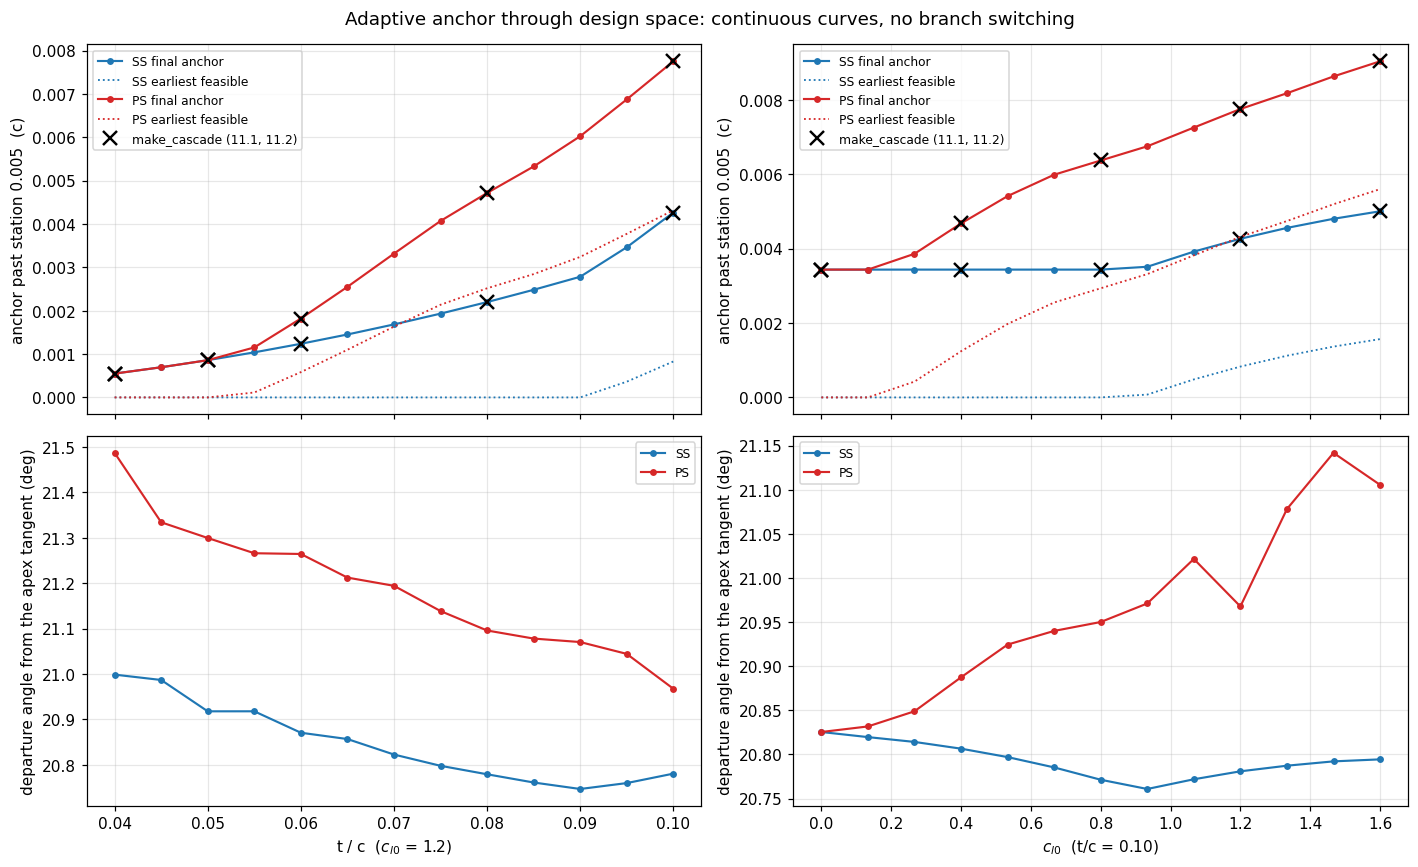

In [23]:
def le_anchor_data(cl0, t):
    # anchor and departure of the robust LE fair alone, per surface, by the module's own steps
    references = geo.naca65_reference_surfaces(cl0, t, profile_variant=spec.profile_variant, thickness_reconstruction=geo.DEFAULT_THICKNESS_RECONSTRUCTION["C2"])
    out = {}
    for key, reference, side in zip(("ss", "ps"), references, (1.0, -1.0)):
        nose = geo._naca65_nose(cl0, t, reference.leading_edge_point)          # module internal: the NACA 65 nose circle
        source = geo.SmoothedSurface(reference, geo.NACA65_FIRST_SURFACE_PIECE)
        fair = geo.fair_leading_edge(nose, side, source)
        out[key] = (fair.anchor - source.start, fair.earliest_anchor - source.start, math.degrees(fair.departure_angle))
    return out


dense = {"t": [(1.2, float(t)) for t in np.linspace(0.04, 0.10, 13)],
         "cl0": [(float(c), 0.10) for c in np.linspace(0.0, 1.6, 13)]}
dense_data = {name: [le_anchor_data(*case) for case in sweep] for name, sweep in dense.items()}

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex="col")
for col, (name, index, xlabel, markers) in enumerate((("t", 1, "t / c  ($c_{l0}$ = 1.2)", thickness_cases),
                                                      ("cl0", 0, "$c_{l0}$  (t/c = 0.10)", camber_cases))):
    x = np.array([case[index] for case in dense[name]])
    for key, color, label in (("ss", "tab:blue", "SS"), ("ps", "tab:red", "PS")):
        anchor = np.array([d[key][0] for d in dense_data[name]])
        earliest = np.array([d[key][1] for d in dense_data[name]])
        departure = np.array([d[key][2] for d in dense_data[name]])
        axes[0, col].plot(x, anchor, "-o", ms=3.5, color=color, lw=1.4, label=f"{label} final anchor")
        axes[0, col].plot(x, earliest, ":", color=color, lw=1.2, label=f"{label} earliest feasible")
        axes[1, col].plot(x, departure, "-o", ms=3.5, color=color, lw=1.4, label=label)
        check = [robust_cascade(*case).metadata for case in markers]
        axes[0, col].plot([case[index] for case in markers], [m[f"{key}_le_anchor_past_source_start_over_c"] for m in check],
                          "x", ms=9, mew=1.6, color="k", label="make_cascade (11.1, 11.2)" if key == "ps" else None)
        print(f"{name:>3s} sweep, {label}: anchor {anchor.min():.5f} .. {anchor.max():.5f} c past station 0.005, "
              f"largest step between neighbours {np.abs(np.diff(anchor)).max():.5f} c;  departure {departure.min():.2f} .. "
              f"{departure.max():.2f} deg, largest step {np.abs(np.diff(departure)).max():.2f} deg")
    axes[0, col].set_ylabel("anchor past station 0.005  (c)")
    axes[0, col].legend(fontsize=8)
    axes[1, col].set_ylabel("departure angle from the apex tangent (deg)")
    axes[1, col].set_xlabel(xlabel)
    axes[1, col].legend(fontsize=8)
fig.suptitle("Adaptive anchor through design space: continuous curves, no branch switching")
fig.tight_layout()
plt.show()

The anchor curves are continuous on both surfaces: the steps between neighbouring blades follow the trend, with no isolated jump. There are two regimes:

- where a fair already exists at station 0.005 (the SS of most of these blades, and the PS of the thinnest and least cambered ones), the earliest feasible anchor is the source start itself (dotted line at zero). The anchor is then $0.5\,R_{LE}$ past it and follows $R_{LE} \propto t^2$;
- elsewhere the anchor follows the feasibility boundary.

The change from one regime to the other is a kink, not a jump. The departure angle stays between about 20.7° and 21.5°, just past the 20° circle arc, and moves by at most about 0.15° between neighbouring blades.

### 11.4 Fairness metrics over the sweeps

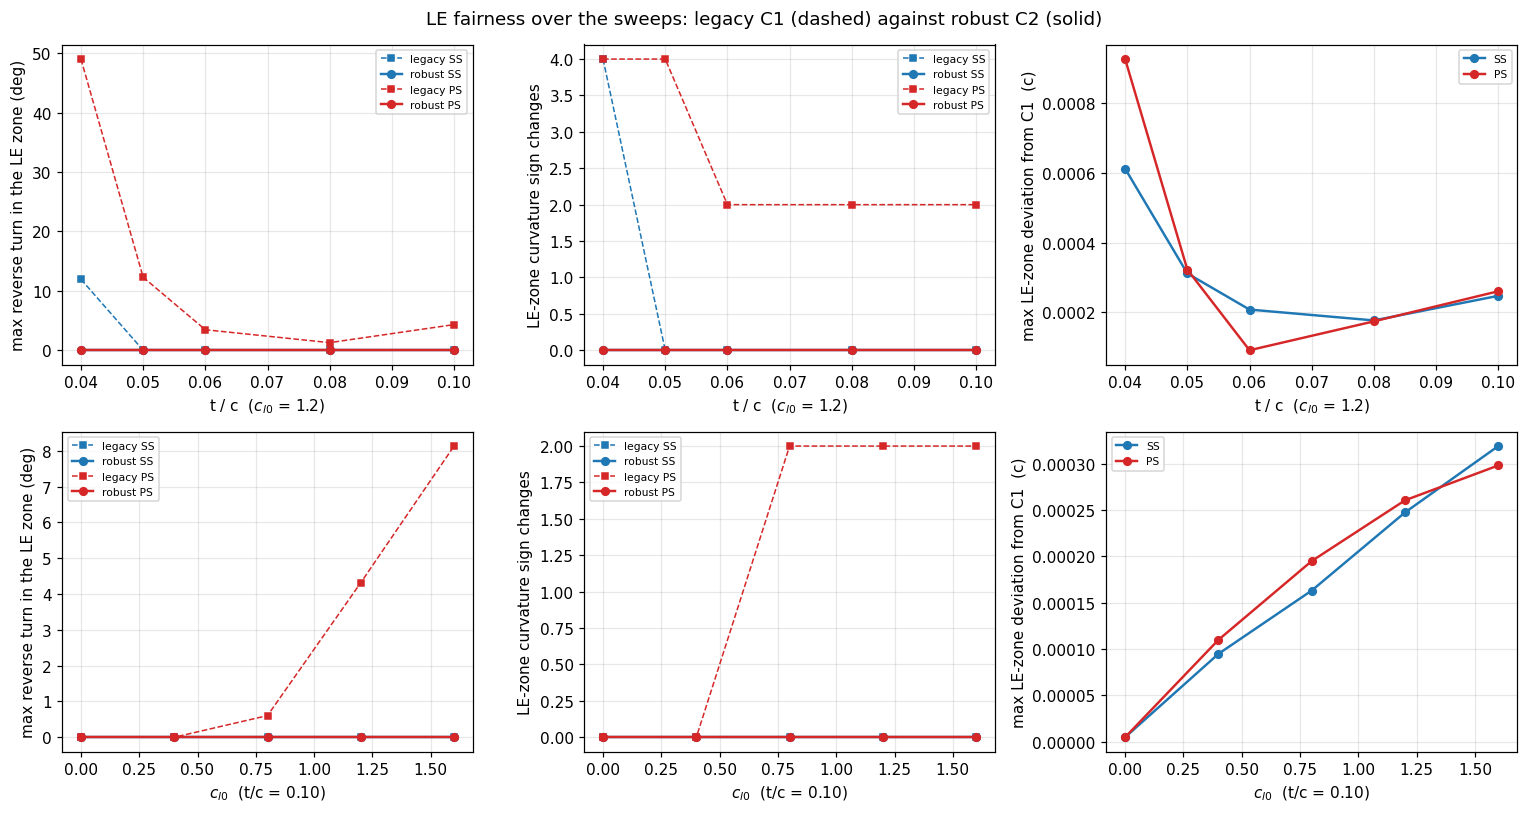

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for row, (cases_, index, xlabel) in enumerate(((thickness_cases, 1, "t / c  ($c_{l0}$ = 1.2)"),
                                               (camber_cases, 0, "$c_{l0}$  (t/c = 0.10)"))):
    x = [case[index] for case in cases_]
    metrics = [le_comparison(*case) for case in cases_]
    for key, color, label in (("ss", "tab:blue", "SS"), ("ps", "tab:red", "PS")):
        axes[row, 0].plot(x, [m[key]["legacy_turn"] for m in metrics], "--s", ms=4, color=color, lw=1.0, label=f"legacy {label}")
        axes[row, 0].plot(x, [m[key]["robust_turn"] for m in metrics], "-o", ms=5, color=color, lw=1.6, label=f"robust {label}")
        axes[row, 1].plot(x, [m[key]["legacy_signs"] for m in metrics], "--s", ms=4, color=color, lw=1.0, label=f"legacy {label}")
        axes[row, 1].plot(x, [m[key]["robust_signs"] for m in metrics], "-o", ms=5, color=color, lw=1.6, label=f"robust {label}")
        axes[row, 2].plot(x, [m[key]["deviation"] for m in metrics], "-o", ms=5, color=color, lw=1.6, label=label)
    axes[row, 0].set_ylabel("max reverse turn in the LE zone (deg)")
    axes[row, 1].set_ylabel("LE-zone curvature sign changes")
    axes[row, 2].set_ylabel("max LE-zone deviation from C1  (c)")
    for ax in axes[row]:
        ax.set_xlabel(xlabel)
        ax.legend(fontsize=7)
fig.suptitle("LE fairness over the sweeps: legacy C1 (dashed) against robust C2 (solid)")
fig.tight_layout()
plt.show()

Over the whole tested range the robust LE has **reverse turn = 0** and **curvature sign changes = 0** on both surfaces. The legacy closure turns back on the PS of every blade of the thickness sweep and of the camber sweep from $c_{l0}$ = 0.8 on, and on both surfaces of the 65-(12A10)04. The geometric price, the LE-zone deviation from C1, stays below $10^{-3}\,c$. It grows with camber and is largest on the thinnest blade, where the legacy nose is most defective.

## 12. Final geometry output

**What is the final solver-ready single-blade geometry?** The robust C2 NACA 65-(12A10)10 of the inputs (section 2):

- two quintic B-spline surfaces, at least $C^2$ (C4 at the knots);
- the redesigned monotone-curvature LE;
- within $10^{-6}\,c$ of the validated C1 construction downstream of the LE zone.

The cascade frame is used: $m$ axial, $y$ tangential, the chord at the stagger angle.

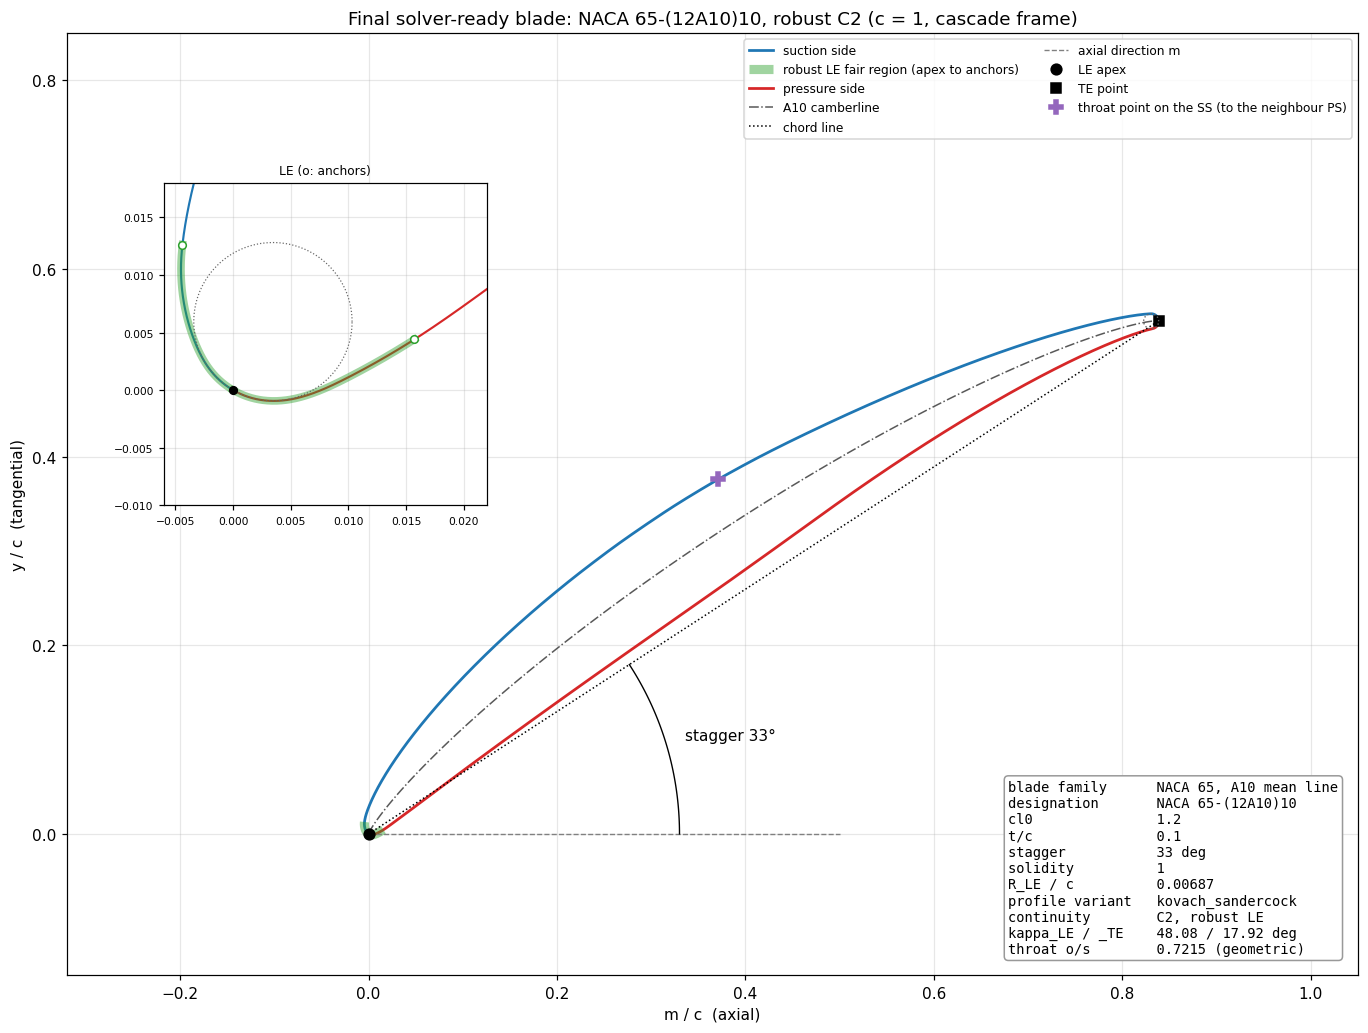

In [25]:
final = robust
coords, meta_final = final.normalized, final.metadata
u_final = np.unique(np.concatenate((np.linspace(0.0, 1.0, 8001), np.linspace(0.0, 0.03, 3001), np.linspace(0.97, 1.0, 1501))))
LE, TE = coords.leading_edge_point, coords.trailing_edge_point

fig, ax = plt.subplots(figsize=(13, 9.5))
for name, key, curve, color in zip(("suction side", "pressure side"), ("ss", "ps"), robust_cascade_curves, side_colors):
    ax.plot(*curve.evaluate(u_final).T, color=color, lw=1.8, label=name)
    ax.plot(*curve.evaluate(np.linspace(0.0, meta_final[f"{key}_le_anchor_u"], 300)).T, color="tab:green", lw=6,
            alpha=0.45, solid_capstyle="butt", label="robust LE fair region (apex to anchors)" if key == "ss" else None)
ax.plot(*coords.camberline.T, "-.", color="0.35", lw=1.0, label="A10 camberline")
ax.plot(*np.array([LE, TE]).T, ":", color="k", lw=1.0, label="chord line")
ax.plot([LE[0], LE[0] + 0.5], [LE[1], LE[1]], "--", color="0.5", lw=0.9, label="axial direction m")
arc = np.linspace(0.0, final.stagger, 60)
ax.plot(LE[0] + 0.33 * np.cos(arc), LE[1] + 0.33 * np.sin(arc), color="k", lw=0.9)
ax.annotate(f"stagger {math.degrees(final.stagger):.0f}°", (LE[0] + 0.35 * np.cos(0.5 * final.stagger),
            LE[1] + 0.35 * np.sin(0.5 * final.stagger)), fontsize=10)
ax.plot(*LE, "o", ms=7, color="k", label="LE apex")
ax.plot(*TE, "s", ms=6, color="k", label="TE point")
ax.plot(*(coords.trailing_edge_center + coords.trailing_edge_radius * circle).T, ":", color="0.4", lw=0.9)
ax.plot(*coords.throat_point_reference, "P", ms=9, color="tab:purple", label="throat point on the SS (to the neighbour PS)")
values = "\n".join(f"{name:<18s}{value}" for name, value in (
    ("blade family", "NACA 65, A10 mean line"),
    ("designation", designation),
    ("cl0", f"{spec.cl0:g}"),
    ("t/c", f"{spec.t_max_over_c:g}"),
    ("stagger", f"{spec.stagger_deg:g} deg"),
    ("solidity", f"{spec.solidity:g}"),
    ("R_LE / c", f"{meta_final['le_radius_over_c']:.5f}"),
    ("profile variant", spec.profile_variant),
    ("continuity", "C2, robust LE"),
    ("kappa_LE / _TE", f"{math.degrees(final.kappa_le):.2f} / {math.degrees(final.kappa_te):.2f} deg"),
    ("throat o/s", f"{final.throat_over_pitch:.4f} (geometric)")))
ax.text(0.985, 0.02, values, transform=ax.transAxes, ha="right", va="bottom", multialignment="left", family="monospace",
        fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.6"))
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-0.32, 1.05); ax.set_ylim(-0.15, 0.85)
ax.set_xlabel("m / c  (axial)"); ax.set_ylabel("y / c  (tangential)")
ax.set_title(f"Final solver-ready blade: {designation}, robust C2 (c = 1, cascade frame)")
ax.legend(loc="upper right", fontsize=8, ncol=2)
inset = ax.inset_axes([0.075, 0.47, 0.25, 0.40])
for key, curve, color in zip(("ss", "ps"), robust_cascade_curves, side_colors):
    inset.plot(*curve.evaluate(np.linspace(0.0, 0.03, 1500)).T, color=color, lw=1.4)
    inset.plot(*curve.evaluate(np.linspace(0.0, meta_final[f"{key}_le_anchor_u"], 300)).T, color="tab:green", lw=5, alpha=0.45)
    inset.plot(*curve.evaluate(meta_final[f"{key}_le_anchor_u"]), "o", ms=5, mfc="white", color="tab:green")
inset.plot(*(coords.leading_edge_center + coords.leading_edge_radius * circle).T, ":", color="0.4", lw=0.8)
inset.plot(*LE, "o", ms=5, color="k")
inset.set_aspect("equal", adjustable="box")
inset.set_xlim(LE[0] - 0.006, LE[0] + 0.022); inset.set_ylim(LE[1] - 0.01, LE[1] + 0.018)
inset.set_title("LE (o: anchors)", fontsize=8); inset.tick_params(labelsize=7)
fig.tight_layout()
plt.show()

## 13. Cascade generation and solver domain

This section connects `geometry.py` to the future blade-to-blade solver (`grid.py`).

### 13.1 Cascade construction

The blade row is the final blade repeated at the pitch:

$$\text{pitch} = s = \frac{c}{\sigma}, \qquad (m,\, y) \;\rightarrow\; (m,\, y + s) .$$

`geometry.py` builds the neighbour by this periodic translation (`periodic_translation = (0, s)`). The geometric throat is the shortest distance from the reference blade's suction side to the neighbour's pressure side.

pitch s = c / solidity = 1 c;  throat o = 0.72152 c, o/s = 0.72152


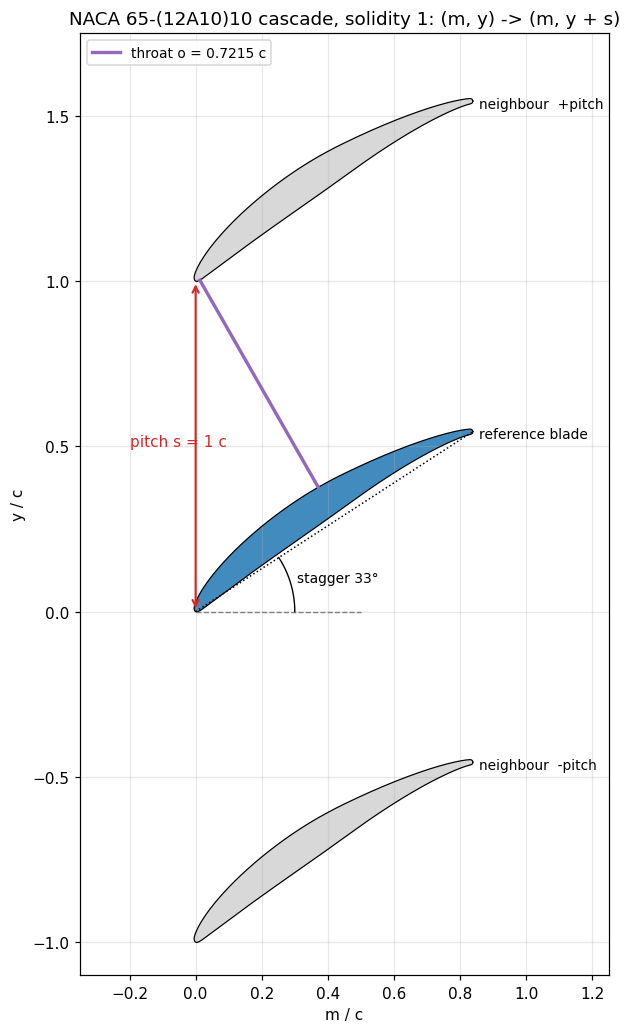

In [26]:
translation = coords.periodic_translation
loop = geo.closed_loop(coords.suction_surface, coords.pressure_surface)
print(f"pitch s = c / solidity = {coords.pitch:g} c;  throat o = {coords.throat_opening:.5f} c, o/s = {final.throat_over_pitch:.5f}")

fig, ax = plt.subplots(figsize=(9, 9.5))
for k, label in ((-1, "neighbour  -pitch"), (0, "reference blade"), (1, "neighbour  +pitch")):
    shifted = loop + k * translation
    ax.fill(*shifted.T, color="tab:blue" if k == 0 else "0.75", alpha=0.85 if k == 0 else 0.6, lw=0)
    ax.plot(*shifted.T, color="k", lw=0.8)
    ax.annotate(label, shifted[np.argmax(shifted[:, 0])] + np.array([0.02, -0.02]), fontsize=9)
throat = np.array([coords.throat_point_reference, coords.throat_point_neighbor])
ax.plot(*throat.T, "-", color="tab:purple", lw=2.2, label=f"throat o = {coords.throat_opening:.4f} c")
ax.annotate("", xy=LE + translation, xytext=LE, arrowprops=dict(arrowstyle="<->", color="tab:red", lw=1.4))
ax.annotate(f"pitch s = {coords.pitch:g} c", LE + 0.5 * translation + np.array([-0.2, 0.0]), color="tab:red", fontsize=10)
ax.plot(*np.array([LE, TE]).T, ":", color="k", lw=1.0)
ax.plot([LE[0], LE[0] + 0.5], [LE[1], LE[1]], "--", color="0.5", lw=0.9)
ax.plot(LE[0] + 0.3 * np.cos(arc), LE[1] + 0.3 * np.sin(arc), color="k", lw=0.9)
ax.annotate(f"stagger {math.degrees(final.stagger):.0f}°", (LE[0] + 0.32 * np.cos(0.5 * final.stagger),
            LE[1] + 0.32 * np.sin(0.5 * final.stagger)), fontsize=9)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-0.35, 1.25); ax.set_ylim(-1.1, 1.75)
ax.set_xlabel("m / c"); ax.set_ylabel("y / c")
ax.set_title(f"{designation} cascade, solidity {spec.solidity:g}: (m, y) -> (m, y + s)")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

### 13.2 Blade-to-blade coordinates

The solver works in $(m, y)$:

- $m$ is the **meridional** coordinate, measured along the stream surface in the meridional plane (axial in this planar cascade);
- $y$ is the **physical tangential distance**.

On a constant-radius cylindrical stream surface, at radius $r$ with tangential angle $\theta$,

$$y = r\,\theta ,$$

so unrolling the cylinder gives a plane. The flat cascade is that **unwrapped constant-radius blade-to-blade surface**: the blades repeat every $\Delta\theta = 2\pi/Z$, which is the pitch $s = r\,\Delta\theta$ in $y$. Aungier's equations are written in $(m, \theta)$ with the stream-sheet radius $r(m)$ and thickness $b(m)$. The planar cascade is the case $r = b = 1$ (`geometry.StreamSheet`), where $r\,d\theta = dy$ and the grid angle obeys $\tan\beta = r\,d\theta/dm = dy/dm$ (Eq. 5-3).

### 13.3 Upstream and downstream extensions: why the side boundaries are curved

The solution domain extends one chord upstream and one chord downstream of the blade (Aungier 2003, Sec. 5.3, Fig. 5-3). There the side boundaries do not touch a blade, and the conditions on them follow Aungier (Sec. 5.3, pp. 86–87):

- **Periodicity.** Outside the blade passage the two side boundaries are periodic counterparts, the same physical line one pitch apart. The flow repeats every passage, so their points are treated like interior points (Eqs. 5-29 to 5-32).
- **Far boundaries.** Uniform flow could be imposed far upstream and downstream ($\psi$ linear across the passage). Aungier notes that the numerical analysis is more reliable with a less stringent condition: a constant flow angle on those boundaries.
- **The milder condition.** If the side-boundary geometry is built so that its grid angle $\beta$ equals the local flow angle there, the condition becomes
$$\frac{\partial \psi}{\partial \xi} = \cos\beta\,\frac{\partial \psi}{\partial m} = 0 \qquad \text{(Eq. 5-33)},$$
  where $\xi$ is the distance along the constant-$\eta$ grid line ($dm = \cos\beta\,d\xi$). The grid line runs along the flow, so it is locally a streamline and $\psi$ does not change along it.
- **How $\beta$ is assigned.** Aungier typically varies $\beta$ uniformly along the side boundary:
  - upstream: $\beta_{in} \rightarrow \kappa_{LE}$ (far upstream flow angle to the LE blade angle);
  - downstream: $\kappa_{TE} \rightarrow \beta_{out}$.

  The boundary geometry then follows by integrating Eq. 5-3, $\tan\beta = dy/dm$, with $\beta_0 = \beta_1$ outside the passage.

Therefore, **if $\beta$ varies with $m$, the side boundary is curved**, not a straight line. This is intentional: it is part of the coordinate and grid construction, not a geometric defect.

### 13.4 Upstream extension

`grid.make_passage_boundaries` builds the side boundaries exactly this way, with the angle linear in $m$ and the integral in closed form:

$$\beta(m) = \kappa_{LE} + \frac{m - m_{LE}}{m_{in} - m_{LE}}\,(\beta_{in} - \kappa_{LE}), \qquad y(m) = y_{LE} + (m - m_{LE})\,\overline{\tan\beta}, \quad \overline{\tan\beta} = \frac{\ln(\cos\beta / \cos\kappa_{LE})}{\kappa_{LE} - \beta} ,$$

the mean of $\tan$ over the angles between, which is the exact integral of the linear-angle law. In general $\beta_{in} \neq \kappa_{LE}$, so $\tan\beta(m)$ changes along the extension and the integral is curved. The upper side line is the lower one moved one pitch. The inlet angle is a flow input (`config.FlowConditions.inlet_angle_deg`); 45° is used here for illustration.

kappa_LE = 48.080 deg, beta_in = 45 deg, kappa_TE = 17.920 deg
upstream extension: m from -1.000 to m_LE = 0.000 c, 95 samples; beta from 45.000 to 48.080 deg
check dy/dm = tan(beta) on the closed-form line (central differences): largest difference 2.7e-07
the line bends away from the straight kappa_LE tangent by up to 0.0579 c at m_in


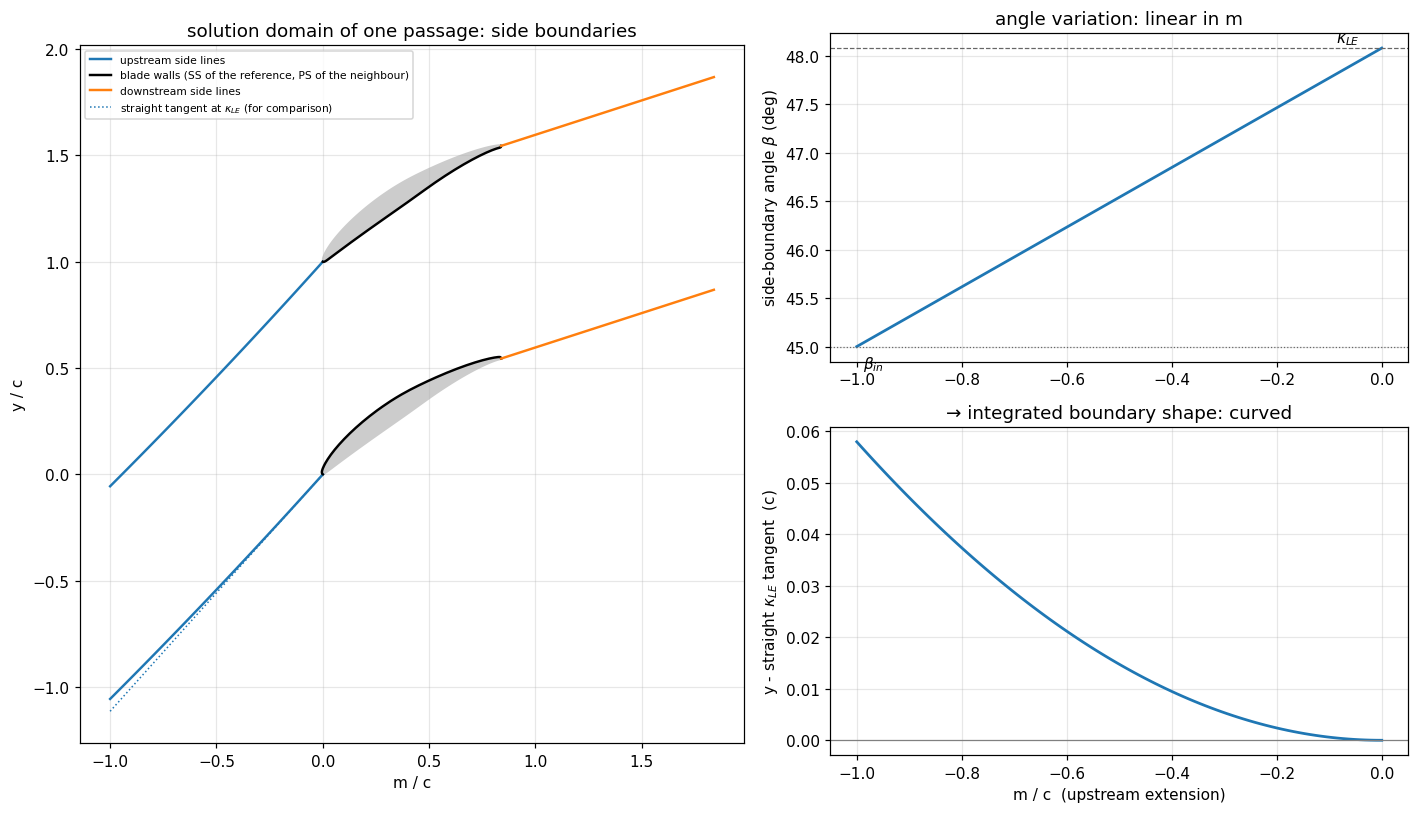

In [27]:
from potential_flow_solver import grid as gr
from potential_flow_solver.config import GridSettings

settings = GridSettings(n_passage=80, n_eta=21)          # one-chord extensions (the defaults)
inlet_angle_deg = 45.0                                    # illustrative far-inlet flow angle
boundaries = gr.make_passage_boundaries(final, settings, math.radians(inlet_angle_deg))     # no exit angle given
b = boundaries
up_m, up_y = b.upstream_lower_boundary.T
straight_up = up_y[-1] + (up_m - b.m_le) * math.tan(final.kappa_le)        # the tangent at kappa_LE through the LE
slope_check = np.max(np.abs(np.gradient(up_y, up_m)[1:-1] - np.tan(b.upstream_beta[1:-1])))
print(f"kappa_LE = {math.degrees(final.kappa_le):.3f} deg, beta_in = {inlet_angle_deg:g} deg, kappa_TE = {math.degrees(final.kappa_te):.3f} deg")
print(f"upstream extension: m from {b.m_in:.3f} to m_LE = {b.m_le:.3f} c, {len(up_m) - 1} samples; "
      f"beta from {math.degrees(b.upstream_beta[0]):.3f} to {math.degrees(b.upstream_beta[-1]):.3f} deg")
print(f"check dy/dm = tan(beta) on the closed-form line (central differences): largest difference {slope_check:.1e}")
print(f"the line bends away from the straight kappa_LE tangent by up to {np.max(np.abs(up_y - straight_up)):.4f} c at m_in")

fig = plt.figure(figsize=(13, 7.5))
layout = fig.add_gridspec(2, 2, width_ratios=(1.15, 1.0))
ax_d = fig.add_subplot(layout[:, 0])
ax_b, ax_o = fig.add_subplot(layout[0, 1]), fig.add_subplot(layout[1, 1], sharex=None)
for k in (0, 1):
    ax_d.fill(*(loop + k * translation).T, color="0.8", lw=0)
for line, color, label in ((b.upstream_lower_boundary, "tab:blue", "upstream side lines"),
                           (b.lower_blade_boundary, "k", "blade walls (SS of the reference, PS of the neighbour)"),
                           (b.downstream_lower_boundary, "tab:orange", "downstream side lines")):
    ax_d.plot(*line.T, color=color, lw=1.6, label=label)
ax_d.plot(*b.upstream_upper_boundary.T, color="tab:blue", lw=1.6)
ax_d.plot(*b.upper_blade_boundary.T, color="k", lw=1.6)
ax_d.plot(*b.downstream_upper_boundary.T, color="tab:orange", lw=1.6)
ax_d.plot(up_m, straight_up, ":", color="tab:blue", lw=1.0, label="straight tangent at $\\kappa_{LE}$ (for comparison)")
ax_d.set_aspect("equal", adjustable="box")
ax_d.set_xlabel("m / c"); ax_d.set_ylabel("y / c")
ax_d.set_title("solution domain of one passage: side boundaries")
ax_d.legend(fontsize=7, loc="upper left")
ax_b.plot(up_m, np.degrees(b.upstream_beta), color="tab:blue", lw=1.8, label="$\\beta(m)$, upstream")
ax_b.axhline(math.degrees(final.kappa_le), color="0.4", lw=0.8, ls="--")
ax_b.axhline(inlet_angle_deg, color="0.4", lw=0.8, ls=":")
ax_b.annotate("$\\kappa_{LE}$", (b.m_le, math.degrees(final.kappa_le)), textcoords="offset points", xytext=(-30, 4))
ax_b.annotate("$\\beta_{in}$", (b.m_in, inlet_angle_deg), textcoords="offset points", xytext=(4, -14))
ax_b.set_ylabel("side-boundary angle $\\beta$ (deg)")
ax_b.set_title("angle variation: linear in m")
ax_o.plot(up_m, up_y - straight_up, color="tab:blue", lw=1.8)
ax_o.axhline(0.0, color="0.5", lw=0.8)
ax_o.set_xlabel("m / c  (upstream extension)")
ax_o.set_ylabel("y - straight $\\kappa_{LE}$ tangent  (c)")
ax_o.set_title("→ integrated boundary shape: curved")
fig.tight_layout()
plt.show()

Reading left to right: the angle varies linearly in $m$, $\tan\beta = dy/dm$ follows (checked on the closed-form line above), and the integrated side line bends away from the straight $\kappa_{LE}$ tangent. The offset is small because $\beta_{in}$ and $\kappa_{LE}$ differ by only a few degrees, but it is not zero: the upstream side boundary is curved.

### 13.5 Downstream extension: the current initialization

At the present, pre-solver stage the downstream exit angle has not been determined: no potential-flow solution and no Kutta iteration exist yet (`solver.solve` and `kutta.py` are stubs). The current code path is `grid.make_passage_boundaries` / `grid.make_grid` without an exit angle. `grid.py` then takes

$$\beta_{out,\,initial} = \kappa_{TE} \qquad (\texttt{exit\_angle=None} \;\rightarrow\; \texttt{exit\_angle = cascade.kappa\_te}),$$

which its docstring states as "a starting value for this solver's Kutta loop, not a rule of Aungier's". With equal end angles the linear law gives $\beta(m) = \kappa_{TE}$ at every sample. The mean-tan factor is then exactly $\tan\kappa_{TE}$, so

$$\tan\beta = \text{constant}, \qquad y(m) = y_{TE} + (m - m_{TE})\tan\kappa_{TE} :$$

the initial downstream side boundary is a **straight line** in the $(m, y)$ plane. The planned solver (`solver.py`, step 0) will pass the user's `config.FlowConditions.exit_angle_guess_deg` instead. If that guess differs from $\kappa_{TE}$, even the first downstream line is curved. The cell checks the current behaviour on the arrays.

In [28]:
dn_m, dn_y = b.downstream_lower_boundary.T
straight_dn = dn_y[0] + (dn_m - b.m_te) * math.tan(final.kappa_te)
print(f"exit angle supplied: none  ->  boundaries.exit_angle = {math.degrees(b.exit_angle):.6f} deg;  "
      f"cascade.kappa_te = {math.degrees(final.kappa_te):.6f} deg;  identical: {b.exit_angle == final.kappa_te}")
print(f"downstream_beta: {len(b.downstream_beta)} samples, largest |beta - kappa_te| = {np.max(np.abs(b.downstream_beta - final.kappa_te)):.1e} rad")
print(f"downstream lower line against y_TE + (m - m_TE) tan(kappa_te): largest |dy| = {np.max(np.abs(dn_y - straight_dn)):.1e} c")
print(f"second differences of y along it: largest {np.max(np.abs(np.diff(dn_y, 2))):.1e} c  (zero for a straight line)")

exit angle supplied: none  ->  boundaries.exit_angle = 17.920315 deg;  cascade.kappa_te = 17.920315 deg;  identical: True
downstream_beta: 96 samples, largest |beta - kappa_te| = 0.0e+00 rad
downstream lower line against y_TE + (m - m_TE) tan(kappa_te): largest |dy| = 0.0e+00 c
second differences of y along it: largest 2.2e-16 c  (zero for a straight line)


**The currently straight downstream extension is only the initial pre-solver geometry. It is not the final physical/numerical assumption.**

### 13.6 What will happen once the solver is implemented

The final downstream flow angle is not known a priori. As Aungier points out (Sec. 5.3, p. 86), the upstream and downstream flow angles are not independent: for a given inlet flow, the potential-flow solution must also satisfy the **trailing-edge Kutta condition**. The pressures, and so the velocities, on the two sides of the blade must be equal at the TE (Eq. 5-34). Aungier adjusts the discharge angle iteratively as part of the solution process until that condition holds (p. 87). The planned solver loop (`solver.py`, steps 1–9) is conceptually:

```text
initial beta_out guess
→ build / update the downstream extension      grid.make_grid, then grid.rebuild_exit
→ solve psi                                     coefficients, discretization, linear_solver
→ evaluate the TE / downstream flow             flow
→ enforce the Kutta condition                   kutta.kutta_error
→ update beta_out                               kutta.next_exit_angle
→ rebuild the downstream extension              grid.rebuild_exit
→ repeat until converged                        convergence.kutta_converged
```

Of these, only the grid steps exist today. As soon as $\beta_{out} \neq \kappa_{TE}$, the downstream angle runs $\kappa_{TE} \rightarrow \beta_{out}$ along the extension, $\tan\beta(m)$ is no longer constant, and the downstream side boundary becomes curved. This is the same construction as upstream, and consistent with Aungier's statement that the downstream angle is adjusted iteratively to satisfy the Kutta condition rather than prescribed independently.

### 13.7 Initial and illustrative updated downstream extension

`grid.rebuild_exit` already performs the grid side of one Kutta update: it turns only the exit extension to a new discharge angle. Below it is applied to a **hypothetical** $\beta_{out} = \kappa_{TE} + 5°$. That is a purely illustrative diagnostic copy, **not a solved result**: no flow has been computed.

rebuild_exit against a fresh build at the same angle: largest difference 0.0e+00;  inlet extension and walls changed by 0.0e+00
illustrative exit line: beta 17.920 -> 22.920 deg, 0.0492 c from the initial straight line at m_out


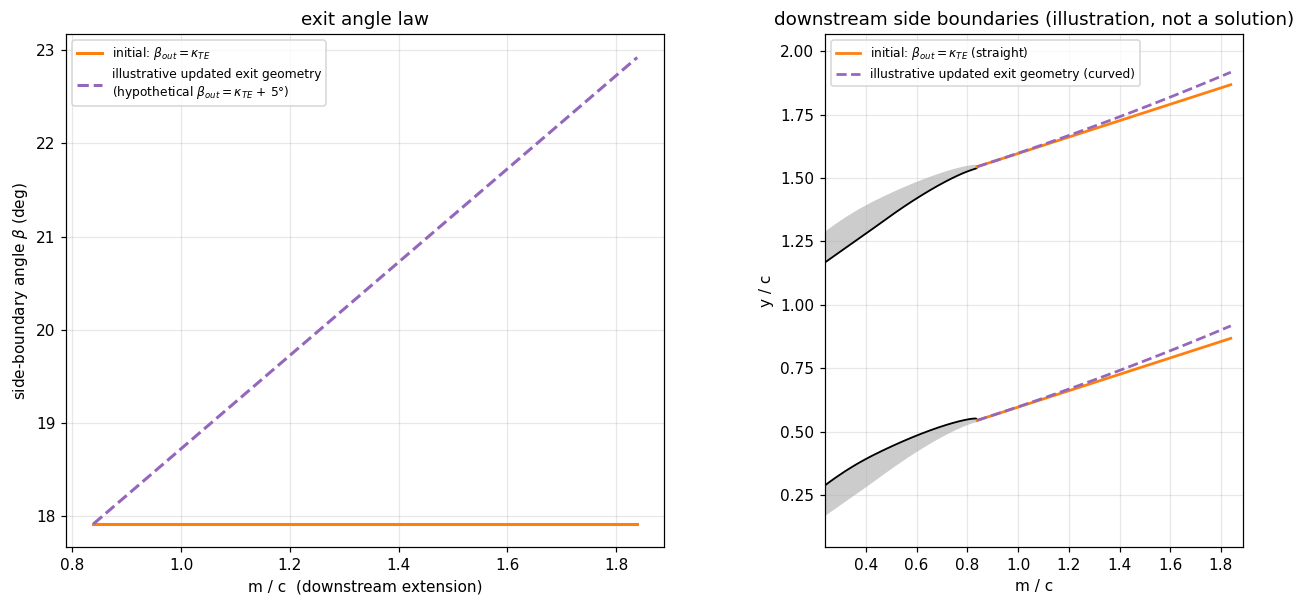

In [29]:
hypothetical_exit = final.kappa_te + math.radians(5.0)                 # illustrative only, NOT a Kutta solution
updated = gr.rebuild_exit(boundaries, hypothetical_exit)
fresh = gr.make_passage_boundaries(final, settings, math.radians(inlet_angle_deg), hypothetical_exit)
same = max(np.max(np.abs(updated.downstream_lower_boundary - fresh.downstream_lower_boundary)),
           np.max(np.abs(updated.downstream_beta - fresh.downstream_beta)))
unchanged = max(np.max(np.abs(updated.upstream_lower_boundary - boundaries.upstream_lower_boundary)),
                np.max(np.abs(updated.lower_blade_boundary - boundaries.lower_blade_boundary)))
print(f"rebuild_exit against a fresh build at the same angle: largest difference {same:.1e};  "
      f"inlet extension and walls changed by {unchanged:.1e}")
print(f"illustrative exit line: beta {math.degrees(updated.downstream_beta[0]):.3f} -> {math.degrees(updated.downstream_beta[-1]):.3f} deg, "
      f"{np.max(np.abs(updated.downstream_lower_boundary[:, 1] - straight_dn)):.4f} c from the initial straight line at m_out")

fig, (ax_b, ax_g) = plt.subplots(1, 2, figsize=(13, 5.6), width_ratios=(1.0, 1.25))
ax_b.plot(dn_m, np.degrees(boundaries.downstream_beta), color="tab:orange", lw=2.0, label="initial: $\\beta_{out} = \\kappa_{TE}$")
ax_b.plot(dn_m, np.degrees(updated.downstream_beta), "--", color="tab:purple", lw=2.0,
          label="illustrative updated exit geometry\n(hypothetical $\\beta_{out} = \\kappa_{TE}$ + 5°)")
ax_b.set_xlabel("m / c  (downstream extension)"); ax_b.set_ylabel("side-boundary angle $\\beta$ (deg)")
ax_b.set_title("exit angle law"); ax_b.legend(fontsize=8)
for k in (0, 1):
    ax_g.fill(*(loop + k * translation).T, color="0.8", lw=0)
ax_g.plot(*boundaries.lower_blade_boundary.T, color="k", lw=1.2)
ax_g.plot(*boundaries.upper_blade_boundary.T, color="k", lw=1.2)
for item, style, color, label in ((boundaries, "-", "tab:orange", "initial: $\\beta_{out} = \\kappa_{TE}$ (straight)"),
                                  (updated, "--", "tab:purple", "illustrative updated exit geometry (curved)")):
    ax_g.plot(*item.downstream_lower_boundary.T, style, color=color, lw=1.8, label=label)
    ax_g.plot(*item.downstream_upper_boundary.T, style, color=color, lw=1.8)
ax_g.set_aspect("equal", adjustable="box")
ax_g.set_xlim(b.m_te - 0.6, b.m_out + 0.05); ax_g.set_ylim(dn_y[0] - 0.5, updated.downstream_upper_boundary[-1, 1] + 0.15)
ax_g.set_xlabel("m / c"); ax_g.set_ylabel("y / c")
ax_g.set_title("downstream side boundaries (illustration, not a solution)")
ax_g.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

Only the exit side moves. The inlet extension and the blade walls are unchanged, as are the grid stations for a `Grid`, and the result equals a fresh build at that angle. Each Kutta update of the future solver will bend the downstream boundaries in this way, by whatever angle the Kutta condition requires.

---

**Notebook map.**

| Sections | Content |
|---|---|
| 1–8 | NACA 65 construction and the C1 analysis |
| 9 | C2 quintic representation: the same legacy geometry, with improved derivative continuity |
| 10 | Robust adaptive LE construction: a separate geometry redesign |
| 11 | Parametric robustness: thickness and camber sweeps, adaptive-anchor behaviour |
| 12 | The final robust, solver-ready single blade |
| 13 | Periodic cascade and solver domain: the extensions and Aungier's boundary-condition reasoning |